# M22 · Récurrences vectorielles, rayon spectral et normes de matrices — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m22_recurrences/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M22.1 à M22.10, M22.16 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M22.19 | Les états d'une récurrence linéaire avec entrée · `linear_system_states` | 🔨 | ★ | 25 |
|  | M22.20 | Les normes induites ‖·‖₁, ‖·‖∞ et ‖·‖₂ · `operator_norm` | 🔨 | ★★ | 30 |
|  | M22.21 | Les normes des produits cumulés, et leur majoration · `product_norms` | 🔨 | ★ | 25 |
|  | M22.22 | `np.linalg.eigvals` et `np.linalg.norm` : rayon spectral et normes de matrices tirées au hasard, et ρ ≤ ‖A‖ | 📦 | ★ | 15 |
| B | M22.23 | Prédire l'allure de ‖Aᵗ‖₂ pour une matrice non normale de rayon spectral 0,8, puis tracer | 🔮 | ★ | 20 |
|  | M22.24 | Des produits de matrices aléatoires : le taux de croissance (1/n) ln ‖Aₙ ⋯ A₁‖ | 🔬 | ★★ | 25 |
|  | M22.25 | Les spirales d'une récurrence 2 × 2 à valeurs propres complexes, selon leur module | 🎨 | ★ | 20 |
| C | M22.26 | Chasse à l'erreur : ρ(A) pris pour ‖A‖, un produit de jacobiennes dans le mauvais ordre, un seuil appliqué bloc par bloc | 🐛 | ★ | 25 |
|  | M22.27 | Un test de propriété : ‖AB‖ ≤ ‖A‖ ‖B‖ et ρ(A) ≤ ‖A‖ sur des matrices tirées au hasard | 🛠️ | ★ | 30 |
| D | M22.28 | Défi : une matrice 3 × 3 à coefficients dans [−3, 3], de rayon spectral 0,85, dont une puissance a une norme ‖·‖₂ supérieure à 100 | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une population avec des arrivées, une réponse impulsionnelle, une rotation-homothétie, trois rayons spectraux, une croissance transitoire, trois normes induites, des équipements qui s'usent, des jacobiennes de Hénon, la sensibilité d'un capital, un vecteur fait de blocs, et un pont vers la convention ligne.
- Écrire les trois fonctions de `mymath/recurrence.py` (`linear_system_states`, `operator_norm`, `product_norms`) et les tester.
- Comparer rayon spectral et normes sur des matrices tirées au hasard, prédire et tracer une croissance transitoire, mesurer le taux de croissance d'un produit de matrices aléatoires, dessiner des spirales, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t$ (colonnes) : $\mathbf{x}_t = \mathbf{A}^t\mathbf{x}_0 + \sum_{k<t}\mathbf{A}^{t-1-k}\mathbf{B}\mathbf{u}_k$ ; $h_k = \mathbf{C}\mathbf{A}^k\mathbf{B}$ et, pour $\mathbf{x}_0 = \mathbf{0}$, $y_{t+1} = (\mathbf{h} * \mathbf{u})_t$. $z = r\,e^{i\theta}$, $z^t = r^te^{it\theta}$ ; $\begin{pmatrix} a & -b \\ b & a \end{pmatrix} = r\mathbf{R}_\theta$ ; une matrice réelle $2 \times 2$ à valeurs propres complexes a pour module $\sqrt{\det\mathbf{A}}$. $\rho(\mathbf{A}) = \max\lvert\lambda_i\rvert$ ; $\mathbf{A}^t \to \mathbf{0} \iff \rho(\mathbf{A}) < 1$ ; une matrice non normale ($\mathbf{A}^\top\mathbf{A} \ne \mathbf{A}\mathbf{A}^\top$) peut grandir d'abord. $\lVert\mathbf{A}\rVert_1$ : colonnes ; $\lVert\mathbf{A}\rVert_\infty$ : lignes ; $\lVert\mathbf{A}\rVert_2 = s_{\max}$ ; $\lVert\mathbf{A}\mathbf{B}\rVert \le \lVert\mathbf{A}\rVert\,\lVert\mathbf{B}\rVert$, $\rho \le \lVert\cdot\rVert$, $\lVert\mathbf{A}^t\rVert^{1/t} \to \rho$ ; la norme de Frobenius n'est pas induite. $\mathbf{P}_t = \mathbf{A}_t\cdots\mathbf{A}_1$, $\lVert\mathbf{P}_t\rVert \le \prod \lVert\mathbf{A}_k\rVert$ ; $(1 - \varepsilon)^t \approx e^{-t\varepsilon}$ ; le signe de $\mathbb{E}[\ln a]$ décide. $\partial\mathbf{x}_T/\partial\mathbf{x}_t = \mathbf{J}_f(\mathbf{x}_{T-1})\cdots\mathbf{J}_f(\mathbf{x}_t)$ ; $\mathbf{s}_{t+1} = \mathbf{J}_t\mathbf{s}_t + \mathbf{b}_t$. Blocs : $\lVert\mathbf{w}\rVert^2 = \sum\lVert\mathbf{w}_k\rVert^2$, et $\mathbf{w}\min(1, c/\lVert\mathbf{w}\rVert)$ garde la direction.

## Partie 0 · Vérifier tes exercices papier (✏️ M22.1 à M22.10, 🔗 M22.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- un nombre complexe $a + ib$ comme la liste `[a, b]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- un angle exact en radians entre guillemets, `"pi/4"` ou `"3*pi/5"` ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (states step by step, exact fractions, NumPy)
import math
from fractions import Fraction

import numpy as np


def shape_of(shape):
    """A shape (a tuple, or that of an array) written as NumPy prints it: "(3, 4)"."""
    shape = np.shape(shape) if hasattr(shape, "shape") else shape
    return str(tuple(int(n) for n in shape))


def floats(values):
    """A vector or a matrix of exact values (fractions, floats) as nested lists of floats."""
    return np.asarray(values, dtype=float).tolist()


def power(M, t):
    """M^t by t successive products."""
    M = np.asarray(M, dtype=float)
    P = np.eye(len(M))
    for _ in range(t):
        P = M @ P
    return P


def rho(M):
    """The spectral radius: the largest modulus of the (complex) eigenvalues."""
    return float(np.abs(np.linalg.eigvals(np.asarray(M, dtype=float))).max())


def as_pi(angle):
    """An angle that is a rational multiple of pi, written exactly: "2*pi/3"."""
    q = Fraction(angle / math.pi).limit_denominator(24)
    assert abs(float(q) * math.pi - angle) < 1e-9, angle
    top = {1: "pi", -1: "-pi"}.get(q.numerator, f"{q.numerator}*pi")
    return top if q.denominator == 1 else f"{top}/{q.denominator}"


def fmul(P, Q):
    """The product of two 2 × 2 matrices of fractions."""
    return [[sum(P[i][k] * Q[k][j] for k in range(2)) for j in range(2)] for i in range(2)]


def fpow(P, t):
    """P^t for a 2 × 2 matrix of fractions, by t products."""
    R = [[Fraction(1), Fraction(0)], [Fraction(0), Fraction(1)]]
    for _ in range(t):
        R = fmul(P, R)
    return R


def transpose(P):
    return [list(row) for row in zip(*P)]


A_1 = np.array([[0.0, 1.2, 0.8], [0.4, 0.0, 0.0], [0.0, 0.6, 0.0]])                     # M22.1
B_1 = np.array([[1.0, 0.0], [0.0, 0.0], [0.0, 1.0]])
X0_1, U_1 = np.array([40.0, 20.0, 30.0]), np.array([[20.0, 10.0], [0.0, 10.0], [30.0, 0.0]])
X_1 = [X0_1]
for u in U_1:
    X_1.append(A_1 @ X_1[-1] + B_1 @ u)                                                   # step by step
FREE_1 = power(A_1, 3) @ X0_1                                                             # the free response
FORCED_1 = sum(power(A_1, 3 - 1 - k) @ B_1 @ U_1[k] for k in range(3))                   # the forced response
assert np.allclose(FREE_1 + FORCED_1, X_1[3])
DOUBLED_X3_1 = 2 * X0_1
for u in U_1:
    DOUBLED_X3_1 = A_1 @ DOUBLED_X3_1 + B_1 @ u                                              # x0 doubled, same releases
LATE_1 = sum(power(A_1, 3 - k) @ B_1 @ U_1[k] for k in range(3))                         # A^(t−k): one power too many
B_SWAP_1 = np.array([[1.0, 0.0], [0.0, 1.0], [0.0, 0.0]])                                  # the second input misplaced
A_2, B_2, C_2 = np.array([[0.4, 0.0], [0.4, 0.3]]), np.array([1.0, 0.0]), np.array([0.0, 0.6])   # M22.2
U_2 = [10.0, 0.0, 20.0, 5.0]
H_2 = [float(C_2 @ power(A_2, k) @ B_2) for k in range(40)]                               # h_k = C A^k B
Y_2 = np.convolve(H_2[:12], U_2)                                                           # y_(t+1) = (h * u)_t


def simulate_2(x0, rains, steps=8):
    """The states x_0, ..., x_steps of the basins (rains then zeros), step by step."""
    states = [np.asarray(x0, dtype=float)]
    for t in range(steps):
        states.append(A_2 @ states[-1] + B_2 * (rains[t] if t < len(rains) else 0.0))
    return states


X_2 = simulate_2([0.0, 0.0], U_2)
assert np.allclose([C_2 @ x for x in X_2[1:6]], Y_2[:5])                                 # y_1, ..., y_5 twice
I_MINUS_A_2 = [[1 - Fraction(2, 5), Fraction(0)], [-Fraction(2, 5), 1 - Fraction(3, 10)]]
(P_2, Q_2), (R_2, S_2) = I_MINUS_A_2
INVERSE_2 = [[S_2 / (P_2 * S_2 - Q_2 * R_2), -Q_2 / (P_2 * S_2 - Q_2 * R_2)],
             [-R_2 / (P_2 * S_2 - Q_2 * R_2), P_2 / (P_2 * S_2 - Q_2 * R_2)]]
C_FRACTION_2, B_FRACTION_2 = [Fraction(0), Fraction(3, 5)], [Fraction(1), Fraction(0)]
TOTAL_2 = sum(C_FRACTION_2[i] * INVERSE_2[i][j] * B_FRACTION_2[j] for i in range(2) for j in range(2))
assert abs(float(TOTAL_2) - sum(H_2)) < 1e-12                                              # Σ h_k = C (I − A)⁻¹ B
EFFECT_2 = float(C_2 @ simulate_2([0.0, 10.0], U_2)[4] - C_2 @ X_2[4])                    # y₄ with and without x₀
DOUBLED_2 = bool(np.allclose([C_2 @ x for x in simulate_2([0.0, 0.0], [2 * u for u in U_2])],
                             [2 * (C_2 @ x) for x in X_2]))
M_3 = 0.3 * np.array([[-1.0, -math.sqrt(3)], [math.sqrt(3), -1.0]])                       # M22.3
X0_3 = np.array([2.0, 0.0])
EIG_3 = np.linalg.eigvals(M_3)
MU_3 = complex(EIG_3[np.argmax(EIG_3.imag)])                                               # Im μ > 0
THETA_3 = math.atan2(MU_3.imag, MU_3.real)
X5_3 = power(M_3, 5) @ X0_3
A_4 = np.array([[0.2, 0.4], [0.6, 0.0]])                                                   # M22.4
B_4 = np.array([[2.0, -3.0], [1.0, -1.0]])
C_4 = np.array([[0.0, -1.0], [1.69, 0.0]])


def behaviour_4(M):
    """1: the powers tend to 0; 2: bounded, not to 0; 3: not bounded (read on the first 600 powers)."""
    P, norms = np.eye(2), []
    for _ in range(600):
        P = M @ P                                                                           # M^t, one product per step
        norms.append(np.linalg.norm(P, 2))
    if norms[-1] < 1e-9:
        return 1
    return 2 if max(norms) < 1e3 else 3


A_5 = [[Fraction(2, 3), Fraction(3)], [Fraction(0), Fraction(2, 3)]]                     # M22.5
B_5 = [[Fraction(2, 3), Fraction(3)], [Fraction(0), Fraction(1, 3)]]
C_5 = {t: fpow(A_5, t)[0][1] for t in range(1, 41)}                                       # c_t = (A^t)_12, exact
RHO_5 = max(abs(A_5[0][0]), abs(A_5[1][1]))                                                # triangular: the diagonal
assert abs(float(RHO_5) - rho(np.array(A_5, dtype=float))) < 1e-6
A_6, X_6 = np.array([[1.0, 2.0], [-1.0, 2.0]]), np.array([2.0, -3.0])                     # M22.6
N2_6 = float(np.sqrt(np.linalg.eigvalsh(A_6.T @ A_6)[-1]))
NORMS_6 = [float(np.abs(A_6).sum(axis=0).max()), N2_6, float(np.abs(A_6).sum(axis=1).max())]   # 1, 2, ∞
Y_6 = X_6
for _ in range(5):
    Y_6 = A_6 @ Y_6                                                                         # five products
A_7, N_7 = np.array([0.985, 0.93, 0.65]), 12                                               # M22.7
EPS_7, B_7 = 1 - A_7, np.array([0.012, 0.056, 0.28])
X2_7 = np.ones(3)
for _ in range(2):
    X2_7 = A_7 * X2_7 + B_7


def henon_8(p):
    """f(x, y) = (1 − 1.4 x² + y, 0.3 x)."""
    return np.array([1 - 1.4 * p[0] ** 2 + p[1], 0.3 * p[0]])


def jac_8(p):
    """Its jacobian, one row per output coordinate."""
    return np.array([[-2.8 * p[0], 1.0], [0.3, 0.0]])


X_8 = [np.zeros(2)]                                                                        # M22.8
for _ in range(3):
    X_8.append(henon_8(X_8[-1]))
J_8 = [jac_8(x) for x in X_8[:3]]
D_8 = J_8[2] @ J_8[1] @ J_8[0]                                                             # the last step on the left
NO_Y_8 = np.zeros(2)
for _ in range(3):
    NO_Y_8 = np.array([1 - 1.4 * NO_Y_8[0] ** 2, 0.3 * NO_Y_8[0]])                         # without the + y
DELTA_8 = np.array([0.01, 0.0])
MOVED_8 = DELTA_8
for _ in range(3):
    MOVED_8 = henon_8(MOVED_8)                                                              # the true x₃ from (0.01, 0)
BETA_9, X0_9, PAY_9 = Fraction(35, 1000), Fraction(2500), 400                             # M22.9


def x4_9(beta):
    """x_4 for the rate beta, step by step (exact)."""
    x = X0_9
    for _ in range(4):
        x = (1 + beta) * x + PAY_9
    return x


X_9 = [X0_9]
for _ in range(4):
    X_9.append((1 + BETA_9) * X_9[-1] + PAY_9)
EARLY_9 = [X0_9]
for _ in range(4):
    EARLY_9.append((1 + BETA_9) * (EARLY_9[-1] + PAY_9))                                     # the payment before the interest
J_9 = 1 + BETA_9                                                                           # ∂f/∂x
B_9 = X_9[:4]                                                                              # ∂f/∂β at x_t
TERMS_9 = [J_9 ** (3 - k) * B_9[k] for k in range(4)]
S_9 = sum(TERMS_9)
s_9 = Fraction(0)
for t in range(4):
    s_9 = J_9 * s_9 + B_9[t]                                                               # s_(t+1) = J s_t + b_t
assert s_9 == S_9
W_10 = [np.array([2.0, -2.0, 2.0, 2.0]), np.array([2.0, 3.0, -6.0]), np.array([-4.0])]    # M22.10
C_10 = 5
NORMS_10 = [float(np.linalg.norm(w)) for w in W_10]
GLOBAL_10 = float(np.sqrt(sum(n ** 2 for n in NORMS_10)))
WHOLE_10 = [w * min(1.0, C_10 / GLOBAL_10) for w in W_10]                                  # the whole
EACH_10 = [w * min(1.0, C_10 / np.linalg.norm(w)) for w in W_10]                           # block by block
FLAT_10, FLAT_EACH_10 = np.concatenate(W_10), np.concatenate(EACH_10)
COSINE_10 = float(FLAT_10 @ FLAT_EACH_10 / (np.linalg.norm(FLAT_10) * np.linalg.norm(FLAT_EACH_10)))
A_16 = np.array([[0.2, 0.6], [-0.4, 0.3]])                                                 # M22.16
B_16, X0_16, U_16 = np.array([[1.0, -2.0]]), np.array([[4.0, -1.0]]), [1.0, 0.0, -1.0]
B_ROW_16 = np.zeros((2, 3))                                                                # (m, n) for m = 2, n = 3
assert (np.zeros((1, 2)) @ B_ROW_16).shape == (1, 3)
ROWS_16, COLUMNS_16 = [X0_16], [X0_16]
for u in U_16:
    ROWS_16.append(ROWS_16[-1] @ A_16 + u * B_16)                                          # x A + u B
    COLUMNS_16.append((A_16 @ COLUMNS_16[-1].T + u * B_16.T).T)                            # the column convention
ROWS_16, COLUMNS_16 = np.vstack(ROWS_16), np.vstack(COLUMNS_16)
A_COL_16 = A_16.T
assert all(np.allclose(ROWS_16[t + 1], A_COL_16 @ ROWS_16[t] + B_16[0] * U_16[t]) for t in range(3))
JAC_16 = np.array([[(np.eye(2)[i] @ A_16)[j] for i in range(2)] for j in range(2)])         # row j: ∂(xA)_j/∂x_i
ROW_FORMULA_16 = bool(np.allclose(ROWS_16[3], X0_16 @ power(A_16, 3)
                                  + sum(U_16[k] * B_16 @ power(A_16, 3 - 1 - k) for k in range(3))))

**Ex M22.1 — Une population à trois classes d'âge, avec des arrivées : trois pas à la main, et la solution écrite avec les puissances**

In [3]:
wbm.record("M22.1a", floats(X_1[1]), decimals=2,
           mistakes={"x₁ = A x₀ + B u₀ : les lâchers de l'année 0 comptent aussi": floats(A_1 @ X0_1),
                     "B range la première entrée parmi les jeunes, la seconde parmi les oiseaux de deux ans":
                         floats(A_1 @ X0_1 + B_SWAP_1 @ U_1[0])})
wbm.record("M22.1b", floats(X_1[2]), decimals=2,
           mistakes={"chaque pas ajoute B uₜ, même quand une seule des deux entrées est non nulle":
                         floats(A_1 @ X_1[1])})
wbm.record("M22.1c", floats(X_1[3]), decimals=2,
           mistakes={"dans la formule, uₖ est porté par A^(t−1−k), pas par A^(t−k)": floats(FREE_1 + LATE_1),
                     "x₃ part de x₀ : la réponse libre compte aussi": floats(FORCED_1)})
wbm.record("M22.1d", floats(power(A_1, 2) @ B_1), decimals=2,
           mistakes={"u₀ sert à calculer x₁ : de x₁ à x₃, il reste encore des pas": floats(A_1 @ B_1),
                     "uₖ est porté jusqu'à x₃ par A^(3−1−k), pas par A^(3−k)": floats(power(A_1, 3) @ B_1)})
wbm.record("M22.1e", floats(FREE_1), decimals=2,
           mistakes={"la réponse libre de x₃ applique A une fois par pas, depuis x₀": floats(power(A_1, 2) @ X0_1)})
wbm.record("M22.1f", floats(FORCED_1), decimals=2,
           mistakes={"uₖ est porté par A^(t−1−k) : la dernière entrée n'est multipliée par aucune puissance de A":
                         floats(LATE_1)})
wbm.record("M22.1g", sum(1 for k in range(10) if 10 - 1 - k >= 0), mistakes={"un terme par entrée reçue avant le pas 10, u₀ compris": 9,
                     "u₁₀ sert à calculer x₁₁, pas x₁₀": 11})
wbm.record("M22.1h", bool(np.allclose(DOUBLED_X3_1, 2 * X_1[3])), mistakes={"avec des entrées, seule la réponse libre est proportionnelle à x₀": True})

WBM_ANSWER {"decimals": 2, "element_coarse": [["b858771291a0d09c9281423e50658885ca2210e63ea9a1c2f76bdb267f22d578"], ["ffa1b9c72df000facb34898595cc7cb817b6a8311333e6ffc2b1425ad487e31b"], ["2a23f6baa81cf9327a74ac65568b2891f7ca390473c7ee7db6a0b25cfd832e06"]], "element_coarse_any": [["f023728b8174c01fe188e9ff53f2808298b1b693facb55e665c906369939017d"], ["35db3f88a3dd8214dfa56382f2788491fd2dc6de01d2e1cb67594cdc03da6c66"], ["82b2131c70306b26e85e81285c543961c8dbc254e7367229404410bbfc8364ea"]], "element_hashes": ["a50376d8d8015398bd10655b33f3b1ea7934c6116a30705f262006d4c8d8f66f", "a7f352680fef0c4c3f9cce2786f25eff54aabf6e2e144a01cec5b1b1d94b8046", "d23a3fdfe3296ba7f31f72ea6b16b1fd8a3aeb23125873353a69bd68566ec7a5"], "hash": "ea3e5f85b303f7a4af0b316f156011e97be23c081d3dbb1ebe1e235fb94edc53", "id": "M22.1a", "kind": "array", "mistakes": {"818200a1aac45fb0a48699fe414ea345698035fc449f327962bd86686687b922": "x₁ = A x₀ + B u₀ : les lâchers de l'année 0 comptent aussi", "f627efab1445244b89f9c1ff4d92bb02

**Ex M22.2 — La réponse impulsionnelle de deux réservoirs en cascade, et la sortie comme convolution de l'entrée**

In [4]:
wbm.record("M22.2a", H_2[:5], decimals=4, mistakes={"la réponse impulsionnelle commence à h₀ = C B": H_2[1:6]})
wbm.record("M22.2b", Y_2[:5].tolist(), decimals=4, mistakes={"la sortie est décalée d'un pas : y_(t+1) = (h ∗ u)_t": Y_2[1:6].tolist()})
wbm.record("M22.2c", floats(X_2[3]), decimals=4, mistakes={"x₃ = A x₂ + B u₂ : la pluie du jour 2 entre dans x₃": floats(A_2 @ X_2[2])})
wbm.record("M22.2d", next(t for t in range(4, 40) if H_2[t - 1 - 3] != 0), mistakes={"dans y_t, u₃ est porté par h_(t−1−3) : regarde à partir de quel t ce coefficient est non nul": 4,
                     "une pluie du jour 3 entre dans x₄, au bassin 1 : quand atteint-elle le bassin 2 ?": 3})
wbm.record("M22.2e", str(TOTAL_2), kind="fraction", simplified=True,
           mistakes={"h_k a un facteur constant devant (0,4ᵏ − 0,3ᵏ) : il multiplie aussi la somme":
                         str(1 / (1 - Fraction(2, 5)) - 1 / (1 - Fraction(3, 10)))})
wbm.record("M22.2f", EFFECT_2, decimals=4,
           mistakes={"le rejet est 0,6 fois le niveau du bassin 2": float((power(A_2, 4) @ [0.0, 10.0])[1]),
                     "y₄ = C x₄ : compte les pas de x₀ à x₄": float(C_2 @ power(A_2, 3) @ [0.0, 10.0])})
wbm.record("M22.2g", DOUBLED_2, mistakes={"pour x₀ = 0, la sortie est linéaire en l'entrée": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["2ec81ae9c071d0cb2ec0252bd337941c404e2a6831d10ace4fc7f8a5c7f90a73"], ["af7faea3c80e58f5a3a7435570e9020ecbe19f25724abc148177886c1e11a50e"], ["ecfaae6ae7dba94ff3231d8b44e83fa053b9c4cee55ef59fc14b114651e4d3e5"], ["8d8f07e49e4c2b6fc74de0cf16f7414d7d9a65a0fbedb26b2b019e070b427300"], ["397301a6874e9c09f79dc4e4f5c75baae21490e1dff8709f37b07c3ae80271ab"]], "element_coarse_any": [[], ["e0dd36b45be52150012ffa303fda2eac9639ef4824f2e6dac333dfb292b37a9b", "15e4682b1de18d65fd35316f94c5d52305ed987f08bbc2af410d751f03e15aab"], ["4aa96238ffac6a9380f0e5d13abe5d038c0be5550e4fd893a587094909760952", "bfeafdfaa86212af8096ab53e360726c0a3c298e8eafb9fa46faa9564e4807ea"], ["c4e4feee6e258eb632f426303ad9e77ac633f64f280af5e74bfa99539ce7604b", "af577e25e83899c9a7350b9e9e0227df45019ab5675f007c51d8b4b1c1981c7e"], ["ddab647b4e6d6bf4def3afad12fff5c3f2bf7ba7dc9e9c00c9e1d11d463c614e"]], "element_hashes": ["02f135e53b93bd52d31491345f46275d3b44bc823811d7ed6d472b08f74327cf", "1b7

WBM_ANSWER {"hash": "a706525bd69dfdb8a71498e27006e51afa57a39fcf18c6c022256f7702593ed9", "id": "M22.2e", "kind": "fraction", "mistakes": {"5b12ea55b14a5c3ae9e2f27f0902dcd623f1273d04086ec63681732b39b64df8": "h_k a un facteur constant devant (0,4ᵏ − 0,3ᵏ) : il multiplie aussi la somme"}, "sign": 1, "simplified": true}
📝 Ex M22.2e : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"2": ["516376c7eac485ad884f3be1daeff884c85e1e0c16906a17d559dd1e78eaec19"]}, "decimals": 4, "hash": "a9f74d8ea7f2a22d0ffc838912371ab2893e5e9b56a99d7bb2a52c58eff16e1b", "hash_coarse": "0e7caa52b30988f9a5e1a53c315622488a123a96b89267cdead5bc2c6cf2a1aa", "id": "M22.2f", "kind": "float", "magnitude": -2, "mistakes": {"0d1199bc4c7858659c4c27feee6f41fbf70b7f46a97abb755fa2b950552c36f5": "le rejet est 0,6 fois le niveau du bassin 2", "5855fae378de4aa7091b8ef1028ecabdfae716e603ded1bd48b104fe2a8bebe7": "y₄ = C x₄ : compte les pas de x₀ à x₄"}, "sign": 1}
📝 Ex M22.2f : réponse enregistrée (float, 4 décimales).
WBM_A

**Ex M22.3 — Une matrice de rotation et d'homothétie : valeurs propres complexes, forme exponentielle, puissances**

In [5]:
wbm.record("M22.3a", [MU_3.real, MU_3.imag], decimals=4,
           mistakes={"on demande la valeur propre de partie imaginaire positive": [MU_3.real, -MU_3.imag],
                     "M est de la forme [[a, −b], [b, a]] : la partie réelle est le coefficient diagonal":
                         [-MU_3.real, MU_3.imag]})
wbm.record("M22.3b", abs(MU_3), decimals=4,
           mistakes={"le module est la racine du déterminant, pas le déterminant": abs(MU_3) ** 2,
                     "le module n'est pas la valeur absolue de la partie réelle": abs(MU_3.real)})
wbm.record("M22.3c", as_pi(THETA_3), kind="exact", angle=True,
           mistakes={"regarde le signe du cosinus de l'argument (la partie réelle)": as_pi(math.pi - THETA_3),
                     "l'argument de la valeur propre de partie imaginaire positive est dans ]0, π[":
                         as_pi(-THETA_3)})
wbm.record("M22.3d", floats(power(M_3, 3)), decimals=4, mistakes={"trois fois l'angle θ : combien de tours ?": floats(-power(M_3, 3))})
wbm.record("M22.3e", [(MU_3 ** 4).real, (MU_3 ** 4).imag], decimals=4,
           mistakes={"μ⁴ a pour argument 4θ, avec θ l'argument de μ (partie imaginaire positive) : vérifie θ, puis "
                     "le signe de sin 4θ": [(MU_3 ** 4).real, -(MU_3 ** 4).imag]})
wbm.record("M22.3f", float(np.linalg.norm(X5_3)), decimals=5,
           mistakes={"la distance est multipliée par r à chaque pas, à partir de ‖x₀‖": abs(MU_3) ** 5})
wbm.record("M22.3g", as_pi(math.atan2(X5_3[1], X5_3[0]) % (2 * math.pi)), kind="exact", angle=True,
           mistakes={"ramène l'angle dans [0, 2π[": as_pi(5 * THETA_3),
                     "cinq pas, d'un angle θ chacun": as_pi(THETA_3),
                     "cinq pas de θ chacun : vérifie θ (le signe de son cosinus)":
                         as_pi(5 * (math.pi - THETA_3) % (2 * math.pi)),
                     "ton angle est juste à 2π près : ramène-le dans [0, 2π[": as_pi(math.atan2(X5_3[1], X5_3[0]))})
wbm.record("M22.3h", bool(np.allclose(M_3.T @ M_3, np.eye(2))), mistakes={"orthogonale veut dire MᵀM = I : calcule MᵀM": True})
wbm.record("M22.3i", bool(np.allclose(M_3.T @ M_3, M_3 @ M_3.T)), mistakes={"normale veut dire MᵀM = MMᵀ : calcule les deux produits": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["941ebbacfdf2330fac079439fed4cd3e218ed5a28d1665a0be29fd85f5526750"], ["c9aabd010945dd96e450480fc8d2a17c22c99badb058db6fe30f216cefc9809b"]], "element_coarse_any": [["bb2d6c6b241207667ce7138d2e52f04a4ebc3a0d5d369916e2deafcff4c4f670", "2e376464af0c3345f947afc2f00c0aa833857539221c09acb023f42169bf2cab"], ["81ef837283cfcf6c49109f66ce7b1d3db6a5125380cbc97434641fe78e094b1f", "96315d0f271cf17e718f0bbadc5912f8f05c203a9bdc3b1296ff97563f1d61bc", "e979890e1d8ce91247c41b9a1ec736d186722ad0c870556e130f66c37a6b1576"]], "element_hashes": ["18b8f9861130f5b5194321805b9fc9430e98a99fff7fe651b1b7bc41d3d95d29", "fb016cf63c74310fc2942acf7181c05e274470e095f6faf34c046aa8ab4d34fa"], "hash": "585a727b88b129b91f229a207cb4974f8a8caf6063a11b8abce2492c478e6807", "id": "M22.3a", "kind": "array", "mistakes": {"9f9c34c0a7c504111d58269d13c7fd565c1ae69ea319c4049b05de0d215b96c9": "M est de la forme [[a, −b], [b, a]] : la partie réelle est le coefficient diagonal", "f391d00e966f

WBM_ANSWER {"angle": true, "hash": "1127668ae11a1bdb837f0acb274fb9ae05871b02921d39a0c3b3f805947e75b1", "id": "M22.3c", "kind": "exact", "mistakes": {"66b9417c81d98759198f7eb86d67af87e6f00a13ff64c81385e8663530bd5edf": "regarde le signe du cosinus de l'argument (la partie réelle)", "b9d8efd4f7b038fa7cd0857e7a47faf95f1ee5adfa32dad38f9e9b0d710dd6a1": "l'argument de la valeur propre de partie imaginaire positive est dans ]0, π["}, "rounded": {"1": "275ce0d86b9f7975912ecbde30c544de24efc41e18ab717cd908e784c7e43a9b", "2": "2465736033fccdfbee66007bb2cac13c9317451ff03468c90ddd7c957047cdea", "3": "0ce8d1ff30f189aded2a0e0ea596540a2a7b3e3b7264ae4ce6c37236302cf8a0", "4": "7006da2e63ac92c922d9db83f98c35fba049f19f29eda00977796d60d0851bdf", "5": "60b47efe190b978d682b9b944601bdafe1c763a04c7ced4ca6c1ac89e74f1655", "6": "f54ebc29f3cd187148477727d6545ae7f15dab02e7b56b05774c590355bbad61", "7": "a3eed5e12614c97cecd8bd45c96c30f37f2848dfdc305735afb8161896e4cb1c", "8": "ba2fdb3020027e4362bb46ed835b07927b406ed20

**Ex M22.4 — Le rayon spectral de trois matrices 2 × 2 non symétriques, et le comportement de leurs puissances**

In [6]:
wbm.record("M22.4a", rho(A_4), decimals=4,
           mistakes={"le rayon spectral est le PLUS GRAND module des valeurs propres":
                         float(np.abs(np.linalg.eigvals(A_4)).min()),
                     "la trace est la somme des valeurs propres, pas le rayon spectral": float(np.trace(A_4))})
wbm.record("M22.4b", rho(B_4), decimals=4,
           mistakes={"la partie réelle n'est pas le module : pour deux valeurs propres conjuguées, le produit des "
                     "valeurs propres est le carré du module": float(np.trace(B_4)) / 2})
wbm.record("M22.4c", rho(C_4), decimals=4,
           mistakes={"le rayon spectral est le module des valeurs propres, pas son carré": float(np.linalg.det(C_4))})
wbm.record("M22.4d", floats(power(B_4, 3)), decimals=4, mistakes={"B³ = B² B : encore un produit": floats(power(B_4, 2))})
wbm.record("M22.4e", next(t for t in range(1, 100) if np.allclose(power(B_4, t), np.eye(2))), mistakes={"Bᵗ = I demande que tθ soit un multiple de 2π : vérifie ta valeur de t sur Bᵗ": 3})
wbm.record("M22.4f", floats(power(C_4, 4)), decimals=4,
           mistakes={"C⁴ = (C²)² : vérifie le signe d'un carré": floats(-power(C_4, 4)),
                     "C⁴ demande quatre produits par C, pas deux": floats(-power(C_4, 2))})
wbm.record("M22.4g", [behaviour_4(M) for M in (A_4, B_4, C_4)], mistakes={"relis d) et e) : que deviennent les puissances de B après un tour complet ?":
                         [behaviour_4(A_4), 3, behaviour_4(C_4)],
                     "compare à 1 le module des valeurs propres de C": [behaviour_4(A_4), behaviour_4(B_4), 2]})
wbm.record("M22.4h", np.linalg.norm(B_4, np.inf) > 1 and behaviour_4(B_4) == 3, mistakes={"une norme plus grande que 1 ne dit rien du long terme : seul le rayon spectral le dit": True})

WBM_ANSWER {"coarse_any": {"0": ["895629b37645d4fcc0bd09181126b26e6e0b682296fabac04b8752fc4631c29a"], "1": ["a8a8d825c71037bfb945f5440b317cf47c0cd37216ffa043c9812ea744905884"]}, "coarser": {"2": ["10f3235f551c2fecd843f4a14db9aa9ecc7e6e9120a4946802c610d2e3430798"]}, "decimals": 4, "hash": "9bb5d85f85094748141fb27e817c5f659a26affd5cce08d3cb7eabecd787245e", "hash_coarse": "141f343365d8f702c0683ed67af14a288b75e2c740c751298b6ea696e9c6f3bd", "id": "M22.4a", "kind": "float", "magnitude": -1, "mistakes": {"04add3c82afef7d7c39e7e74aaa46e7f8df68a800274ac5d01951ae5f742dd3f": "la trace est la somme des valeurs propres, pas le rayon spectral", "33d2228bdb30ccb5b3a403256f0be08b704e2b79ad4a9d85ec3a50690609c4a4": "le rayon spectral est le PLUS GRAND module des valeurs propres"}, "sign": 1}
📝 Ex M22.4a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["455fcec2b86a230b01d45a59613a8ff02e9f32ac4efdeaa123464fdec8c47024"]}, "coarser": {"1": ["e69efb18bbede0c9aecb374b278a9bcb5bd65

**Ex M22.5 — Une matrice triangulaire de rayon spectral < 1 dont les puissances grandissent d'abord : Aᵗ en formule**

In [7]:
wbm.record("M22.5a", str(RHO_5), kind="fraction", simplified=True,
           mistakes={"le rayon spectral se lit sur la diagonale d'une matrice triangulaire": str(A_5[0][1])})
wbm.record("M22.5b", floats([C_5[t] for t in range(1, 6)]), decimals=4,
           mistakes={"vérifie l'exposant de ta formule de c_t sur c₁":
                         floats([3 * t * Fraction(2, 3) ** t for t in range(1, 6)]),
                     "c_t est le coefficient en haut à droite, pas un coefficient diagonal":
                         floats([Fraction(2, 3) ** t for t in range(1, 6)])})
wbm.record("M22.5c", [t for t in sorted(C_5) if C_5[t] == max(C_5.values())], mistakes={"le maximum peut être atteint en plusieurs pas : calcule les c_t voisins de ton maximum en "
                     "fractions exactes": [2],
                     "le maximum peut être atteint en plusieurs pas : calcule en fractions exactes les c_t voisins de "
                     "ton maximum": [3]})
wbm.record("M22.5d", float(C_5[15]), decimals=4,
           mistakes={"vérifie l'exposant de ta formule de c_t sur c₁": float(3 * 15 * Fraction(2, 3) ** 15)})
wbm.record("M22.5e", next(t for t in sorted(C_5) if C_5[t] < 1), mistakes={"calcule c₉ : est-il déjà sous 1 ?": 9,
                     "vérifie l'exposant de ta formule de c_t":
                         next(t for t in range(1, 41) if 3 * t * Fraction(2, 3) ** t < 1)})
wbm.record("M22.5f", floats([fpow(A_5, 6)[0][1], fpow(A_5, 6)[1][1]]), decimals=4,
           mistakes={"A⁶e₂ est la seconde colonne de A⁶, dans l'ordre de ses lignes":
                         floats([fpow(A_5, 6)[1][1], fpow(A_5, 6)[0][1]]),
                     "vérifie l'exposant de ta formule de c_t sur c₁":
                         floats([3 * 6 * Fraction(2, 3) ** 6, fpow(A_5, 6)[1][1]])})
wbm.record("M22.5g", floats([fpow(B_5, t)[0][1] for t in (1, 2, 3)]), decimals=4,
           mistakes={"les valeurs propres de B sont distinctes : la formule n'est pas t λ^(t−1)":
                         floats([C_5[t] for t in (1, 2, 3)]),
                     "la formule est γ (λ₁ᵗ − λ₂ᵗ)/(λ₁ − λ₂) : vérifie γ et le dénominateur":
                         floats([fpow(B_5, t)[0][1] / B_5[0][1] for t in (1, 2, 3)])})
wbm.record("M22.5h", fmul(transpose(A_5), A_5) == fmul(A_5, transpose(A_5)), mistakes={"calcule AᵀA et AAᵀ, et compare-les": True})

WBM_ANSWER {"hash": "c80070eb233cd3004ba50287c54ad9b06e5acde686db1f1c869e0314b5453615", "id": "M22.5a", "kind": "fraction", "mistakes": {"22c61dd54ffc8544450047e4700cb087811d492e466dc9e76bea686897cab970": "le rayon spectral se lit sur la diagonale d'une matrice triangulaire"}, "sign": 1, "simplified": true}
📝 Ex M22.5a : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 4, "element_coarse": [["75bea91f75158260cb5058cf131985d0b0a541c1b9cc4f261590edf29c8a987b"], ["c18891af5dd3e93da30be609962654d1ca8ed2348a474aa44d785d74693ab414"], ["b2bcbac3caed6a75a9ea2eae17f84d73efe541715370ed891bfa1bd849d89d20"], ["03983cfe55694aea0b1bc9c1f46abbe35e380031b948c213de16466ffe177f9e"], ["bc2ccd683c3e3ea99609b2f53dd910da9e562f461c1c80a3dc5ab065cb5b29e2"]], "element_coarse_any": [["01a6506f3c3dbfd14f2ebd332d954e1552c96aade8f6c647a200b0a056b3d709", "5a7b73f717253d9ad7ed2e032c80167cfc5947b4f93ca827dc5f32966869f363", "797584479633bc61e244a80cae684644d291d76dc0be3295fc8a853096155056"], ["1d56bfc2a8ba2897d

**Ex M22.6 — Les normes ‖·‖₁, ‖·‖∞ et ‖·‖₂ d'une matrice 2 × 2, et trois majorations de ‖A⁵x‖**

In [8]:
wbm.record("M22.6a", float(np.abs(A_6).sum(axis=0).max()), decimals=4, mistakes={"‖·‖₁ : la plus grande somme des valeurs absolues d'une COLONNE":
                                     float(np.abs(A_6).sum(axis=1).max())})
wbm.record("M22.6b", float(np.abs(A_6).sum(axis=1).max()), decimals=4, mistakes={"‖·‖∞ : la plus grande somme des valeurs absolues d'une LIGNE":
                                     float(np.abs(A_6).sum(axis=0).max())})
wbm.record("M22.6c", floats(A_6.T @ A_6), decimals=4, mistakes={"c'est AᵀA (les produits scalaires des colonnes), pas AAᵀ": floats(A_6 @ A_6.T)})
wbm.record("M22.6d", N2_6, decimals=4,
           mistakes={"‖A‖₂ est la RACINE de la plus grande valeur propre de AᵀA":
                         float(np.linalg.eigvalsh(A_6.T @ A_6)[-1]),
                     "la norme de Frobenius n'est pas la norme induite ‖·‖₂": float(np.sqrt((A_6 ** 2).sum()))})
wbm.record("M22.6e", rho(A_6), decimals=4,
           mistakes={"le module des valeurs propres, pas leur partie réelle": abs(float(np.trace(A_6))) / 2,
                     "le déterminant est le produit des valeurs propres : pour deux complexes conjugués, c'est le "
                     "carré de leur module": float(np.linalg.det(A_6))})
wbm.record("M22.6f", [int(round(v)) for v in Y_6], mistakes={"cinq produits par A, pas quatre": [int(round(v)) for v in power(A_6, 4) @ X_6]})
wbm.record("M22.6g", [n ** 5 * np.linalg.norm(X_6, p) for n, p in zip(NORMS_6, (1, 2, np.inf))], decimals=2,
           mistakes={"chaque norme de matrice va avec la norme de x de même indice":
                         [n ** 5 * np.linalg.norm(X_6, 2) for n in NORMS_6]})
wbm.record("M22.6h", [np.linalg.norm(Y_6, p) for p in (1, 2, np.inf)], decimals=2,
           mistakes={"‖·‖₁ est la somme des valeurs absolues, ‖·‖∞ leur maximum":
                         [np.linalg.norm(Y_6, p) for p in (np.inf, 2, 1)]})
wbm.record("M22.6i", bool(rho(A_6) ** 5 * np.linalg.norm(X_6) >= np.linalg.norm(Y_6)), mistakes={"calcule ρ(A)⁵ ‖x‖₂ et compare-le à h)": True})

WBM_ANSWER {"coarse_any": {"0": ["a2163fc29260bb4ab49f729664c1b91a4db58de55198f8eabadd50a1d639f750"]}, "coarser": {"1": ["ce6e71765abf7337d4541e6bdf9281128d6da46784a3b86a45bae4ef7b0060a0"], "2": ["1f6bd2e0f4aa9243b1af63abdcfff778554c935ad5c9a81660254ab3078a0f2b"]}, "decimals": 4, "hash": "f7afe52ab816e91a71667c7e7c1defa4d4c96a5e55e8c9cc12b5386c7ed46b11", "hash_coarse": "8df8d7dcb77909f5d6fb9583ef6c954fb769ce19c0662c4b3195015071ca80b5", "id": "M22.6a", "kind": "float", "magnitude": 0, "mistakes": {"c8e7f52a3e3ea5c40bb563ad2366d6177619654cb56375cda8c5e6239fb443ed": "‖·‖₁ : la plus grande somme des valeurs absolues d'une COLONNE"}, "sign": 1}
📝 Ex M22.6a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7d427ce74c47e20fbb99dd48f725404d638c6a987ae2047c9021f4bc250fae7e"]}, "coarser": {"1": ["9ece72c72ffa983866cdd8b1d3b9a545b311f651224cb616bb8c69e7c773ef8c"], "2": ["38d2dde0f55dc7f45600d3a238328c9e0f124eb998f4256b6c072415cbaa787f"]}, "decimals": 4, "hash": "632413

**Ex M22.7 — Trois équipements qui s'usent à des rythmes différents : une récurrence diagonale, ce qui reste, et la demi-vie**

In [9]:
wbm.record("M22.7a", (A_7 ** N_7).tolist(), decimals=4, mistakes={"ce qui reste se multiplie d'un mois à l'autre : (1 − ε)ⁿ, pas 1 − nε":
                                     (1 - N_7 * EPS_7).tolist()})
wbm.record("M22.7b", np.exp(-N_7 * EPS_7).tolist(), decimals=4, mistakes={"l'exposant est −n ε, avec n le nombre de mois": np.exp(-EPS_7).tolist()})
wbm.record("M22.7c", (math.log(2) / -np.log(A_7)).tolist(), decimals=2,
           mistakes={"c'est l'approximation ln 2/ε ; la demi-vie exacte résout (1 − ε)ᵗ = 1/2":
                         (math.log(2) / EPS_7).tolist(),
                     "ln 2 est le logarithme népérien de 2 (≈ 0,693), comme au dénominateur":
                         (math.log10(2) / -np.log(A_7)).tolist()})
wbm.record("M22.7d", (math.log(2) / EPS_7).tolist(), decimals=2, mistakes={"l'approximation divise ln 2 par ε": (math.log(2) / -np.log(A_7)).tolist()})
wbm.record("M22.7e", X2_7.tolist(), decimals=4, mistakes={"deux mois : x₂ = a ⊙ x₁ + b, avec x₁ = a ⊙ x₀ + b": (A_7 + B_7).tolist()})
wbm.record("M22.7f", (B_7 / EPS_7).tolist(), decimals=4, mistakes={"x* vérifie x* = a ⊙ x* + b": (B_7 / A_7).tolist()})
wbm.record("M22.7g", bool(np.all(np.abs(np.exp(-N_7 * EPS_7) / A_7 ** N_7 - 1) < 0.01)), mistakes={"compare b) à a), équipement par équipement, en valeur relative": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c14eabdacd1fe4bf5769f18d61650e51935d4538728330ab71d59eb3454545ac"], ["c7fe8b283254b3941053d2097e9fae14d641f24e57e59585a2dcba5a68db5184"], ["830923072f43b6e15ce421050aa78128feb9fde3c07e363e98f779b4eb853b16"]], "element_coarse_any": [["db9128bb211a1751e16ce17b5b5d7fa7b0c3e27b789200f42513c4b2ac25a59b", "ba438e900713da648b06f104075670075aa7c6737b77d916ec0c531973705d88", "d23235f5edd550120b1d55b5886295134f409a03bc38c45eac0009118fc76dd9"], ["561e4f77f79aedf225f7c55f207bca616febdbc84dcb50dcdb45c044ba69cf39", "a5236d93eccf0de4e99625f3a5b22022fc987c1778955f8c675c94c73f093542"], ["a0c72df270af738b89eb2484ecc1f7bc015682d7ebccf6e629c738cfc04bef01"]], "element_hashes": ["3815d4594d053e8a14b9fc424368818b8d0a791b34ce6ab8a76d74af4bbe3352", "43ef4ee90cdd4d1d9b53bb8ceeb0f0c8184f161e0b9e31f3f897e0aebdc87e80", "17e43809f45440a52a7bc83d5811d17b33464ccc7ff941a6077ce10998a4f51f"], "hash": "30f56165f0acba306d5f151c055eb41e28e97723fc8420b2ddcea7be72067a25", "id":

**Ex M22.8 — Les jacobiennes d'une application du plan en trois points d'une trajectoire, et leur produit**

In [10]:
wbm.record("M22.8a", floats(X_8[3]), decimals=4,
           mistakes={"trois applications de f depuis x₀": floats(X_8[2]),
                     "la première coordonnée de f contient aussi + y": floats(NO_Y_8)})
wbm.record("M22.8b", floats(J_8[1]), decimals=4,
           mistakes={"J_f(x₁) se calcule au point x₁": floats(J_8[2]),
                     "une ligne par coordonnée de sortie (M17)": floats(J_8[1].T)})
wbm.record("M22.8c", floats(J_8[2]), decimals=4, mistakes={"J_f(x₂) se calcule au point x₂": floats(jac_8(X_8[3]))})
wbm.record("M22.8d", floats(D_8), decimals=4,
           mistakes={"la jacobienne du dernier pas est à gauche": floats(J_8[0] @ J_8[1] @ J_8[2]),
                     "de x₀ à x₃, trois pas : trois jacobiennes": floats(J_8[2] @ J_8[1])})
wbm.record("M22.8e", float(np.linalg.det(D_8)), decimals=4,
           mistakes={"calcule det J_f(x, y) : dépend-il du point ? Regarde le signe d'un produit de trois facteurs":
                         -float(np.linalg.det(D_8)),
                     "le déterminant d'un produit est le produit des déterminants": float(np.linalg.det(J_8[0]))})
wbm.record("M22.8f", [float(np.abs(M).sum(axis=1).max()) for M in J_8 + [D_8]], decimals=4,
           mistakes={"‖·‖∞ : les sommes des valeurs absolues des LIGNES":
                         [float(np.abs(M).sum(axis=0).max()) for M in J_8 + [D_8]]})
wbm.record("M22.8g", floats(D_8 @ DELTA_8), decimals=5,
           mistakes={"au premier ordre : la jacobienne du produit fois le déplacement, sans recalculer la trajectoire":
                         floats(MOVED_8 - X_8[3]),
                     "le déplacement porte sur la première coordonnée de x₀": floats(D_8 @ DELTA_8[::-1])})
wbm.record("M22.8h", bool(np.allclose(J_8[0] @ J_8[1] @ J_8[2], D_8)), mistakes={"calcule J_f(x₀) J_f(x₁) J_f(x₂) et compare-le à d)": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["7402ca46d84f133746b78fb9adcd1efd0c3e3c1b9e0f159a8114a8081cceb1e7"], ["5fd989fb687d326eda4063a8c414ef638eb2bcce7679257f0f1955a8442ed236"]], "element_coarse_any": [["0af77741105a06ed4752a2b2347ae5d54c4e5e56fa15376d02c213f2bd2d3874", "9dfc7778e9c1f746be3ea6a795d76dde1ecab82f2a9b4263f8092592de2923bc", "18fa5cbe5573898dc06e8b35327a29cd9bbde4e6efcd80d9425ba280ebedfc2c"], ["c588dccaf36806b62b268285291a05e6f58623ea8631ffe017e7d23573ab903f", "074df718345408937fb38af5b046c12382fcd62138db20690da55f0df987bf4f"]], "element_hashes": ["ee8c6572620ed0a807a46f9674596d50e5441d089d22ffdd0d601ad3a63f751b", "64586847c613615e1b601c1af50c59303cd16b3785c66ef9378f373363176c58"], "hash": "b11324a77742d730496041ac55431a1a6060047938d81a2806194f467fc2bc02", "id": "M22.8a", "kind": "array", "mistakes": {"5b833bf2be61b560b17dccae9cc86456d56786dee563d43d0bb75d2289115f84": "la première coordonnée de f contient aussi + y", "c817f8d48a88d5aab5736d1c605260548f52e039d9a3ec34

**Ex M22.9 — Un capital placé à taux fixe avec des versements : la dérivée du capital final par rapport au taux, une somme sur les années**

In [11]:
wbm.record("M22.9a", floats(X_9[1:]), decimals=1,
           mistakes={"le versement s'ajoute en fin d'année, après les intérêts": floats(EARLY_9[1:])})
wbm.record("M22.9b", float(J_9), decimals=4, mistakes={"J_t dérive f par rapport à x, pas par rapport à β": float(BETA_9)})
wbm.record("M22.9c", floats(B_9), decimals=1, mistakes={"b_t est évalué au point x_t de l'année t": floats(X_9[1:])})
wbm.record("M22.9d", floats(TERMS_9), decimals=1,
           mistakes={"le terme de l'année k n'est porté que par les jacobiennes des années suivantes":
                         floats([J_9 ** (4 - k) * B_9[k] for k in range(4)]),
                     "dans l'ordre : de l'année 0 à l'année 3": floats(TERMS_9[::-1])})
wbm.record("M22.9e", float(S_9), decimals=2,
           mistakes={"la sensibilité a deux chemins : directement, et à travers x_t": float(B_9[3]),
                     "le terme de l'année k n'est porté que par les années suivantes":
                         float(sum(J_9 ** (4 - k) * B_9[k] for k in range(4)))})
wbm.record("M22.9f", float(Fraction(2, 1000) * S_9), decimals=2,
           mistakes={"3,5 % → 3,7 % : un écart de 0,2 point de pourcentage ; écris-le comme un nombre":
                         float(Fraction(2, 100) * S_9),
                     "c'est le changement exact (g) ; f) est l'approximation au premier ordre, par la sensibilité s₄":
                         float(x4_9(Fraction(37, 1000)) - x4_9(BETA_9))})
wbm.record("M22.9g", float(x4_9(Fraction(37, 1000)) - x4_9(BETA_9)), decimals=2,
           mistakes={"le changement exact se calcule en recalculant x₄ avec le nouveau taux":
                         float(Fraction(2, 1000) * S_9)})

WBM_ANSWER {"decimals": 1, "element_hashes": ["8de34567a95f14cf977d91f775a0d6f7fec72bcffa70f86983af45767ff69300", "4e9ec65b478b44ba5f90e1e7f90f240358f3efed0bfcd416debbe34364efd8ad", "063e3a1716aaf42851c6dd750cdab08bbe29aa57c3879485c9c3b50d3c234eed", "0949b15d95f924d4c3d1d4c52908b5ebcf14cf08404e99f35edd7c966f52c6b8"], "hash": "2247aae5ea01a5689637bb4edc45e418c7a39ca7e53d215f31e57981be28f656", "id": "M22.9a", "kind": "array", "mistakes": {"43a95005e802ba2e924f133a430a253c8da4b951ced384a6705a2e2becaf8134": "le versement s'ajoute en fin d'année, après les intérêts"}, "shape": [4]}
📝 Ex M22.9a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"coarse_any": {"0": ["8ff5f2e86c2387f22f033b0ed52a5ecd64fee37a42cd4cdc7a3830860ed216f8"]}, "coarser": {"1": ["ba94c2c1da291754d1f33a4928ea962e4aabd91b15cc33f72853c571acb052a7"], "2": ["aaa1eec20306925adb552b9312e98a758c8bbfe58a0915b3c14271f4c4869eea", "90b91f7b021509d4e46a405ad445d7097c39f200850babd56cfab13c076454e8"]}, "decimals": 4, "hash": "637

**Ex M22.10 — La norme globale de trois blocs, et deux façons de les ramener sous un seuil**

In [12]:
wbm.record("M22.10a", NORMS_10, decimals=4, mistakes={"la norme est la RACINE de la somme des carrés": [n ** 2 for n in NORMS_10]})
wbm.record("M22.10b", GLOBAL_10, decimals=4,
           mistakes={"Pythagore : la racine de la somme des carrés des normes des blocs, pas leur somme":
                         sum(NORMS_10),
                     "la norme globale compte tous les blocs, pas seulement le plus grand": max(NORMS_10)})
wbm.record("M22.10c", WHOLE_10[1].tolist(), decimals=4,
           mistakes={"on ramène le tout : le même facteur c/‖w‖ pour tous les blocs": EACH_10[1].tolist()})
wbm.record("M22.10d", [float(np.linalg.norm(w)) for w in WHOLE_10], decimals=4,
           mistakes={"ramener le tout multiplie chaque bloc par le même facteur":
                         [float(np.linalg.norm(w)) for w in EACH_10]})
wbm.record("M22.10e", [float(np.linalg.norm(w)) for w in EACH_10], decimals=4,
           mistakes={"un bloc déjà sous le seuil n'est pas touché": [float(C_10)] * 3,
                     "chaque bloc est comparé au seuil séparément": [float(np.linalg.norm(w)) for w in WHOLE_10]})
wbm.record("M22.10f", float(np.sqrt(sum(np.sum(w ** 2) for w in EACH_10))), decimals=4,
           mistakes={"la norme globale se calcule par Pythagore, pas par une somme":
                         float(sum(np.linalg.norm(w) for w in EACH_10)),
                     "la norme globale du résultat, après le traitement bloc par bloc": float(C_10)})
wbm.record("M22.10g", COSINE_10, decimals=4, mistakes={"les blocs ne sont pas multipliés par le même facteur : la direction change": 1.0})
wbm.record("M22.10h", float(np.sqrt(sum(min(n, C_10 / math.sqrt(3)) ** 2 for n in NORMS_10))), decimals=4, mistakes={"la norme globale compte les trois blocs ramenés au seuil": C_10 / math.sqrt(3)})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c59c76a6db70a0ad040a07576d0abc44632dff8059f7dbbff5886d3902194da4"], ["06aec6a5bbf81a961d666eceae06e1d77aed60e0c59007b72dca7a2f08103f6c"], ["b8683f75b768c7ec25bf75cff09d96463f05529cebdfbe6960ce7a7475672f96"]], "element_coarse_any": [["2a05bcbb829d3c96891341b9d84a373c217f9904f509ed6c14e80360c31ef535", "c79e21e9ac26cfada7ce5f23bd79d6c30982a3ff30315ec5c09801bcf57a462d", "ef2dbe0ca73062911aa2834f153ec5d9dd10eef8c9d55707d36b0fe40aab4593"], ["75334dc164275eecff9d54ca265d8f8e814d6d46546e41a4551935fe430e937d", "c3ee18311063a564e1a0330c4b0a090a3f8701e1f16a3395de87e931f8786062", "05587631fdae917574c86392e4110d0dbface889af8aba8548f4ec7c392ffd30"], ["df1709cdc2f3153409ae4a6f2a75384867aa314175f04bc8117219b60696cedb", "9e6034cd57a0d2b74d20d68c99c2aa407a0d2f9c08c6e6e0f6fd1929ae08a8ae", "b8450f8cd05f07ad0f475be7768e5e585b09f670f50fee6e2edfac4ae6157901"]], "element_hashes": ["ff0c86426e811901540a707561e520f70855146bcb17e65fafebc9b87500b338", "3d55b6b2e6a1e

**Ex M22.16 — Pont : la convention ligne x_{t+1} = x_t A + u_t B, ses formes, et la jacobienne Aᵀ**

In [13]:
wbm.record("M22.16a", shape_of(B_ROW_16), mistakes={"en convention ligne, uₜ est une ligne de forme (1, m), qui multiplie B par la gauche":
                         shape_of(B_ROW_16.T)})
wbm.record("M22.16b", shape_of(np.zeros((8, 3)) @ np.zeros((3, 3))), mistakes={"un produit (N, n) × (n, n) garde N lignes": shape_of((3, 8))})
wbm.record("M22.16c", floats(ROWS_16[1:]), decimals=4,
           mistakes={"en convention ligne, l'état multiplie A par la gauche : x A": floats(COLUMNS_16[1:])})
wbm.record("M22.16d", floats(A_COL_16), decimals=4, mistakes={"transpose les deux membres de la récurrence ligne": floats(A_16)})
wbm.record("M22.16e", floats(JAC_16), decimals=4,
           mistakes={"écris (x A)_j et dérive-le par rapport à x_i : une ligne par coordonnée de sortie":
                         floats(A_16)})
wbm.record("M22.16f", floats(power(JAC_16, 3)), decimals=4, mistakes={"∂x₃/∂x₀ est le produit de trois jacobiennes de x ↦ x A (ta réponse e)), pas la puissance A³":
                                     floats(power(A_16, 3))})
wbm.record("M22.16g", ROW_FORMULA_16, mistakes={"déroule la récurrence ligne sur deux pas, comme au §1": False})

WBM_ANSWER {"hash": "92cbc6eac6af5afa02feb47035f206c794f51c8febd2cdac2a679b9c16c360d0", "id": "M22.16a", "kind": "str", "mistakes": {"dfe9472b42cbcdf09b454f57e09633da422a47a07e878286be2ad1e0b58e8bb6": "en convention ligne, uₜ est une ligne de forme (1, m), qui multiplie B par la gauche"}}
📝 Ex M22.16a : réponse enregistrée (str).
WBM_ANSWER {"hash": "4e8d383a4e9c20a209e101fc484a5b56cc377c2058d65d44949b551599064c26", "id": "M22.16b", "kind": "str", "mistakes": {"2740baa89e127c5ef93f227fc99f2a537a41b8264a46e5a466a90be4c00950ef": "un produit (N, n) × (n, n) garde N lignes"}}
📝 Ex M22.16b : réponse enregistrée (str).
WBM_ANSWER {"decimals": 4, "element_coarse": [["aed2ac689a3c8a1ef44395c2d3c30344bf56d2eb29d891a85b3c0bfb4c3beade"], ["08e20f625c3818f6ac3a5e9705bd13ac27d43e2917c54c3c52d929f0fd557727"], ["17e9163ee7044fcd2abf165d82460786d1dc93461fea5e03f0c216afcf5e579a"], ["95eb80380336b1530562fad647775ae5e9d577e37fc30442385ad6a756b5335d"], ["6146717e2e4542dafc2fcfefef48aad4acf07b2c1b864027c00

## Partie A · Ta librairie : les états d'une récurrence, les normes induites et les normes des produits

Fiche §1, §3 à §6. Les trois fonctions de `mymath/recurrence.py`, leurs tests, et un usage de chacune ; puis `np.linalg.eigvals` et `np.linalg.norm` sur des matrices tirées au hasard.

In [14]:
# Tools of the notebook (parts A to D)
import math
import numbers
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, run_pytest_group, same, verdict

TEST_M22 = "tests/test_m22_recurrence.py"            # the tests of mymath/recurrence.py


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def through(ax, xs, ys, rtol=1e-9):
    """True when one line of ax passes by all the points (xs, ys), in this order."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)
        if (x.shape == xs.shape and y.shape == ys.shape and np.allclose(x, xs, rtol=rtol, atol=1e-12)
                and np.allclose(y, ys, rtol=rtol, atol=0)):
            return True
    return False


def horizontal(ax, level):
    """True when ax has a horizontal line at the height level (ax.axhline, or a line of constant height)."""
    for line in ax.lines:
        y = np.asarray(line.get_ydata(), dtype=float)
        if y.size >= 2 and np.allclose(y, level, rtol=1e-9, atol=1e-12):
            return True
    return False

### Ex M22.19 — Les états d'une récurrence linéaire avec entrée · `linear_system_states` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer les états d'une récurrence linéaire avec entrée, puis s'en servir pour une population qui rejoint son équilibre et pour la sortie de deux bassins, une convolution.  
**Prérequis :** fiche §1 ; Ex M22.1 et M22.2 · **mymath :** `recurrence.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/recurrence.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.recurrence.<nom>` (par exemple `mymath.recurrence.linear_system_states(A, B, x0, inputs)`), ou donne-leur un nom court (`linear_system_states = mymath.recurrence.linear_system_states`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute `import numpy as np` en tête du fichier (et `import numbers` si tu t'en sers). NumPy est permis, mais, de `np.linalg`, seulement `eigvalsh` (dans `operator_norm`) et `norm` (dans `product_norms`), et aucune fonction de SciPy : les tests comparent tes résultats à ceux de `np.linalg.norm`, `matrix_norm`, `svdvals` et `matrix_power`, et un test lit ton module. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants ; ne modifie jamais les tableaux reçus.

Écris `linear_system_states(A, B, x0, inputs)` (fiche §1), en suivant sa docstring : les états $\mathbf{x}_0, \ldots, \mathbf{x}_T$ de $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_t$, rangés en lignes dans un tableau de forme $(T + 1, n)$ (la ligne $t$ est $\mathbf{x}_t$), avec une multiplication par $\mathbf{A}$ par pas, sans jamais calculer $\mathbf{A}^t$. Les entrées $\mathbf{u}_0, \ldots, \mathbf{u}_{T-1}$ sont les lignes de `inputs`, de forme $(T, m)$ ; $T = 0$ s'écrit `np.zeros((0, m))`. Un tableau de flottants ; `ValueError` pour une matrice $\mathbf{A}$ qui n'est pas carrée, un $\mathbf{B}$ ou des entrées qui ne sont pas à deux dimensions, ou des formes de $\mathbf{B}$, de `x0` et des entrées qui ne vont pas avec $\mathbf{A}$.

**L'usage.** La cellule fournie donne la population de M22.1 (`A_POP_19`, `B_POP_19`, `X0_POP_19`, et ses trois entrées `U_POP_19`, une par ligne) et les deux bassins de M22.2 (`A_BASIN_19`, `B_BASIN_19`, `C_BASIN_19`). Avec ta fonction :
- a) $\mathbf{x}_3$ pour la population de M22.1, à comparer à ta réponse c) de M22.1 (une liste de 3 nombres) ;
- b) la même population, partie de $\mathbf{x}_0 = (40, 20, 30)$, avec les mêmes lâchers $\mathbf{u}_t = (20, 10)$ chaque année (`U_CONST_19`) pendant $T = 60$ ans : la population totale (la somme des trois classes) au printemps 15, encore loin de l'équilibre (2 décimales dans ta copie) ;
- c) l'équilibre $\mathbf{x}^\star$, solution de $(\mathbf{I} - \mathbf{A})\mathbf{x}^\star = \mathbf{B}\mathbf{u}$ (`np.linalg.solve`), et sa population totale : une liste de 4 nombres, les trois coordonnées de $\mathbf{x}^\star$ puis leur somme ;
- d) vrai ou faux : les trois coordonnées de $\mathbf{x}_{60}$ sont à moins de 0,01 de celles de $\mathbf{x}^\star$ ;
- `h_19` : pour les bassins de M22.2, la réponse impulsionnelle $h_0, \ldots, h_6$, obtenue en simulant une impulsion ($u_0 = 1$, puis six pluies nulles, depuis $\mathbf{x}_0 = \mathbf{0}$) avec ta fonction, et en lisant $y_{t+1} = h_t$, avec $y_t = \mathbf{C}\mathbf{x}_t$ (7 nombres) ;
- e) les rejets $y_1, \ldots, y_7$ pour les pluies $(10, 0, 20, 5, 0, 0, 0)$ (`RAIN_19`), calculés à partir des états ($y_t = \mathbf{C}\mathbf{x}_t$) : vrai ou faux, ils sont égaux, à $10^{-12}$ près, aux sept premières valeurs de `np.convolve(h_19, RAIN_19)` ;
- f) $y_6$ et $y_7$ (une liste de 2 nombres ; 4 décimales dans ta copie).

La vérification compare aussi `h_19` à $\mathbf{C}\mathbf{A}^k\mathbf{B}$, calculé par NumPy. Ce qu'il faut observer : partie d'un autre état, la population oublie son départ et rejoint l'équilibre, au rythme de $\rho(\mathbf{A}) \approx 0{,}84$ par an ; et la sortie d'un système linéaire parti de $\mathbf{0}$ est la convolution de son entrée par sa réponse impulsionnelle, décalée d'un pas. Dans ta copie : pourquoi l'écart $\mathbf{x}_t - \mathbf{x}^\star$ est-il une réponse libre ? Pourquoi $h_0 = 0$ ?

In [15]:
A_POP_19 = np.array([[0.0, 1.2, 0.8], [0.4, 0.0, 0.0], [0.0, 0.6, 0.0]])    # the population of M22.1
B_POP_19 = np.array([[1.0, 0.0], [0.0, 0.0], [0.0, 1.0]])
X0_POP_19 = np.array([40.0, 20.0, 30.0])
U_POP_19 = np.array([[20.0, 10.0], [0.0, 10.0], [30.0, 0.0]])          # u_0, u_1, u_2, one per row
U_CONST_19 = np.array([20.0, 10.0])                                     # the same releases every year (b to d)
A_BASIN_19 = np.array([[0.4, 0.0], [0.4, 0.3]])                         # the two basins of M22.2
B_BASIN_19 = np.array([[1.0], [0.0]])
C_BASIN_19 = np.array([0.0, 0.6])                                       # y_t = C x_t, the release to the river
RAIN_19 = np.array([10.0, 0.0, 20.0, 5.0, 0.0, 0.0, 0.0])               # the rains of the days 0 to 6 (mm)

In [16]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group(TEST_M22, "test_linear_system_states_ or test_module_uses_", impl="ref")

pytest: 30 réussi(s), 77 non sélectionné(s) en 0,05 s


**L'usage** : une population qui rejoint son équilibre, et deux bassins dont la sortie est une convolution.

In [18]:
linear_system_states = mymath.recurrence.linear_system_states
states_a19 = linear_system_states(A_POP_19, B_POP_19, X0_POP_19, U_POP_19)
answer_M22_19a = states_a19[3].tolist()
states_b19 = linear_system_states(A_POP_19, B_POP_19, X0_POP_19, np.tile(U_CONST_19, (60, 1)))   # 61 rows
answer_M22_19b = float(states_b19[15].sum())                 # the row 15 is x_15 (the row 0 is x_0)
x_star_19 = np.linalg.solve(np.eye(3) - A_POP_19, B_POP_19 @ U_CONST_19)
answer_M22_19c = x_star_19.tolist() + [float(x_star_19.sum())]
answer_M22_19d = bool(np.all(np.abs(states_b19[60] - x_star_19) < 0.01))
impulse_19 = np.zeros((7, 1))
impulse_19[0, 0] = 1.0                                       # u_0 = 1, then six zero rains
h_19 = C_BASIN_19 @ linear_system_states(A_BASIN_19, B_BASIN_19, np.zeros(2), impulse_19)[1:].T   # h_t = y_(t+1)
y_19 = C_BASIN_19 @ linear_system_states(A_BASIN_19, B_BASIN_19, np.zeros(2), RAIN_19[:, None]).T   # y_0, ..., y_7
answer_M22_19e = bool(np.allclose(y_19[1:8], np.convolve(h_19, RAIN_19)[:7], rtol=0, atol=1e-12))
answer_M22_19f = y_19[6:8].tolist()
print("a)", np.round(answer_M22_19a, 4).tolist())
print("b)", round(answer_M22_19b, 6), " c)", np.round(answer_M22_19c, 4).tolist(), "; ρ(A) =",
      round(float(np.abs(np.linalg.eigvals(A_POP_19)).max()), 4))
print("d)", answer_M22_19d, "; plus grand écart à x* :", f"{np.max(np.abs(states_b19[60] - x_star_19)):.2e}")
print("h =", np.round(h_19, 6).tolist())
print("e)", answer_M22_19e, "; y_1 … y_7 =", np.round(y_19[1:], 4).tolist(), " f)", np.round(answer_M22_19f, 6).tolist())

a) [78.32, 14.72, 16.32]
b) 145.561763  c) [85.3659, 34.1463, 30.4878, 150.0] ; ρ(A) = 0.8415
d) True ; plus grand écart à x* : 1.04e-03
h = [0.0, 0.24, 0.168, 0.0888, 0.042, 0.018744, 0.008081]
e) True ; y_1 … y_7 = [0.0, 2.4, 1.68, 5.688, 4.98, 2.8034, 1.3648]  f) [2.80344, 1.364808]


In [19]:
a_19r = np.array([[0.0, 1.2, 0.8], [0.4, 0.0, 0.0], [0.0, 0.6, 0.0]])
b_19r = np.array([[1.0, 0.0], [0.0, 0.0], [0.0, 1.0]])
x0_19r = np.array([40.0, 20.0, 30.0])
u_19r = [np.array([20.0, 10.0]), np.array([0.0, 10.0]), np.array([30.0, 0.0])]


def closed_form_19r(t, inputs, early=False):
    """x_t = A^t x_0 + Σ_(k<t) A^(t−1−k) B u_k, with np.linalg.matrix_power (early: A^(t−k), one power too many)."""
    return (np.linalg.matrix_power(a_19r, t) @ x0_19r
            + sum(np.linalg.matrix_power(a_19r, t - k - (0 if early else 1)) @ b_19r @ inputs[k] for k in range(t)))


wbm.record("M22.19a", closed_form_19r(3, u_19r).tolist(), decimals=4,
           mistakes={"dans la formule, uₖ est porté par A^(t−1−k), pas par A^(t−k)":
                         closed_form_19r(3, u_19r, early=True).tolist()})
constant_19r = [np.array([20.0, 10.0])] * 60
wbm.record("M22.19b", float(closed_form_19r(15, constant_19r).sum()), decimals=2,
           mistakes={"le printemps 15 est l'état x₁₅, la ligne 15 du tableau (la ligne 0 est x₀)":
                         {float(closed_form_19r(14, constant_19r).sum()), float(closed_form_19r(16, constant_19r).sum())},
                     "c'est le total à l'équilibre : au printemps 15, la population ne l'a pas encore rejoint": 150.0})
star_19r = np.linalg.solve(np.eye(3) - a_19r, b_19r @ np.array([20.0, 10.0]))
wbm.record("M22.19c", star_19r.tolist() + [float(star_19r.sum())], decimals=4,
           mistakes={"l'équilibre vérifie x* = A x* + B u, soit (I − A) x* = B u : vérifie le signe":
                         (-star_19r).tolist() + [float(-star_19r.sum())]})
wbm.record("M22.19d", bool(np.max(np.abs(closed_form_19r(60, constant_19r) - star_19r)) < 0.01),
           mistakes={"l'écart à l'équilibre est une réponse libre, qui décroît au rythme du rayon spectral : compare "
                     "les trois coordonnées une à une": False})
a_basin_19r, b_basin_19r, c_basin_19r = np.array([[0.4, 0.0], [0.4, 0.3]]), np.array([1.0, 0.0]), np.array([0.0, 0.6])
h_19r = [float(c_basin_19r @ np.linalg.matrix_power(a_basin_19r, k) @ b_basin_19r) for k in range(7)]
rain_19r = [10.0, 0.0, 20.0, 5.0, 0.0, 0.0, 0.0]
y_19r = [sum(h_19r[t - 1 - k] * rain_19r[k] for k in range(t)) for t in range(8)]     # y_t = Σ_(k<t) h_(t−1−k) u_k
wbm.record("M22.19e", bool(np.allclose(y_19r[1:8], np.convolve(h_19r, rain_19r)[:7], rtol=0, atol=1e-12)),
           mistakes={"y_(t+1) = (h ∗ u)_t : compare y_1, …, y_7 aux sept PREMIÈRES valeurs de la convolution": False})
wbm.record("M22.19f", y_19r[6:8], decimals=4,
           mistakes={"y_t = C x_t : la ligne t des états donne y_t": y_19r[5:7]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["ff392d618ccce778258986a5bbaac35942a2dad873b8e53f4f5dc80b7c11099a"], ["6fe7ef1d678445bfc3567038aa87de3127df8ba097ee4017e993192fac5e8505"], ["fd9598159bc1ed35583078314e78fe4f16ad1e9d868d7e3be90ad27017b7cb93"]], "element_coarse_any": [["d89cdc8dca4f7ee83cac50e6c34d0a6470679ef68629e4035e8695d061e0cae1", "b5dde73fa399365230bb932d9b89f40b73d93c76d6237fafc218487e904e48b2", "80b7e7784db0d424d11b175958b74aac64610607e31d21fc30c2d02a597a2a83"], ["50907682b0c97bd532bf1aa074cba23b8a5e1005ca236aff1e4844a7a9e29491", "21c0cb2bc92f1bcbc3f91feae1c4412a737ae2966bc43c9df3317e1e4f426804", "dbd69d3d2d6d56eda484b31138fc84baeebb1f75ba4c019b9f32df4168d690b2"], ["358e85dc0b7a4f92cb35798e7240ba719218c1f3e416e3f915c38d345fef1e15", "6a7727e7a13e77e607d636a2dbe19e5cfeb6a530ad5844cb3a1aeb32d9a404ed", "1930e7b45c2b5cec99ceb0fe09f1ec91e9c20974b17ef0bc45cc42480359742c"]], "element_hashes": ["87ee3e933eb94732a5ef7d4bfdf32dc17db1a8a9f9196bff08a991923d81c82f", "e7ddda0210bfc

💡 Une boucle `x = A @ x + B @ u`, chaque état rangé dans une ligne d'un tableau neuf. a) $\mathbf{x}_3 = (78{,}32 ;\ 14{,}72 ;\ 16{,}32)$, comme M22.1 c). b) La population totale au printemps 15 (la ligne 15 du tableau) vaut $145{,}5618$, soit $145{,}56$ à 2 décimales, encore à plus de 4 de son total d'équilibre. c) $\mathbf{x}^\star = \big(\frac{3\,500}{41}, \frac{1\,400}{41}, \frac{1\,250}{41}\big) \approx (85{,}366 ;\ 34{,}146 ;\ 30{,}488)$, de total exactement 150. d) Vrai : le plus grand écart vaut environ $0{,}001$ ; l'écart $\mathbf{x}_t - \mathbf{x}^\star = \mathbf{A}^t(\mathbf{x}_0 - \mathbf{x}^\star)$ est une réponse libre, qui décroît comme $\rho(\mathbf{A})^t \approx 0{,}84^t$. e) $\mathbf{h} \approx (0 ;\ 0{,}24 ;\ 0{,}168 ;\ 0{,}0888 ;\ 0{,}042 ;\ 0{,}0187 ;\ 0{,}0081)$, et vrai : les rejets $y_1, \ldots, y_7$ sont les sept premières valeurs de la convolution (le décalage d'un pas). f) $y_6 \approx 2{,}8034$ et $y_7 \approx 1{,}3648$.

### Ex M22.20 — Les normes induites ‖·‖₁, ‖·‖∞ et ‖·‖₂ · `operator_norm` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer les trois normes induites qui se calculent, puis voir la formule de Gelfand, la norme de Frobenius et une croissance transitoire.  
**Prérequis :** fiche §4 ; M12d ; Ex M22.5 et M22.6 · **mymath :** `recurrence.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M22.19 : écris la fonction dans ta copie `mon_travail/mymath/recurrence.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `operator_norm(A, ord=2)` (fiche §4), en suivant sa docstring : la norme de $\mathbf{A}$ induite par la norme de vecteurs `ord`, la plus grande somme des valeurs absolues d'une **colonne** (`ord=1`), d'une **ligne** (`ord=np.inf`), ou $s_{\max}$, la racine de la plus grande valeur propre de $\mathbf{A}^\top\mathbf{A}$ (`ord=2`, avec `np.linalg.eigvalsh`, la valeur ramenée à 0 si l'arrondi la rend négative). Un `float` de Python ; $\mathbf{A}$ peut être rectangulaire ; `ValueError` pour un $\mathbf{A}$ qui n'est pas à deux dimensions ou qui est vide, ou un `ord` qui n'est pas 1, 2 ou `np.inf` (un booléen est refusé, et `"fro"` aussi : la norme de Frobenius n'est pas induite).

**L'usage.** La cellule fournie donne la matrice de M22.6 (`A6_20`) et la matrice $\mathbf{A}$ de M22.5 (`A5_20`). Avec ta fonction (et, pour les puissances, des produits successifs ou `np.linalg.matrix_power`) :
- a) les trois normes de `A6_20`, dans l'ordre 1, 2, $\infty$ (une liste de 3 nombres) ;
- b) pour cette matrice, $\lVert\mathbf{A}^t\rVert_2^{1/t}$ pour $t = 1$, 10 et 50 (une liste de 3 nombres ; 4 décimales dans ta copie), à comparer à $\rho(\mathbf{A})$ (M22.6 e) ;
- c) `operator_norm(np.eye(5), ord)` pour `ord` = 1, 2 et `np.inf`, puis `np.linalg.norm(np.eye(5))` (une liste de 4 nombres) ;
- d) pour `A5_20`, le pas $t$ (de 1 à 10) où $\lVert\mathbf{A}^t\rVert_2$ est le plus grand (un entier) ;
- e) vrai ou faux : pour cette matrice, $\lVert\mathbf{A}^t\rVert_2 \ge (\mathbf{A}^t)_{12}$ pour $t = 1, \ldots, 30$ ($(\mathbf{A}^t)_{12}$, le coefficient en haut à droite, s'écrit `[0, 1]` en Python).

Ce qu'il faut observer : $\lVert\mathbf{A}^t\rVert^{1/t}$ descend lentement vers $\rho(\mathbf{A})$ (la formule de Gelfand) ; la norme de Frobenius de $\mathbf{I}_5$ n'est pas 1 : elle n'est pas induite ; et, là où le coefficient en haut à droite est maximal à deux pas ex æquo (M22.5 c)), la norme les départage (d). Dans ta copie : pourquoi une norme induite est-elle au moins égale à chaque coefficient en valeur absolue ?

In [20]:
A6_20 = np.array([[1.0, 2.0], [-1.0, 2.0]])          # the matrix of M22.6
A5_20 = np.array([[2 / 3, 3.0], [0.0, 2 / 3]])        # the matrix A of M22.5

In [21]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group(TEST_M22, "test_operator_norm_", impl="ref")

pytest: 49 réussi(s), 58 non sélectionné(s) en 0,07 s


**L'usage** : la formule de Gelfand, la norme de Frobenius, et une croissance transitoire.

In [23]:
operator_norm = mymath.recurrence.operator_norm


def powers_20(A, T):
    """[A^1, ..., A^T], by successive products."""
    P, out = np.eye(len(A)), []
    for _ in range(T):
        P = A @ P
        out.append(P)
    return out


answer_M22_20a = [operator_norm(A6_20, ord) for ord in (1, 2, np.inf)]
powers6_20 = powers_20(A6_20, 50)
answer_M22_20b = [operator_norm(powers6_20[t - 1], 2) ** (1 / t) for t in (1, 10, 50)]
answer_M22_20c = [operator_norm(np.eye(5), ord) for ord in (1, 2, np.inf)] + [float(np.linalg.norm(np.eye(5)))]
powers5_20 = powers_20(A5_20, 30)
norms5_20 = [operator_norm(P, 2) for P in powers5_20]
answer_M22_20d = 1 + int(np.argmax(norms5_20[:10]))          # the steps start at t = 1
answer_M22_20e = bool(all(n >= P[0, 1] for n, P in zip(norms5_20, powers5_20)))
print("a)", np.round(answer_M22_20a, 6).tolist(), " b)", np.round(answer_M22_20b, 6).tolist(), "; ρ =",
      round(float(np.abs(np.linalg.eigvals(A6_20)).max()), 6))
print("c)", np.round(answer_M22_20c, 6).tolist())
print("d)", answer_M22_20d, "; ‖Aᵗ‖₂ pour t = 1 … 6 :", np.round(norms5_20[:6], 4).tolist(),
      "; (Aᵗ)₁₂ :", np.round([P[0, 1] for P in powers5_20[:6]], 4).tolist())
print("e)", answer_M22_20e)

a) [4.0, 2.828427, 3.0]  b) [2.828427, 2.085886, 2.020579] ; ρ = 2.0
c) [1.0, 1.0, 1.0, 2.236068]
d) 2 ; ‖Aᵗ‖₂ pour t = 1 … 6 : [3.1415, 4.0488, 4.0218, 3.5665, 2.9688, 2.3736] ; (Aᵗ)₁₂ : [3.0, 4.0, 4.0, 3.5556, 2.963, 2.3704]
e) True


In [24]:
a6_20r = np.array([[1.0, 2.0], [-1.0, 2.0]])
columns_20r, rows_20r = float(np.abs(a6_20r).sum(axis=0).max()), float(np.abs(a6_20r).sum(axis=1).max())
s_max_20r = float(np.linalg.svdvals(a6_20r)[0])
wbm.record("M22.20a", [columns_20r, s_max_20r, rows_20r], decimals=4,
           mistakes={"‖·‖₁ lit les COLONNES, ‖·‖∞ les LIGNES": [rows_20r, s_max_20r, columns_20r],
                     "‖·‖₂ est s_max, pas le rayon spectral":
                         [columns_20r, float(np.abs(np.linalg.eigvals(a6_20r)).max()), rows_20r]})
gelfand_20r = [float(np.linalg.svdvals(np.linalg.matrix_power(a6_20r, t))[0]) ** (1 / t) for t in (1, 10, 50)]
wbm.record("M22.20b", gelfand_20r, decimals=4,
           mistakes={"la racine t-ième : ‖Aᵗ‖₂ puissance 1/t":
                         [float(np.linalg.svdvals(np.linalg.matrix_power(a6_20r, t))[0]) for t in (1, 10)]
                         + [gelfand_20r[2]]})
identity_20r = np.eye(5)
induced_20r = [float(np.abs(identity_20r).sum(axis=0).max()), float(np.linalg.svdvals(identity_20r)[0]),
               float(np.abs(identity_20r).sum(axis=1).max())]
wbm.record("M22.20c", induced_20r + [float(np.sqrt((identity_20r ** 2).sum()))], decimals=4,
           mistakes={"sans ord, np.linalg.norm d'un tableau à deux axes est la norme de Frobenius : la racine de la "
                     "somme des carrés des coefficients": induced_20r + [induced_20r[1]]})
a5_20r = np.array([[2 / 3, 3.0], [0.0, 2 / 3]])
norms5_20r = [float(np.linalg.svdvals(np.linalg.matrix_power(a5_20r, t))[0]) for t in range(1, 31)]
peak_20r = 1 + int(np.argmax(norms5_20r[:10]))
wbm.record("M22.20d", peak_20r,
           mistakes={"l'indice de la liste est-il le pas t ? (ici, les pas vont de 1 à 10)": {peak_20r - 1, peak_20r + 1}})
wbm.record("M22.20e", bool(all(n >= np.linalg.matrix_power(a5_20r, t)[0, 1] for t, n in enumerate(norms5_20r, 1))),
           mistakes={"une norme induite est au moins égale à chaque coefficient en valeur absolue (prends x = e_j)":
                         False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["1d16627e7f6b5149619709a8694d4560f19f4fa04cf3da4aaba734fe01f42b3e"], ["84d4722c36822e337c527948e6652e72233e51a2bce633ebdb14b49e49cc4ddd"], ["24232d2d363583f445bea27147781ba8285bafb099931a0e66e924504ae3e82d"]], "element_coarse_any": [["ef0aa1875771849c6224bea797e088ef5218f4ea17b97a11d74b6527e7b4ae2e", "3f69ebc7052f5688fb1b74f8016a2cef5a9793115d496dc6b435a687b48d3683", "e3fb76c02ea79c9725f67b518fc65bd98f1472321ce6157bcf3ca76b78e8d9a8"], ["19bd0102ab1dad8fc7291632b1d48815fa27029203aaa9cc7892706680813650", "a955eea41e11f751c8f8c70401fe44014eb691e2b01585296a99703b628ec053", "817f4898b2706a7e207feef2aefb9b05b5cc4a5eb5aae6b5af218b16005e1857"], ["55c6cb79afe531d6a09af154e5e6209169e82a51867fae9b614c803f8be913e5", "a3570dc7a3c9e67a42a9f344fbd9b99260a4042395949dcd890943a58edb6631", "21c22ff0db865209dfb9fbe92178761bf818197078928bed8e6ae60529673c19"]], "element_hashes": ["94cb63f01f281f653fe86488a993b7327ac84833c8424a67851b04c852ffe8ed", "60c0612864f3b

💡 `np.abs(A).sum(axis=0).max()` pour `ord=1`, `axis=1` pour `np.inf`, et la racine de la plus grande valeur propre de $\mathbf{A}^\top\mathbf{A}$ (ramenée à 0 si l'arrondi la rend négative) pour 2, rendus en `float`. a) $[4 ;\ 2{,}8284 ;\ 3]$. b) $\lVert\mathbf{A}^t\rVert_2^{1/t}$ vaut $2{,}8284$, $2{,}0859$ et $2{,}0206$ pour $t = 1$, 10 et 50 : il descend vers $\rho(\mathbf{A}) = 2$, lentement (Gelfand). c) $[1, 1, 1 ;\ 2{,}2361]$ : $\lVert\mathbf{I}_5\rVert_F = \sqrt5$, la norme de Frobenius n'est pas induite. d) $t = 2$ : $\lVert\mathbf{A}^2\rVert_2 \approx 4{,}049$ dépasse $\lVert\mathbf{A}^3\rVert_2 \approx 4{,}022$, alors que le coefficient vaut 4 aux deux pas : la norme départage l'ex æquo, parce que les termes diagonaux $(2/3)^t$, plus grands au pas 2, comptent aussi. e) Vrai : une norme induite est au moins égale à chaque coefficient en valeur absolue, $\lvert a_{ij}\rvert = \lvert\mathbf{e}_i \cdot \mathbf{A}\mathbf{e}_j\rvert \le \lVert\mathbf{A}\mathbf{e}_j\rVert_2 \le \lVert\mathbf{A}\rVert_2$.

### Ex M22.21 — Les normes des produits cumulés, et leur majoration · `product_norms` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer les normes des produits cumulés d'une suite de matrices et leurs majorations, puis les suivre le long d'une trajectoire de Hénon.  
**Prérequis :** fiche §5 et §6 ; Ex M22.7 et M22.8 · **mymath :** `recurrence.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M22.19 : écris la fonction dans ta copie `mon_travail/mymath/recurrence.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `product_norms(matrices, ord=2)` (fiche §5), en suivant sa docstring : pour les matrices $\mathbf{A}_1, \ldots, \mathbf{A}_T$ données dans cet ordre (comme dans $\mathbf{x}_t = \mathbf{A}_t\mathbf{x}_{t-1}$), les normes des produits cumulés $\mathbf{P}_t = \mathbf{A}_t\cdots\mathbf{A}_1$ (le nouveau facteur **à gauche**) et leurs majorations $\lVert\mathbf{A}_t\rVert\cdots\lVert\mathbf{A}_1\rVert$, avec `np.linalg.norm` (permise ici). Le couple `(norms, bounds)`, deux tableaux de $T$ flottants ; `ValueError` sans matrice, pour une matrice qui n'est pas carrée ou des formes différentes, ou un `ord` qui n'est pas 1, 2 ou `np.inf`.

**L'usage.** La cellule fournie donne l'application de Hénon de M22.8 (`henon_21`) et sa jacobienne (`henon_jacobian_21`), et la matrice $\operatorname{diag}(0{,}985 ;\ 0{,}93 ;\ 0{,}65)$ des équipements de M22.7 (`WEAR_21`). Avec ta fonction :
- `states_21` : la trajectoire de Hénon partie de $(0, 0)$, sur 30 pas, $\mathbf{x}_0, \ldots, \mathbf{x}_{30}$ (31 lignes) ; `products_21` : ce que rend `product_norms` pour les jacobiennes $\mathbf{J}_f(\mathbf{x}_0), \ldots, \mathbf{J}_f(\mathbf{x}_{29})$, données dans cet ordre ;
- a) la troisième norme rendue, $\lVert\mathbf{P}_3\rVert_2$, qui est la norme de ta réponse d) de M22.8 (3 décimales dans ta copie) ;
- b) le rapport de la majoration à la norme pour $t = 30$, arrondi à l'entier ;
- c) le taux $\frac{1}{30}\ln\lVert\mathbf{P}_{30}\rVert_2$ (2 décimales dans ta copie) ;
- d) pour douze matrices `WEAR_21` : vrai ou faux, les normes et les majorations sont égales à $10^{-12}$ près (en valeur relative, `np.allclose(..., rtol=1e-12, atol=0)`) ;
- e) `draw_products_21(ax, norms, bounds)`, qui trace dans l'axe reçu (sans en ouvrir d'autre), en échelle logarithmique, les normes et les majorations contre $t = 1, \ldots, T$, chacune avec des points, avec une légende et un titre.

La vérification appelle `draw_products_21` sur les normes et les majorations de a) et regarde le dessin. Ce qu'il faut observer : la majoration par les normes grossit beaucoup plus vite que le produit quand les jacobiennes tournent les vecteurs dans des directions différentes (un facteur de l'ordre de mille après 30 pas) ; elle est exacte pour des matrices diagonales égales. Dans ta copie : pourquoi l'égalité de d), et pourquoi pas pour Hénon ?

In [25]:
def henon_21(x):
    """The map of Hénon of M22.8: f(x, y) = (1 − 1.4 x² + y, 0.3 x)."""
    return np.array([1.0 - 1.4 * x[0] ** 2 + x[1], 0.3 * x[0]])


def henon_jacobian_21(x):
    """Its jacobian at the point x, one row per output coordinate (M17)."""
    return np.array([[-2.8 * x[0], 1.0], [0.3, 0.0]])


WEAR_21 = np.diag([0.985, 0.93, 0.65])            # the three pieces of equipment of M22.7

In [26]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group(TEST_M22, "test_product_norms_", impl="ref")

pytest: 28 réussi(s), 79 non sélectionné(s) en 0,05 s


**L'usage** : les jacobiennes d'une trajectoire de Hénon, et des facteurs diagonaux.

a) 2.978155  b) 1210 (norme 9.945e+05, majoration 1.204e+09)
c) 0.460333 ; facteur moyen par pas : 1.585
d) True ; dernière norme : 0.834132
✅ draw_products_21 dessine dans l'axe reçu
✅ les normes et les majorations sont tracées contre t = 1, …, 30
✅ l'échelle des ordonnées est logarithmique


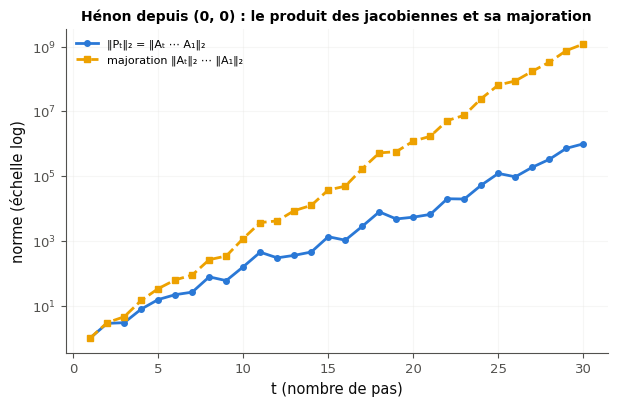

✅ Ex M22.21 : les normes des produits et leurs majorations sont dessinées.


In [28]:
product_norms = mymath.recurrence.product_norms


def draw_products_21(ax, norms, bounds):
    """In ax: the norms ‖P_t‖₂ and their bounds against t = 1, ..., len(norms), each with points, the y scale
    logarithmic; a legend and a title. No other axes."""
    steps = np.arange(1, len(norms) + 1)
    ax.plot(steps, norms, "o-", color="C0", markersize=4, label="‖Pₜ‖₂ = ‖Aₜ ⋯ A₁‖₂")
    ax.plot(steps, bounds, "s--", color="C3", markersize=4, label="majoration ‖Aₜ‖₂ ⋯ ‖A₁‖₂")
    ax.set_yscale("log")
    ax.set_xlabel("t (nombre de pas)")
    ax.set_ylabel("norme (échelle log)")
    ax.set_title("Hénon depuis (0, 0) : le produit des jacobiennes et sa majoration", fontsize=10)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)


states_21 = [np.zeros(2)]
for _ in range(30):
    states_21.append(henon_21(states_21[-1]))
states_21 = np.array(states_21)                               # 31 rows
products_21 = product_norms([henon_jacobian_21(x) for x in states_21[:30]])
norms_21, bounds_21 = products_21
answer_M22_21a = float(norms_21[2])
answer_M22_21b = round(float(bounds_21[29] / norms_21[29]))
answer_M22_21c = math.log(norms_21[29]) / 30
wear_norms_21, wear_bounds_21 = product_norms([WEAR_21] * 12)
answer_M22_21d = bool(np.allclose(wear_norms_21, wear_bounds_21, rtol=1e-12, atol=0))
print("a)", round(answer_M22_21a, 6), " b)", answer_M22_21b, f"(norme {norms_21[29]:.4g}, majoration {bounds_21[29]:.4g})")
print("c)", round(answer_M22_21c, 6), "; facteur moyen par pas :", round(math.exp(answer_M22_21c), 3))
print("d)", answer_M22_21d, "; dernière norme :", round(float(wear_norms_21[-1]), 6))

with checked("M22.21"):
    results_21 = []
    report_21 = reporter(results_21)
    path_c21 = [np.zeros(2)]
    for _ in range(30):
        path_c21.append(np.array([1.0 - 1.4 * path_c21[-1][0] ** 2 + path_c21[-1][1], 0.3 * path_c21[-1][0]]))
    P_c21, bound_c21, norms_c21, bounds_c21 = np.eye(2), 1.0, [], []
    for x_c21 in path_c21[:30]:
        J_c21 = np.array([[-2.8 * x_c21[0], 1.0], [0.3, 0.0]])
        P_c21, bound_c21 = J_c21 @ P_c21, bound_c21 * float(np.linalg.svdvals(J_c21)[0])
        norms_c21.append(float(np.linalg.svdvals(P_c21)[0]))
        bounds_c21.append(bound_c21)
    steps_c21 = np.arange(1, 31)
    fig_21, ax_21 = plt.subplots(figsize=(7, 4.2))
    try:
        opened_21 = drawn(draw_products_21, ax_21, np.array(norms_c21), np.array(bounds_c21))
        report_21(not opened_21, "draw_products_21 dessine dans l'axe reçu",
                  "draw_products_21 doit dessiner dans l'axe reçu, sans ouvrir de figure")
        report_21(through(ax_21, steps_c21, norms_c21) and through(ax_21, steps_c21, bounds_c21),
                  "les normes et les majorations sont tracées contre t = 1, …, 30",
                  "il manque une courbe : les normes, puis les majorations, contre t = 1, …, 30 (une valeur par t)")
        report_21(ax_21.get_yscale() == "log", "l'échelle des ordonnées est logarithmique",
                  "mets l'échelle des ordonnées en logarithmique (ax.set_yscale(\"log\"))")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_21)
        raise
    plt.show()
    verdict("M22.21", all(results_21), "les normes des produits et leurs majorations sont dessinées.", "")

In [29]:
path_21r = [np.zeros(2)]
for _ in range(30):
    path_21r.append(np.array([1.0 - 1.4 * path_21r[-1][0] ** 2 + path_21r[-1][1], 0.3 * path_21r[-1][0]]))
jacobians_21r = [np.array([[-2.8 * x[0], 1.0], [0.3, 0.0]]) for x in path_21r[:30]]
P_21r, norms_21r, bounds_21r, bound_21r = np.eye(2), [], [], 1.0
for J in jacobians_21r:
    P_21r = J @ P_21r                                      # the last jacobian on the left
    bound_21r *= float(np.linalg.svdvals(J)[0])
    norms_21r.append(float(np.linalg.svdvals(P_21r)[0]))
    bounds_21r.append(bound_21r)
P_21r, product_norms_reversed_21r = np.eye(2), []
for J in jacobians_21r[::-1]:                              # the list given in the reverse order
    P_21r = J @ P_21r
    product_norms_reversed_21r.append(float(np.linalg.svdvals(P_21r)[0]))
Q_21r = np.eye(2)
for J in jacobians_21r[:3]:
    Q_21r = Q_21r @ J                                      # the order of time: the first jacobian on the left
wbm.record("M22.21a", norms_21r[2], decimals=3,
           mistakes={"P₃ = J(x₂) J(x₁) J(x₀) : le nouveau facteur à gauche": float(np.linalg.svdvals(Q_21r)[0]),
                     "la troisième norme rendue est celle de P₃, à l'indice 2": norms_21r[3],
                     "le dernier pas à gauche : donne J(x₀), …, J(x₂₉) dans cet ordre":
                         product_norms_reversed_21r[2]})
wbm.record("M22.21b", bounds_21r[29] / norms_21r[29], decimals=0,
           mistakes={"le rapport de la majoration à la norme, pas l'inverse": norms_21r[29] / bounds_21r[29]})
wbm.record("M22.21c", math.log(norms_21r[29]) / 30, decimals=2,
           mistakes={"ln, le logarithme népérien": math.log10(norms_21r[29]) / 30})
wear_21r = np.diag([0.985, 0.93, 0.65])
W_21r, wear_norms_21r, wear_bounds_21r, wear_bound_21r = np.eye(3), [], [], 1.0
for _ in range(12):
    W_21r = wear_21r @ W_21r
    wear_bound_21r *= float(np.linalg.svdvals(wear_21r)[0])
    wear_norms_21r.append(float(np.linalg.svdvals(W_21r)[0]))
    wear_bounds_21r.append(wear_bound_21r)
wbm.record("M22.21d", bool(np.allclose(wear_norms_21r, wear_bounds_21r, rtol=1e-12, atol=0)),
           mistakes={"pour une même matrice diagonale répétée, la norme du produit est le produit des normes : "
                     "compare par np.allclose(..., rtol=1e-12, atol=0)": False})

WBM_ANSWER {"coarse_any": {"0": ["cf6c07fe6af87ac464ed6bcf73a8a938a63b3bfa9c870f8491b68e65ef6ec72a"]}, "coarser": {"1": ["ecabd1b9c4fcf67549cc74b3fc3ba21eebf4eb7abfab6843c4f72b35e0bbc449"]}, "decimals": 3, "hash": "2f017d047a84f81230d34a4319862462f2a7418fa38edb471509e22bf229316e", "hash_coarse": "27bcf0911641163da6b2679639a7eb5d62896fa2aae2e7c224f3ebcf6fa491af", "id": "M22.21a", "kind": "float", "magnitude": 0, "mistakes": {"5ea642e15b0de5700b2b716101367b12730197a9e76c3432eb6f4713e0eae030": "le dernier pas à gauche : donne J(x₀), …, J(x₂₉) dans cet ordre", "b26c019d86bd67fe47d47da05eb636a8a02509e61b4ed4b6e2faf397a30e54c5": "P₃ = J(x₂) J(x₁) J(x₀) : le nouveau facteur à gauche", "f65d07f44006f2f63ca21e8d68424217f1d61d6d9d087d7b07a8b6f30e7d3da8": "la troisième norme rendue est celle de P₃, à l'indice 2"}, "sign": 1}
📝 Ex M22.21a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 0, "hash": "185d6154f90a979fbe3af44bf6aca0402d4416339388a2b7174d805387603e24", "id": "M22.21b

💡 $\mathbf{P} \leftarrow \mathbf{A}_t\mathbf{P}$ et la majoration multipliée par $\lVert\mathbf{A}_t\rVert$, à chaque pas. a) $\lVert\mathbf{P}_3\rVert_2 \approx 2{,}978$, la norme 2 de la matrice de M22.8 d). b) Pour $t = 30$, $\lVert\mathbf{P}_{30}\rVert_2 \approx 9{,}9 \times 10^5$ et la majoration $\approx 1{,}2 \times 10^9$ : un rapport d'environ $1\,210$. c) $\frac1{30}\ln\lVert\mathbf{P}_{30}\rVert_2 \approx 0{,}46$ : sur cette trajectoire, le produit des jacobiennes grandit d'environ $e^{0{,}46} \approx 1{,}6$ par pas en moyenne (l'application de Hénon sépare les trajectoires voisines). d) Vrai : pour une même matrice diagonale répétée, $\lVert\operatorname{diag}(\mathbf{a})^t\rVert_2 = (\max a_i)^t$, et la dernière norme vaut $0{,}985^{12} \approx 0{,}8341$. e) En échelle logarithmique, les deux courbes s'écartent à peu près linéairement : la majoration perd un facteur à chaque pas.

### Ex M22.22 — `np.linalg.eigvals` et `np.linalg.norm` : rayon spectral et normes de matrices tirées au hasard, et ρ ≤ ‖A‖ 📦 ★ ⏱️ 15 min
**Objectif :** comparer, avec NumPy, le rayon spectral et les normes de matrices tirées au hasard, et voir le piège de `np.linalg.norm` sans `ord`.  
**Prérequis :** fiche §3 et §4 · **Parcours :** C

La cellule fournie tire 1 000 matrices $4 \times 4$ de coefficients gaussiens (`A_22`, graine 5722 : `A_22[k]` est la $k$-ième). Calcule, pour chacune, son rayon spectral (`np.abs(np.linalg.eigvals(A_22[k])).max()`) et ses normes `np.linalg.norm(A_22[k], 1)`, `np.linalg.norm(A_22[k], 2)`, `np.linalg.norm(A_22[k], np.inf)` et `np.linalg.norm(A_22[k], "fro")`. Puis :
- a) la proportion des matrices pour lesquelles $\rho$ est au plus égal à la plus petite des trois normes induites ;
- b) la moyenne de $\frac{\rho}{\lVert\cdot\rVert_2}$ (2 décimales dans ta copie) ;
- c) la proportion des matrices pour lesquelles $\lVert\cdot\rVert_1 < \lVert\cdot\rVert_2$ (3 décimales dans ta copie) ;
- d) pour les parties symétriques $\mathbf{S}_k = \frac12(\mathbf{A}_k + \mathbf{A}_k^\top)$ : vrai ou faux, $\lvert\rho(\mathbf{S}_k) - \lVert\mathbf{S}_k\rVert_2\rvert < 10^{-12}$ pour les 1 000 ;
- e) pour `A_22[0]`, deux vrai ou faux, dans cet ordre (`np.isclose`) : `np.linalg.norm(A_22[0])` (sans `ord`) est égal à la norme de Frobenius, puis à $\lVert\cdot\rVert_2$ ;
- f) pour `A_22[0]`, $\lVert\mathbf{A}^t\rVert_2^{1/t}$ pour $t = 1$, 5, 25 et 100, puis $\rho$ (une liste de 5 nombres ; 3 décimales dans ta copie ; `np.linalg.matrix_power` est permise ici).

Ce qu'il faut observer : $\rho \le \lVert\cdot\rVert$ sans exception, avec un écart important pour une matrice quelconque (en moyenne, $\rho$ n'est que les deux tiers de $\lVert\cdot\rVert_2$) ; l'égalité pour les matrices symétriques (en norme 2) ; et le piège de `np.linalg.norm` sans `ord`. Dans ta copie : pourquoi l'égalité de d) ? Que dit f) de la formule de Gelfand ?

In [30]:
rng_22 = np.random.default_rng(5722)
A_22 = rng_22.normal(size=(1000, 4, 4))                 # 1 000 matrices 4 × 4 of Gaussian coefficients

In [31]:
rho_22 = np.array([np.abs(np.linalg.eigvals(A)).max() for A in A_22])
norms_22 = {ord: np.array([np.linalg.norm(A, ord) for A in A_22]) for ord in (1, 2, np.inf, "fro")}
answer_M22_22a = float(np.mean(rho_22 <= np.minimum(np.minimum(norms_22[1], norms_22[2]), norms_22[np.inf])))
answer_M22_22b = float(np.mean(rho_22 / norms_22[2]))
answer_M22_22c = float(np.mean(norms_22[1] < norms_22[2]))
symmetric_22 = (A_22 + A_22.transpose(0, 2, 1)) / 2
gaps_22 = [abs(np.abs(np.linalg.eigvals(S)).max() - np.linalg.norm(S, 2)) for S in symmetric_22]
answer_M22_22d = bool(max(gaps_22) < 1e-12)
A0_22 = A_22[0]
answer_M22_22e = [bool(np.isclose(np.linalg.norm(A0_22), np.linalg.norm(A0_22, "fro"))),
                  bool(np.isclose(np.linalg.norm(A0_22), np.linalg.norm(A0_22, 2)))]
answer_M22_22f = ([float(np.linalg.norm(np.linalg.matrix_power(A0_22, t), 2) ** (1 / t)) for t in (1, 5, 25, 100)]
                  + [float(rho_22[0])])
print("a)", answer_M22_22a, " b)", round(answer_M22_22b, 4), " c)", answer_M22_22c)
print("d)", answer_M22_22d, "; plus grand écart :", f"{max(gaps_22):.1e}")
print("e)", answer_M22_22e, "; Frobenius", round(float(norms_22['fro'][0]), 4), ", ‖·‖₂", round(float(norms_22[2][0]), 4))
print("f)", np.round(answer_M22_22f, 4).tolist())

a) 1.0  b) 0.662  c) 0.004
d) True ; plus grand écart : 7.5e-15
e) [True, False] ; Frobenius 3.1749 , ‖·‖₂ 2.5735
f) [2.5735, 1.8704, 1.6817, 1.6692, 1.6602]


In [32]:
matrices_22r = np.random.default_rng(5722).normal(size=(1000, 4, 4))
spectral_22r = np.array([float(np.max(np.abs(np.linalg.eigvals(A)))) for A in matrices_22r])
one_22r = np.abs(matrices_22r).sum(axis=1).max(axis=1)                 # the largest column sums
inf_22r = np.abs(matrices_22r).sum(axis=2).max(axis=1)                 # the largest row sums
two_22r = np.array([float(np.linalg.svdvals(A)[0]) for A in matrices_22r])
fro_22r = np.sqrt((matrices_22r ** 2).sum(axis=(1, 2)))
wbm.record("M22.22a", float(np.mean(spectral_22r <= np.minimum(np.minimum(one_22r, two_22r), inf_22r) * (1 + 1e-12))),
           decimals=3)
wbm.record("M22.22b", float(np.mean(spectral_22r / two_22r)), decimals=2,
           mistakes={"‖·‖₂ est s_max, pas la norme de Frobenius (np.linalg.norm sans ord)":
                         float(np.mean(spectral_22r / fro_22r))})
wbm.record("M22.22c", float(np.mean(one_22r < two_22r)), decimals=3,
           mistakes={"on demande la proportion où ‖·‖₁ est la plus PETITE des deux": float(np.mean(one_22r > two_22r))})
symmetric_22r = (matrices_22r + matrices_22r.transpose(0, 2, 1)) / 2
wbm.record("M22.22d", bool(max(abs(float(np.max(np.abs(np.linalg.eigvalsh(S)))) - float(np.linalg.svdvals(S)[0]))
                               for S in symmetric_22r) < 1e-12),
           mistakes={"une matrice symétrique est normale : en norme 2, son rayon spectral est sa norme": False})
first_22r = matrices_22r[0]
wbm.record("M22.22e", [bool(np.isclose(np.linalg.norm(first_22r), fro_22r[0])),
                       bool(np.isclose(np.linalg.norm(first_22r), two_22r[0]))],
           mistakes={"sans ord, np.linalg.norm d'une matrice est la norme de Frobenius, pas s_max": [True, True],
                     "sans ord, np.linalg.norm d'une matrice rend la racine de la somme des carrés des coefficients":
                         [False, True]})
gelfand_22r = [float(np.linalg.svdvals(np.linalg.matrix_power(first_22r, t))[0]) ** (1 / t) for t in (1, 5, 25, 100)]
wbm.record("M22.22f", gelfand_22r + [float(spectral_22r[0])], decimals=3,
           mistakes={"sans ord, np.linalg.norm d'une matrice rend la norme de Frobenius : précise ord=2":
                         [float(np.sqrt((np.linalg.matrix_power(first_22r, t) ** 2).sum())) ** (1 / t)
                          for t in (1, 5, 25, 100)] + [float(spectral_22r[0])]})

WBM_ANSWER {"coarse_any": {"0": ["5af331e8d14c2ad3877b5b9e84c5ec26d05245b7fee131f44d949d926c14f553"]}, "coarser": {"1": ["baefc385f19022acae0b98511db7b70b44c0fa217b1742f6321321fab727dcb6"]}, "decimals": 3, "hash": "1f1f346893ab8325aef85d2bb001bbdf032c4da496f59631b07674723bdd8afd", "hash_coarse": "42eabc21c3ffa57cf19f7135b54d93791ecb36e37433ff0c026a2e0d03192a3e", "id": "M22.22a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M22.22a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["21d65d66b855f331deadaa52c9e4ca1d6c4c683c3ff61f04c4eef83bed959c6c"]}, "decimals": 2, "hash": "b569cf986442711ccc3698b13b8dee5a6b247fb015a0d59ac3f7618f903287df", "hash_coarse": "26b7ee5f82aafd2a404fbc48855d20e1b4fc37d91d86e82d993d8bcf6dfc6ba0", "id": "M22.22b", "kind": "float", "magnitude": -1, "mistakes": {"2457fe11c2f93a58e8b420f9de5e75d0f6b9901c895b1615b0444e1f79cec19b": "‖·‖₂ est s_max, pas la norme de Frobenius (np.linalg.norm sans ord)"}, "sign": 1}
📝 Ex M22.22b : réponse en

💡 a) 1,0 : aucune exception à $\rho \le \lVert\cdot\rVert$. b) $0{,}66$ : pour une matrice gaussienne $4 \times 4$, $\rho$ ne vaut en moyenne que les deux tiers de $\lVert\cdot\rVert_2$. c) $0{,}004$ : la norme 1 est presque toujours plus grande que la norme 2 (4 matrices sur 1 000 font exception). d) Vrai : l'écart maximal est de l'ordre de $10^{-14}$ ; une matrice symétrique est normale, et l'égalité vaut en norme 2. e) $[\text{vrai}, \text{faux}]$ : sans `ord`, `np.linalg.norm` d'une matrice rend la norme de Frobenius. f) $[2{,}573 ;\ 1{,}870 ;\ 1{,}682 ;\ 1{,}669 ;\ 1{,}660]$ : la formule de Gelfand, en action.

## Partie B · Prédire, mesurer, dessiner

Fiche §2, §3 et §5. Une croissance transitoire, prédite puis tracée ; le taux de croissance d'un produit de matrices aléatoires, mesuré ; les spirales d'une récurrence à valeurs propres complexes, dessinées.

### Ex M22.23 — Prédire l'allure de ‖Aᵗ‖₂ pour une matrice non normale de rayon spectral 0,8, puis tracer 🔮 ★ ⏱️ 20 min
**Objectif :** prévoir la croissance transitoire d'une matrice non normale de rayon spectral < 1, puis la mesurer et la tracer.  
**Prérequis :** fiche §3 et §4 ; Ex M22.20 · **Parcours :** C, E

$\mathbf{A} = \begin{pmatrix} -1{,}2 & 2 \\ -2 & 2{,}8 \end{pmatrix}$ (`A_23`). **Avant d'exécuter quoi que ce soit**, calcule à la main ses valeurs propres, $\mathbf{A}^\top\mathbf{A}$ et $\mathbf{A}\mathbf{A}^\top$, puis prédis :
- a) l'allure de $\lVert\mathbf{A}^t\rVert_2$ pour $t = 0$ à 40 : (A) elle décroît dès le premier pas, comme $0{,}8^t$ ; (B) elle monte pendant quelques pas, puis décroît vers 0 ; (C) elle monte sans fin ; (D) elle oscille sans décroître (une lettre) ;
- b) le pas $t$ de son maximum : (A) $t = 1$ ; (B) entre 3 et 6 ; (C) entre 15 et 25 (une lettre) ;
- c) vrai ou faux : $\lVert\mathbf{A}^{10}\rVert_2 > 1$ ;
- d) vrai ou faux : $\lVert\mathbf{A}^t\rVert_2 \ge 0{,}8^t$ pour tout $t$.

Puis, une fois tes prédictions écrites et vérifiées : calcule $\lVert\mathbf{A}^t\rVert_2$ pour $t = 0, \ldots, 40$ avec ta `operator_norm` (pour les puissances, des produits successifs ou `np.linalg.matrix_power`, $\mathbf{A}^0 = \mathbf{I}$), écris `draw_norms_23(ax, ts, norms)`, qui trace dans l'axe reçu (sans en ouvrir d'autre), en échelle logarithmique, les normes contre $t$ (des points reliés) et la courbe $0{,}8^t$ aux mêmes $t$, avec une légende ; et relève :
- e) le pas $t$ du maximum (un entier) ;
- f) la valeur du maximum (2 décimales dans ta copie) ;
- g) le premier pas $t$ où $\lVert\mathbf{A}^t\rVert_2 < 1$ (un entier).

La vérification de l'expérience ne s'exécute qu'une fois tes quatre prédictions écrites : elle compare tes normes à celles de NumPy, appelle `draw_norms_23` et regarde le dessin, en s'arrêtant au premier ❌. Ce qu'il faut observer : la valeur propre double 0,8 dit le long terme, pas les premiers pas ; la norme est multipliée par plus de 8 avant de décroître, et passe 20 pas au-dessus de 1.

In [33]:
A_23 = np.array([[-1.2, 2.0], [-2.0, 2.8]])

In [34]:
a_23r = np.array([[-1.2, 2.0], [-2.0, 2.8]])
norms_23r = [float(np.linalg.svdvals(np.linalg.matrix_power(a_23r, t))[0]) for t in range(41)]
peak_23r = int(np.argmax(norms_23r))
shapes_23r = {"A": norms_23r[1] < norms_23r[0], "C": norms_23r[40] > norms_23r[0],
              "B": norms_23r[1] > norms_23r[0] and norms_23r[40] < norms_23r[peak_23r] / 10}
wbm.record("M22.23a", next(letter for letter, ok in shapes_23r.items() if ok), prediction=True,
           mistakes={"ρ(A) < 1 ne dit rien des premiers pas d'une matrice non normale : compare AᵀA et AAᵀ": "A",
                     "ρ(A) < 1 : les puissances finissent par tendre vers 0": "C",
                     "les valeurs propres sont réelles : rien ne fait tourner les puissances": "D"})
wbm.record("M22.23b", "A" if peak_23r == 1 else "B" if 3 <= peak_23r <= 6 else "C", prediction=True,
           mistakes={"un bloc de Jordan multiplie λᵗ par un facteur qui grandit avec t : tant que le rapport de deux "
                     "termes successifs dépasse 1, la norme monte": "A",
                     "pour λ = 0,8, le rapport de deux termes successifs de t λ^(t−1) passe vite sous 1": "C"})
wbm.record("M22.23c", norms_23r[10] > 1, prediction=True,
           mistakes={"λᵗ décroît lentement pour λ = 0,8, et une partie nilpotente la multiplie par un facteur qui "
                     "grandit avec t": False})
wbm.record("M22.23d", all(n >= 0.8 ** t * (1 - 1e-12) for t, n in enumerate(norms_23r)), prediction=True,
           mistakes={"‖Aᵗ‖ ≥ ρ(Aᵗ) = ρ(A)ᵗ pour toute norme induite (fiche §4)": False})

WBM_ANSWER {"hash": "3822031894e33a86fe5ba2d5b0da8aa8887ed80c6481589d3bc40a017760df50", "id": "M22.23a", "kind": "str", "mistakes": {"06be1eb27156247307109fbc336a8c4542632afab7ac0ec849cf33bf3ee1b321": "ρ(A) < 1 ne dit rien des premiers pas d'une matrice non normale : compare AᵀA et AAᵀ", "333c1f73fb325296735d4985f786da9834832cf76bf93595ef33365b6e2f92a5": "les valeurs propres sont réelles : rien ne fait tourner les puissances", "5e39c66748da24f33f309b4dff89aeee00ec1850476a703a3dd994cc1cd68770": "ρ(A) < 1 : les puissances finissent par tendre vers 0"}, "prediction": true}
📝 Ex M22.23a : réponse enregistrée (str).
WBM_ANSWER {"hash": "c1acf566dd247e82933878962d32d8a53a312a9e9d2d7ff308396accef5c1dbe", "id": "M22.23b", "kind": "str", "mistakes": {"0750709a6aa8f9e957bc92a07aebee38c703c603bb1dc4cbb01ccaa77bbc1fac": "pour λ = 0,8, le rapport de deux termes successifs de t λ^(t−1) passe vite sous 1", "3ce503ca3f9b5dc7b0c294e9c59b92fc713b7f27e7fbb9ae5203b6de96ac9fa6": "un bloc de Jordan multipli

**L'expérience.** Écris-la une fois tes quatre prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

valeurs propres : [(0.8+0j), (0.8-0j)] ; AᵀA = [[5.44, -8.0], [-8.0, 11.84]] ; AAᵀ = [[5.44, 8.0], [8.0, 11.84]]
‖Aᵗ‖₂ pour t = 0 … 8 : [1.0, 4.154, 6.463, 7.714, 8.212, 8.205, 7.873, 7.346, 6.715] ; t = 10 : 5.371
e) 4  f) 8.212429  g) 21
✅ Ex M22.23 : norms_23, les normes ‖Aᵗ‖₂ pour t = 0, …, 40 : un tableau (41,), comme attendu.
✅ draw_norms_23 dessine dans l'axe reçu
✅ les normes sont tracées contre t
✅ la courbe 0,8ᵗ est tracée
✅ l'échelle des ordonnées est logarithmique


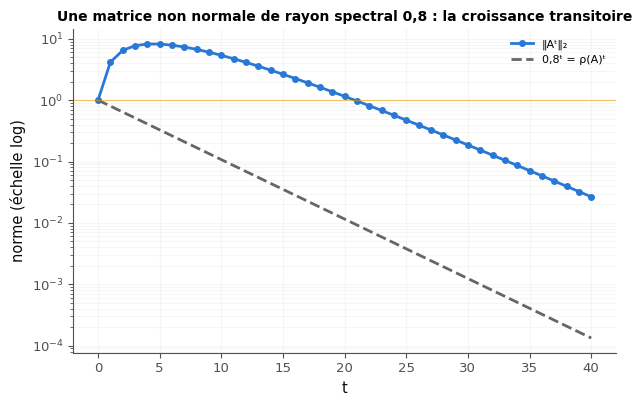

✅ Ex M22.23 : les normes et 0,8ᵗ sont dessinées.


In [35]:
operator_norm = mymath.recurrence.operator_norm


def draw_norms_23(ax, ts, norms):
    """In ax: the norms ‖A^t‖₂ against t (points joined) and the curve 0.8^t at the same t, the y scale logarithmic;
    a legend. No other axes."""
    ts = np.asarray(ts)
    ax.plot(ts, norms, "o-", color="C0", markersize=4, label="‖Aᵗ‖₂")
    ax.plot(ts, 0.8 ** ts, "--", color="0.4", label="0,8ᵗ = ρ(A)ᵗ")
    ax.axhline(1.0, color="C3", linewidth=0.8, alpha=0.6)
    ax.set_yscale("log")
    ax.set_xlabel("t")
    ax.set_ylabel("norme (échelle log)")
    ax.set_title("Une matrice non normale de rayon spectral 0,8 : la croissance transitoire", fontsize=10)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)


norms_23, P_23 = [], np.eye(2)
for t_23 in range(41):
    norms_23.append(operator_norm(P_23, 2))                    # ‖A^t‖₂, from A^0 = I
    P_23 = A_23 @ P_23
answer_M22_23e = int(np.argmax(norms_23))
answer_M22_23f = float(max(norms_23))
answer_M22_23g = next(t for t, n in enumerate(norms_23) if n < 1)
print("valeurs propres :", np.round(np.linalg.eigvals(A_23), 6).tolist(), "; AᵀA =", (A_23.T @ A_23).round(4).tolist(),
      "; AAᵀ =", (A_23 @ A_23.T).round(4).tolist())
print("‖Aᵗ‖₂ pour t = 0 … 8 :", np.round(norms_23[:9], 3).tolist(), "; t = 10 :", round(norms_23[10], 3))
print("e)", answer_M22_23e, " f)", round(answer_M22_23f, 6), " g)", answer_M22_23g)

with checked("M22.23"):
    results_23 = []
    report_23 = reporter(results_23)
    steps_c23 = np.arange(41)
    want_c23 = np.array([float(np.linalg.svdvals(np.linalg.matrix_power(A_23, t))[0]) for t in steps_c23])
    if not filled(norms_23):
        print("⏳ Ex M22.23 : la vérification attend tes normes norms_23.")
        raise StopCheck
    results_23.append(same("M22.23", "norms_23, les normes ‖Aᵗ‖₂ pour t = 0, …, 40", norms_23, want_c23))
    if not results_23[-1]:
        raise StopCheck
    fig_23, ax_23 = plt.subplots(figsize=(7, 4.2))
    try:
        opened_23 = drawn(draw_norms_23, ax_23, steps_c23, want_c23)
        report_23(not opened_23, "draw_norms_23 dessine dans l'axe reçu",
                  "draw_norms_23 doit dessiner dans l'axe reçu, sans ouvrir de figure")
        report_23(through(ax_23, steps_c23, want_c23), "les normes sont tracées contre t",
                  "il manque la courbe des normes contre t = 0, …, 40 (une valeur par t)")
        report_23(through(ax_23, steps_c23, 0.8 ** steps_c23), "la courbe 0,8ᵗ est tracée",
                  "il manque la courbe 0,8ᵗ, aux mêmes t")
        report_23(ax_23.get_yscale() == "log", "l'échelle des ordonnées est logarithmique",
                  "mets l'échelle des ordonnées en logarithmique (ax.set_yscale(\"log\"))")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_23)
        raise
    plt.show()
    verdict("M22.23", all(results_23), "les normes et 0,8ᵗ sont dessinées.", "")

In [36]:
wbm.record("M22.23e", peak_23r,
           mistakes={"l'indice de la liste est-il le pas t ? (la liste commence à t = 0, A⁰ = I)": {peak_23r - 1, peak_23r + 1}})
wbm.record("M22.23f", norms_23r[peak_23r], decimals=2,
           mistakes={"c'est la norme au pas 1 : relis ta liste, le maximum vient plus tard": norms_23r[1]})
first_23r = next(t for t, n in enumerate(norms_23r) if n < 1)
wbm.record("M22.23g", first_23r,
           mistakes={"l'indice de la liste est-il le pas t ? (la liste commence à t = 0, A⁰ = I)": {first_23r - 1, first_23r + 1}})

WBM_ANSWER {"hash": "8c5d37e2f99721d675db0811a0333ad72e75851e7afa97f8102978596f2f08eb", "id": "M22.23e", "kind": "int", "magnitude": 0, "mistakes": {"1f1476175003f7c63913d19e7e7169510b1f1ea79a8e7b8ae92a6d63eb8f5336": "l'indice de la liste est-il le pas t ? (la liste commence à t = 0, A⁰ = I)", "822a376fb309a8da1ca3225f091adc220e1df2f6bda259a084c1ad32ea5f4f68": "l'indice de la liste est-il le pas t ? (la liste commence à t = 0, A⁰ = I)"}, "sign": 1}
📝 Ex M22.23e : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["8e376dce832eb35ad98dd0a8898bff1691ff5ffbd1c2d44d34113f3c8fc5d480"]}, "decimals": 2, "hash": "b5467aaec65d85676c84b40de59e554b4b84b9f74700da85207e5701c9d5c391", "hash_coarse": "f32ed77aa17b83d3524d6fc9efbaa55e05d765a11b0751efc7c00acbd8427b5b", "id": "M22.23f", "kind": "float", "magnitude": 0, "mistakes": {"442ee274662a7ae8e9c08eba986074f734dc8f46faa006cdbefb615dd8b2a579": "c'est la norme au pas 1 : relis ta liste, le maximum vient plus tard"}, "sign": 1}
📝 Ex M22.23f 

**Après l'expérience**, dans ta copie : pourquoi la norme monte-t-elle d'abord, alors que les deux valeurs propres valent 0,8 ? Quel terme de la formule de Aᵗ d'un bloc de Jordan (fiche §3) le montre ? Que deviendrait l'expérience avec une matrice symétrique de mêmes valeurs propres ?

💡 Valeurs propres : 0,8 double (trace $1{,}6$, déterminant $-3{,}36 + 4 = 0{,}64$) ; $\mathbf{A}^\top\mathbf{A} = \begin{pmatrix} 5{,}44 & -8 \\ -8 & 11{,}84 \end{pmatrix} \ne \mathbf{A}\mathbf{A}^\top = \begin{pmatrix} 5{,}44 & 8 \\ 8 & 11{,}84 \end{pmatrix}$ : $\mathbf{A}$ n'est pas normale. Prédictions attendues : a) (B) ; b) (B) ; c) vrai ($\lVert\mathbf{A}^{10}\rVert_2 \approx 5{,}37$) ; d) vrai ($\lVert\mathbf{A}^t\rVert_2 \ge \rho(\mathbf{A}^t) = \rho(\mathbf{A})^t$, ∂ M22.11). Mesures : e) $t = 4$ ; f) $8{,}21$ (le pas 5 donne $8{,}205$, presque autant) ; g) $t = 21$. $\mathbf{A}$ est la matrice $\begin{pmatrix} 0{,}8 & 4 \\ 0 & 0{,}8 \end{pmatrix}$ vue dans un repère tourné de 45° : mêmes normes 2 de ses puissances, $\lVert\mathbf{A}^t\rVert_2 \approx 4t \times 0{,}8^{t-1}$ quand $t$ grandit.

### Ex M22.24 — Des produits de matrices aléatoires : le taux de croissance (1/n) ln ‖Aₙ ⋯ A₁‖ 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer le taux de croissance d'un produit de matrices aléatoires, et le comparer au taux de la population moyenne et à la majoration par les normes.  
**Prérequis :** fiche §5 ; M02c, M06 ; Ex M22.21 · **Parcours :** C

Une plante vivace a deux stades, les graines dans le sol et les plantes en fleur : $\mathbf{x}_t = (\text{graines},\ \text{plantes})$. Une bonne année applique $\mathbf{G} = \begin{pmatrix} 0{,}2 & 3 \\ 0{,}6 & 0{,}4 \end{pmatrix}$ (`G_24`), une mauvaise $\mathbf{M} = \begin{pmatrix} 0{,}2 & 0{,}4 \\ 0{,}2 & 0{,}2 \end{pmatrix}$ (`M_24`), à pile ou face, indépendamment ; $n$ compte les années, c'est-à-dire les facteurs du produit $\mathbf{P}_n = \mathbf{A}_n\cdots\mathbf{A}_1$. La cellule fournie tire les années par `np.random.default_rng(5724).integers(0, 2, size=20000)` (`YEARS_24` ; 0 = bonne, 1 = mauvaise ; `YEARS_24[k - 1]` donne $\mathbf{A}_k$), et donne les graines de cinq autres suites, tirées de la même façon (`OTHER_SEEDS_24`, 5731 à 5735). Écris :
- `rates_24(years)` : les taux $\frac1n\sum_{k \le n}\ln\lVert\mathbf{x}_k\rVert_2$ pour $n = 1, \ldots$, `len(years)`, en renormalisant à chaque pas : partir de $\mathbf{x} = \frac{1}{\sqrt2}(1, 1)$, puis, chaque année, $\mathbf{x} \leftarrow \mathbf{A}_k\mathbf{x}$, ajouter $\ln\lVert\mathbf{x}\rVert_2$ à un cumul, et diviser $\mathbf{x}$ par sa norme ; c'est $\frac1n\ln\lVert\mathbf{P}_n\mathbf{x}_0\rVert_2$ ;
- `draw_rates_24(ax, curves, level_mean, level_bound)`, qui trace dans l'axe reçu (sans en ouvrir d'autre) chaque courbe de `curves` contre $n = 1, 2, \ldots$, l'abscisse logarithmique, et les droites horizontales `level_mean` et `level_bound` (`ax.axhline`), avec une légende.

Puis mesure :
- a) $\ln\rho(\mathbb{E}[\mathbf{A}])$, avec $\mathbb{E}[\mathbf{A}] = \frac12(\mathbf{G} + \mathbf{M})$ (3 décimales dans ta copie) : $\mathbb{E}[\mathbf{P}_n] = \mathbb{E}[\mathbf{A}]^n$, la population **moyenne**, grandit à ce taux ;
- b) avec ta `product_norms`, sur les 200 premières années, $\frac{1}{200}\ln\lVert\mathbf{P}_{200}\rVert_2$ (3 décimales dans ta copie) ;
- `curves_24` : les six courbes `rates_24`, celle de `YEARS_24` d'abord, puis celles des cinq autres suites, dans l'ordre de `OTHER_SEEDS_24` ;
- c) le taux pour $n = 20\,000$ sur `YEARS_24` (3 décimales dans ta copie) ;
- d) la majoration par les normes, $\mathbb{E}[\ln\lVert\mathbf{A}\rVert_2] = \frac12(\ln\lVert\mathbf{G}\rVert_2 + \ln\lVert\mathbf{M}\rVert_2)$ (3 décimales dans ta copie) ;
- e) le taux pour $n = 20\,000$ des cinq autres suites (une liste de 5 nombres ; 2 décimales dans ta copie) ;
- f) vrai ou faux : une trajectoire typique s'éteint, alors que la population moyenne grandit.

La vérification essaie `rates_24` sur des suites que tu ne vois pas, puis appelle `draw_rates_24` avec les six courbes et les droites a) et d), et regarde le dessin. Ce qu'il faut conclure : le taux converge vers le même nombre négatif pour toutes les suites (Furstenberg et Kesten, fiche §5) ; la population typique s'éteint, alors que la moyenne grandit, tirée par de rares suites très chanceuses ; et ni $\ln\rho(\mathbb{E}[\mathbf{A}])$, ni la majoration par les normes ne donnent ce taux : c'est la version matricielle de la plante du §5.

In [37]:
G_24 = np.array([[0.2, 3.0], [0.6, 0.4]])            # a good year: (seeds, plants) multiplied by G
M_24 = np.array([[0.2, 0.4], [0.2, 0.2]])            # a bad year
YEARS_24 = np.random.default_rng(5724).integers(0, 2, size=20000)   # 0 = good, 1 = bad; YEARS_24[k - 1] gives A_k
OTHER_SEEDS_24 = [5731, 5732, 5733, 5734, 5735]      # five more sequences, drawn the same way

a) 0.073376  b) -0.102993 (‖P₂₀₀‖₂ ≈ 1.13e-09)
c) -0.097685  d) 0.232373  e) [-0.0981, -0.0921, -0.0886, -0.0988, -0.098]
f) True ; 𝔼[ln ρ(A)] = -0.1151
✅ rates_24 : juste sur trois suites d'années que tu ne vois pas
✅ draw_rates_24 dessine dans l'axe reçu
✅ les six taux sont tracés contre n = 1, …, 20 000
✅ l'abscisse est logarithmique


✅ les deux droites a) et d) sont tracées


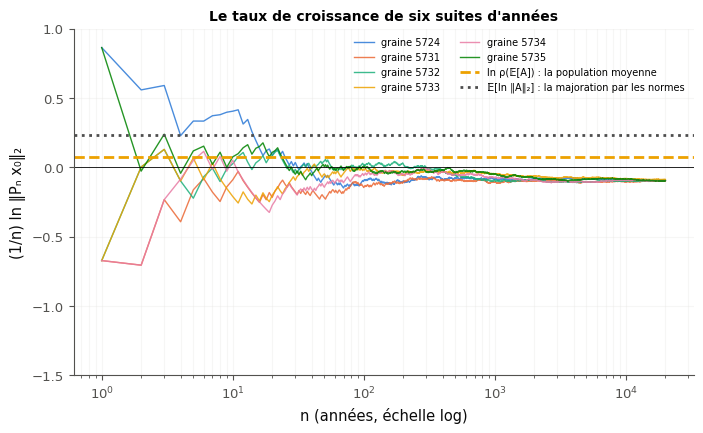

✅ Ex M22.24 : tes taux sont justes, et dessinés avec les deux droites.


In [38]:
product_norms = mymath.recurrence.product_norms


def rates_24(years):
    """The running growth rates (1/n) Σ_(k<=n) ln ‖x_k‖₂ for n = 1, ..., len(years): from x = (1, 1)/√2, each year
    x <- A_k x (G_24 for a 0, M_24 for a 1), ln ‖x‖₂ added to the sum, then x <- x / ‖x‖₂. A 1-D array."""
    x, total = np.array([1.0, 1.0]) / np.sqrt(2), 0.0
    out = np.empty(len(years))
    for n, year in enumerate(years):
        x = (G_24 if year == 0 else M_24) @ x
        size = np.linalg.norm(x)
        total += np.log(size)
        x = x / size                                     # renormalized: no overflow, no underflow
        out[n] = total / (n + 1)
    return out


def draw_rates_24(ax, curves, level_mean, level_bound):
    """In ax: each curve of `curves` against n = 1, ..., len(curve), the x scale logarithmic, and the horizontal
    lines level_mean and level_bound (ax.axhline); a legend. No other axes."""
    for i, curve in enumerate(curves):
        ax.plot(np.arange(1, len(curve) + 1), curve, linewidth=1, alpha=0.85,
                label="graine 5724" if i == 0 else f"graine {OTHER_SEEDS_24[i - 1]}")
    ax.axhline(level_mean, color="C3", linestyle="--", label="ln ρ(𝔼[A]) : la population moyenne")
    ax.axhline(level_bound, color="0.3", linestyle=":", label="𝔼[ln ‖A‖₂] : la majoration par les normes")
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_xscale("log")
    ax.set_ylim(-1.5, 1.0)
    ax.set_xlabel("n (années, échelle log)")
    ax.set_ylabel("(1/n) ln ‖Pₙ x₀‖₂")
    ax.set_title("Le taux de croissance de six suites d'années", fontsize=10)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=7, ncol=2)


answer_M22_24a = math.log(float(np.abs(np.linalg.eigvals((G_24 + M_24) / 2)).max()))
norms_24, _ = product_norms([G_24 if year == 0 else M_24 for year in YEARS_24[:200]])
answer_M22_24b = math.log(norms_24[-1]) / 200
curves_24 = [rates_24(YEARS_24)] + [rates_24(np.random.default_rng(seed).integers(0, 2, size=20000))
                                    for seed in OTHER_SEEDS_24]
answer_M22_24c = float(curves_24[0][-1])
answer_M22_24d = (math.log(np.linalg.norm(G_24, 2)) + math.log(np.linalg.norm(M_24, 2))) / 2
answer_M22_24e = [float(curve[-1]) for curve in curves_24[1:]]
answer_M22_24f = bool(answer_M22_24c < 0 < answer_M22_24a)
print("a)", round(answer_M22_24a, 6), " b)", round(answer_M22_24b, 6), f"(‖P₂₀₀‖₂ ≈ {norms_24[-1]:.2e})")
print("c)", round(answer_M22_24c, 6), " d)", round(answer_M22_24d, 6), " e)", np.round(answer_M22_24e, 4).tolist())
print("f)", answer_M22_24f, "; 𝔼[ln ρ(A)] =",
      round((math.log(np.abs(np.linalg.eigvals(G_24)).max()) + math.log(np.abs(np.linalg.eigvals(M_24)).max())) / 2, 4))

with checked("M22.24"):
    results_24 = []
    report_24 = reporter(results_24)

    def rates_c24(years):
        """The running rates (1/n) Σ ln ‖x‖₂, renormalized at each step (the check)."""
        x, total, out = np.array([1.0, 1.0]) / math.sqrt(2), 0.0, []
        for n, year in enumerate(years, start=1):
            x = (G_24 if year == 0 else M_24) @ x
            size = math.hypot(x[0], x[1])
            total += math.log(size)
            x = x / size
            out.append(total / n)
        return np.array(out)

    rng_c24 = np.random.default_rng(5714)
    wrong_c24 = []
    for length_c24 in (1, 9, 300):
        years_c24 = rng_c24.integers(0, 2, size=length_c24)
        want_c24 = rates_c24(years_c24)
        got_c24 = rates_24(years_c24.copy())
        if got_c24 is None or np.shape(got_c24) != want_c24.shape or not np.allclose(got_c24, want_c24, rtol=1e-9,
                                                                                    atol=1e-12):
            wrong_c24.append(f"{length_c24} année(s) {years_c24[:9].tolist()}{'…' if length_c24 > 9 else ''} : attendu "
                             f"{np.round(want_c24[:4], 4).tolist()}…, reçu {shown(got_c24)[:80]}")
    report_24(not wrong_c24, "rates_24 : juste sur trois suites d'années que tu ne vois pas",
              "rates_24, " + " ; ".join(wrong_c24[:2]))
    curves_c24 = [rates_c24(YEARS_24)] + [rates_c24(np.random.default_rng(seed).integers(0, 2, size=20000))
                                          for seed in OTHER_SEEDS_24]
    mean_c24 = math.log(float(np.abs(np.linalg.eigvals((G_24 + M_24) / 2)).max()))
    bound_c24 = (math.log(float(np.linalg.svdvals(G_24)[0])) + math.log(float(np.linalg.svdvals(M_24)[0]))) / 2
    steps_c24 = np.arange(1, 20001)
    fig_24, ax_24 = plt.subplots(figsize=(8, 4.5))
    try:
        opened_24 = drawn(draw_rates_24, ax_24, curves_c24, mean_c24, bound_c24)
        report_24(not opened_24, "draw_rates_24 dessine dans l'axe reçu",
                  "draw_rates_24 doit dessiner dans l'axe reçu, sans ouvrir de figure")
        report_24(all(through(ax_24, steps_c24, curve) for curve in curves_c24),
                  "les six taux sont tracés contre n = 1, …, 20 000",
                  "il manque une des six courbes, tracée contre n = 1, …, 20 000 (une valeur par année)")
        report_24(ax_24.get_xscale() == "log", "l'abscisse est logarithmique",
                  "mets l'échelle des abscisses en logarithmique (ax.set_xscale(\"log\"))")
        report_24(horizontal(ax_24, mean_c24) and horizontal(ax_24, bound_c24), "les deux droites a) et d) sont tracées",
                  "il manque une droite horizontale : ln ρ(𝔼[A]), ou la majoration 𝔼[ln ‖A‖₂] (ax.axhline)")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_24)
        raise
    plt.show()
    verdict("M22.24", all(results_24), "tes taux sont justes, et dessinés avec les deux droites.", "")

In [39]:
good_24r, bad_24r = np.array([[0.2, 3.0], [0.6, 0.4]]), np.array([[0.2, 0.4], [0.2, 0.2]])


def last_rate_24r(seed):
    """(1/n) ln ‖P_n x_0‖₂ for n = 20 000, x_0 = (1, 1)/√2, with the vector renormalized at each step."""
    x, total = np.array([1.0, 1.0]) / math.sqrt(2), 0.0
    years = np.random.default_rng(seed).integers(0, 2, size=20000)
    for year in years:
        x = (good_24r if year == 0 else bad_24r) @ x
        size = float(np.sqrt(x @ x))
        total, x = total + math.log(size), x / size
    return total / len(years)


mean_24r = math.log(max(abs(np.linalg.eigvals((good_24r + bad_24r) / 2))))
wbm.record("M22.24a", mean_24r, decimals=3,
           mistakes={"ρ(𝔼[A]) se calcule sur la matrice moyenne, pas en moyennant les logarithmes des rayons "
                     "spectraux": (math.log(max(abs(np.linalg.eigvals(good_24r)))) +
                                   math.log(max(abs(np.linalg.eigvals(bad_24r))))) / 2,
                     "ln, le logarithme népérien": math.log10(max(abs(np.linalg.eigvals((good_24r + bad_24r) / 2))))})
P_24r = np.eye(2)
for year in np.random.default_rng(5724).integers(0, 2, size=20000)[:200]:
    P_24r = (good_24r if year == 0 else bad_24r) @ P_24r      # the new factor on the left
wbm.record("M22.24b", math.log(float(np.linalg.svdvals(P_24r)[0])) / 200, decimals=3,
           mistakes={"ln, le logarithme népérien": math.log10(float(np.linalg.svdvals(P_24r)[0])) / 200})
rate_24r = last_rate_24r(5724)
wbm.record("M22.24c", rate_24r, decimals=3, mistakes={"ln, le logarithme népérien": rate_24r / math.log(10)})
wbm.record("M22.24d", (math.log(float(np.linalg.svdvals(good_24r)[0])) + math.log(float(np.linalg.svdvals(bad_24r)[0])))
           / 2, decimals=3,
           mistakes={"𝔼[ln ‖A‖₂] : la moyenne des logarithmes, pas le logarithme de la moyenne":
                         math.log((float(np.linalg.svdvals(good_24r)[0]) + float(np.linalg.svdvals(bad_24r)[0])) / 2)})
wbm.record("M22.24e", [last_rate_24r(seed) for seed in range(5731, 5736)], decimals=2)
wbm.record("M22.24f", rate_24r < 0 < mean_24r,
           mistakes={"compare le signe du taux c) à celui de a)": False})

WBM_ANSWER {"coarse_any": {"1": ["698b72e60240015fcab0dc1ffbca528533e992384f4c5f50f5ba6ab67692d3f4"]}, "decimals": 3, "hash": "70bc28404e5d72f8d96fe8e8080ce6222823dc1c9e9d8c771302e8b646beed90", "hash_coarse": "25d29162876eafcf238d316412401bf1ec365cd50f451e3d7c7836099c52cc16", "id": "M22.24a", "kind": "float", "magnitude": -2, "mistakes": {"43e2bf64e40b7c5713fc8656fe2d948e27673cd2d168dda182034503b893e605": "ρ(𝔼[A]) se calcule sur la matrice moyenne, pas en moyennant les logarithmes des rayons spectraux", "9de62b7872d83178500fdce297831773501773782b02e7d2afad075d971c4df6": "ln, le logarithme népérien"}, "sign": 1}
📝 Ex M22.24a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"1": ["cfe6d68384058a66ce31101d3312784a450b2e8c1585d43ae70b0530e26a2208"]}, "decimals": 3, "hash": "d93d17adcd1684559927e5f22ee5d4662564a31057eddf9d771b55ce2373e08f", "hash_coarse": "f3b6c439f519c45b43f2541a152a67e164e60aeb584d3adb6beb16b0f79ebb29", "id": "M22.24b", "kind": "float", "magnitude": 

WBM_ANSWER {"decimals": 2, "element_coarse": [["ce87e389d848af33d438749280731727ae4fbb38c000798d931b60616c223f9c"], ["e35fed5f4808039bee59a1eb7ce77ff8beb506170c9828c52df2877a95a27582"], ["eac7ed1425f56412023c12f643e4547c4e859529601cdcef08b4d5e7386f7733"], ["800ffacb100402ecb03638e02c50baa55d2bc2629f1d46e99ee61b6ff0a81d18"], ["6833205465395ab4a3158558b5294dd5ccf35b274c2b20f8f9ed4f6f3a1d4e00"]], "element_coarse_any": [[], [], [], [], []], "element_hashes": ["0a5e3774333adebe2c865c49351a6fd6b7a25bafea36c90bae4ade170968d024", "af9a3d9f7bf51b9ed0f5bdd3c0c7ecceae315fa766489d8481ec7d3aa54e7e06", "d6e170ccc26b54c557ab649e65ea0a24cae1d585afd00e262dbe3089571769a9", "3835193c99bd437c48553407f8cbefcaa4aa4255cda67e4b144cf2445fe8b8f9", "11a84667fa020425548429b2be4e1cf2b94faa887339fb878890494ed1e4f841"], "hash": "ee3bbe71149d75f11fc5bffe397a906136066e10123822f1cc5413ba7a04a8d6", "id": "M22.24e", "kind": "array", "shape": [5]}
📝 Ex M22.24e : réponse enregistrée (array, 2 décimales).
WBM_ANSWER {"hash"

**Après la figure**, dans ta copie : pourquoi ne pas utiliser `product_norms` sur les 20 000 années (regarde l'ordre de grandeur de $\lVert\mathbf{P}_n\rVert$) ? Pourquoi la population moyenne grandit-elle alors qu'une trajectoire typique s'éteint ? Pourquoi la majoration par les normes est-elle si loin du taux mesuré ?

💡 a) $\ln\rho(\mathbb{E}[\mathbf{A}]) \approx 0{,}073 > 0$ : la population moyenne grandit d'environ 7,6 % par an. b) $\frac1{200}\ln\lVert\mathbf{P}_{200}\rVert_2 \approx -0{,}103$. c) $-0{,}098$ sur les 20 000 années. d) $\mathbb{E}[\ln\lVert\mathbf{A}\rVert_2] \approx 0{,}232$. e) $[-0{,}10 ;\ -0{,}09 ;\ -0{,}09 ;\ -0{,}10 ;\ -0{,}10]$ (de $-0{,}099$ à $-0{,}089$). f) Vrai. Le taux se rapproche d'un même nombre, environ $-0{,}1$, pour toutes les suites : une trajectoire typique perd environ 10 % par an et s'éteint, alors que la moyenne grandit, tirée par de rares suites riches en bonnes années. La majoration par les normes est positive : elle ne dit même pas que la population s'éteint. `product_norms` ne convient pas sur 20 000 années : $\lVert\mathbf{P}_n\rVert \approx e^{-0{,}1\,n}$ descend sous le plus petit nombre représentable en `float64` (vers $10^{-308}$) bien avant ; d'où la renormalisation.

### Ex M22.25 — Les spirales d'une récurrence 2 × 2 à valeurs propres complexes, selon leur module 🎨 ★ ⏱️ 20 min
**Objectif :** voir qu'une récurrence 2 × 2 à valeurs propres complexes tourne dans un repère oblique, et que le module des valeurs propres décide seul si elle rentre, tourne en rond ou sort.  
**Prérequis :** fiche §2 ; Ex M22.3 et M22.19 · **Parcours :** C, E

$\mathbf{A} = \begin{pmatrix} 0 & -1 \\ 1 & 0{,}6 \end{pmatrix}$ (`A_25`) a pour déterminant 1 et pour valeurs propres $e^{\pm i\theta}$, avec $\cos\theta = 0{,}3$ ; les valeurs propres de $r\mathbf{A}$ sont de module $r$. La cellule fournie donne les quatre valeurs $r = 0{,}6$, $0{,}93$, $1$ et $1{,}04$ (`RS_25`), $\mathbf{x}_0 = (1, 0)$ (`X0_25`) et $T = 60$ (`T_25`). Écris :
- `spiral_25(r)` : la trajectoire $\mathbf{x}_t = (r\mathbf{A})^t\mathbf{x}_0$ pour $t = 0, \ldots, 60$, un état par ligne (un tableau de forme $(61, 2)$), avec ta `linear_system_states` (une entrée nulle : `B = np.zeros((2, 1))` et `inputs = np.zeros((60, 1))`) ;
- `draw_spirals_25(fig, axes, trajectories)`, qui reçoit cinq axes côte à côte et les quatre trajectoires, dans l'ordre de `RS_25`, et dessine, sans ouvrir d'autre figure : dans chacun des quatre premiers axes, une trajectoire (les points reliés, dans l'ordre), avec la même échelle sur les deux axes (`ax.set_aspect("equal")`) et un titre qui donne $r$ et le module des valeurs propres ; dans le cinquième, le rapport $\lVert\mathbf{x}_t\rVert_2 / r^t$ contre $t$ pour chacune des quatre trajectoires (quatre courbes), en échelle linéaire, avec une légende.

La vérification compare `spiral_25` aux puissances de $r\mathbf{A}$, puis appelle `draw_spirals_25` et regarde le dessin, en s'arrêtant au premier ❌. Ce qu'il faut observer : la matrice tourne d'environ $\theta \approx 1{,}27$ rad (environ 72,5°) à chaque pas, un tour en un peu moins de 5 pas, dans un repère oblique ; le module des valeurs propres, $r$, décide seul : spirale qui rentre ($r < 1$), ellipse ($r = 1$), spirale qui sort ($r > 1$) ; et le rapport $\lVert\mathbf{x}_t\rVert_2 / r^t$ reste borné et oscille au rythme de la rotation : $\lVert\mathbf{x}_t\rVert$ suit $r^t$ à un facteur près, qui oscille parce que la trajectoire est une ellipse et non un cercle. Dans ta copie : pourquoi ne voit-on qu'une seule courbe dans le cinquième panneau ?

In [40]:
A_25 = np.array([[0.0, -1.0], [1.0, 0.6]])          # det 1, eigenvalues e^(±iθ) with cos θ = 0.3
RS_25 = [0.6, 0.93, 1.0, 1.04]                       # the moduli r of the eigenvalues of r A_25
X0_25 = np.array([1.0, 0.0])
T_25 = 60

θ = 1.266104 rad, soit 72.54 ° par pas ; 4.963 pas par tour
‖x₆₀‖₂ : {0.6: 4.294e-14, 0.93: 0.01129, 1.0: 0.8786, 1.04: 9.243}
‖xₜ‖₂ / rᵗ entre 0.8773 et 1.1952 ; plus grand écart entre les quatre rapports : 6.7e-16
✅ spiral_25 : les quatre trajectoires sont justes (comparées aux puissances de r A)
✅ draw_spirals_25 dessine dans les axes reçus
✅ r = 0,6 : la trajectoire est tracée
✅ … avec la même échelle sur les deux axes
✅ … et un titre qui donne r
✅ r = 0,93 : la trajectoire est tracée
✅ … avec la même échelle sur les deux axes
✅ … et un titre qui donne r
✅ r = 1 : la trajectoire est tracée
✅ … avec la même échelle sur les deux axes
✅ … et un titre qui donne r
✅ r = 1,04 : la trajectoire est tracée
✅ … avec la même échelle sur les deux axes
✅ … et un titre qui donne r
✅ le cinquième panneau est en échelle linéaire
✅ les quatre rapports ‖xₜ‖₂ / rᵗ sont tracés contre t


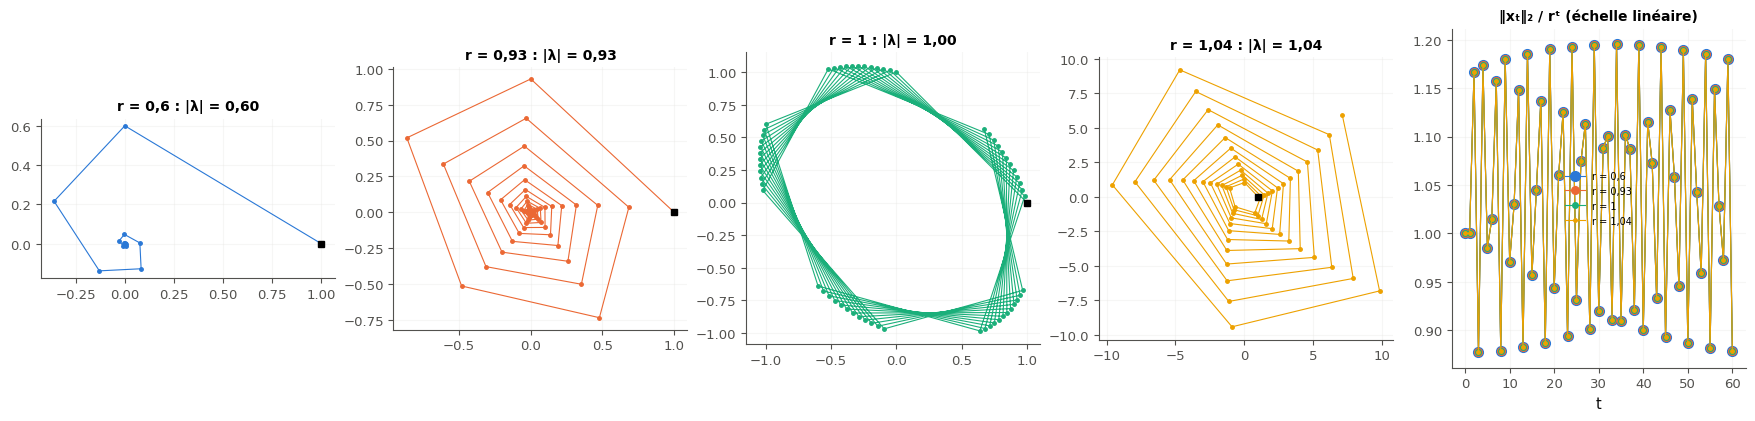

✅ Ex M22.25 : les quatre trajectoires et leurs rapports ‖xₜ‖₂ / rᵗ sont dessinés.


In [41]:
linear_system_states = mymath.recurrence.linear_system_states


def spiral_25(r):
    """The trajectory x_t = (r A_25)^t X0_25 for t = 0, ..., T_25, one state per row (an array (T_25 + 1, 2)), with
    your linear_system_states and zero inputs."""
    return linear_system_states(r * A_25, np.zeros((2, 1)), X0_25, np.zeros((T_25, 1)))


def draw_spirals_25(fig, axes, trajectories):
    """axes: 5 axes side by side; trajectories: the 4 trajectories, in the order of RS_25. In axes[i] (i < 4): the
    trajectory i (points joined, in order), equal scales on both axes, a title that gives r and the modulus of the
    eigenvalues; in axes[4]: the ratio ‖x_t‖₂ / r^t against t for each of the 4 trajectories (4 curves), the y scale
    linear, a legend. No other figure."""
    steps = np.arange(T_25 + 1)
    for i, (ax, r, path) in enumerate(zip(axes, RS_25, trajectories)):
        modulus = float(np.abs(np.linalg.eigvals(r * A_25)).max())
        ax.plot(path[:, 0], path[:, 1], "o-", color=f"C{i}", markersize=2.5, linewidth=0.8)
        ax.plot(*path[0], "ks", markersize=5)
        ax.set_aspect("equal")
        ax.set_title(f"r = {r:g} : |λ| = {modulus:.2f}".replace(".", ","), fontsize=10)
        ax.grid(True, alpha=0.3)
        axes[4].plot(steps, np.linalg.norm(path, axis=1) / r ** steps.astype(float), "o-", color=f"C{i}",
                     markersize=7 - 1.5 * i, linewidth=0.8, label=f"r = {r:g}".replace(".", ","))
    axes[4].set_xlabel("t")
    axes[4].set_title("‖xₜ‖₂ / rᵗ (échelle linéaire)", fontsize=10)
    axes[4].grid(True, alpha=0.3)
    axes[4].legend(fontsize=7)


trajectories_25 = [spiral_25(r) for r in RS_25]
theta_25 = math.acos(0.3)
print("θ =", round(theta_25, 6), "rad, soit", round(math.degrees(theta_25), 2), "° par pas ;", round(2 * math.pi / theta_25, 3),
      "pas par tour")
print("‖x₆₀‖₂ :", {r: float(f"{np.linalg.norm(path[-1]):.4g}") for r, path in zip(RS_25, trajectories_25)})
ratios_25 = [np.linalg.norm(path, axis=1) / r ** np.arange(T_25 + 1.0) for r, path in zip(RS_25, trajectories_25)]
print("‖xₜ‖₂ / rᵗ entre", round(float(ratios_25[0].min()), 4), "et", round(float(ratios_25[0].max()), 4),
      "; plus grand écart entre les quatre rapports :", f"{max(np.max(np.abs(q - ratios_25[2])) for q in ratios_25):.1e}")

with checked("M22.25"):
    results_25 = []
    report_25 = reporter(results_25)
    paths_c25 = [np.array([np.linalg.matrix_power(r * A_25, t) @ X0_25 for t in range(T_25 + 1)]) for r in RS_25]
    wrong_c25 = []
    for r_c25, want_c25 in zip(RS_25, paths_c25):
        name_c25 = f"{r_c25:g}".replace(".", ",")
        got_c25 = spiral_25(r_c25)
        if got_c25 is None or np.shape(got_c25) != want_c25.shape or not np.allclose(got_c25, want_c25, rtol=1e-9,
                                                                                    atol=1e-12):
            wrong_c25.append(f"r = {name_c25} : attendu un tableau {want_c25.shape} qui commence par "
                             f"{np.round(want_c25[:2], 4).tolist()}, reçu {shown(got_c25)[:90]}")
    report_25(not wrong_c25, "spiral_25 : les quatre trajectoires sont justes (comparées aux puissances de r A)",
              "spiral_25, " + " ; ".join(wrong_c25[:2]))
    fig_25, axes_25 = plt.subplots(1, 5, figsize=(22, 4.4))
    try:
        opened_25 = drawn(draw_spirals_25, fig_25, list(axes_25), paths_c25)
        report_25(not opened_25, "draw_spirals_25 dessine dans les axes reçus",
                  "draw_spirals_25 doit dessiner dans les cinq axes reçus, sans ouvrir de figure")
        for ax_c25, r_c25, path_c25 in zip(axes_25[:4], RS_25, paths_c25):
            name_c25 = f"{r_c25:g}".replace(".", ",")
            report_25(through(ax_c25, path_c25[:, 0], path_c25[:, 1]), f"r = {name_c25} : la trajectoire est tracée",
                      f"il manque, dans l'axe de r = {name_c25}, la trajectoire (ses {T_25 + 1} points, reliés, dans "
                      "l'ordre)")
            report_25(ax_c25.get_aspect() in ("equal", 1.0), "… avec la même échelle sur les deux axes",
                      f"l'axe de r = {name_c25} doit avoir la même échelle sur les deux axes (ax.set_aspect(\"equal\"))")
            numbers_c25 = [float(n.replace(",", ".")) for n in re.findall(r"\d+(?:[.,]\d+)?", ax_c25.get_title())]
            report_25(any(abs(n - r_c25) < 1e-9 for n in numbers_c25), "… et un titre qui donne r",
                      f"le titre de l'axe de r = {name_c25} doit donner r et le module des valeurs propres")
        steps_c25 = np.arange(T_25 + 1)
        ratios_c25 = [np.linalg.norm(path, axis=1) / r ** steps_c25.astype(float) for r, path in zip(RS_25, paths_c25)]
        report_25(axes_25[4].get_yscale() == "linear", "le cinquième panneau est en échelle linéaire",
                  "laisse le cinquième panneau en échelle linéaire : le rapport ‖xₜ‖₂ / rᵗ reste du même ordre")
        lines_c25 = 0
        for line_c25 in axes_25[4].lines:
            x_c25 = np.asarray(line_c25.get_xdata(), dtype=float)
            y_c25 = np.asarray(line_c25.get_ydata(), dtype=float)
            lines_c25 += any(x_c25.shape == steps_c25.shape and y_c25.shape == ratio.shape
                             and np.allclose(x_c25, steps_c25, rtol=1e-9, atol=1e-12)
                             and np.allclose(y_c25, ratio, rtol=1e-9, atol=0) for ratio in ratios_c25)
        report_25(lines_c25 >= 4, "les quatre rapports ‖xₜ‖₂ / rᵗ sont tracés contre t",
                  f"le cinquième panneau doit montrer quatre courbes ‖xₜ‖₂ / rᵗ contre t = 0, …, 60, une par "
                  f"trajectoire, la norme de chaque état divisée par rᵗ : j'en trouve {lines_c25} (trace-les toutes, "
                  "même si elles se recouvrent)")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_25)
        raise
    plt.show()
    verdict("M22.25", all(results_25), "les quatre trajectoires et leurs rapports ‖xₜ‖₂ / rᵗ sont dessinés.", "")

**Après la figure**, dans ta copie : combien de pas faut-il pour un tour ? Pourquoi la trajectoire de $r = 1$ est-elle une ellipse et pas un cercle ? Pourquoi $\lVert\mathbf{x}_t\rVert$ oscille-t-il autour de $r^t$, et avec quelle période ?

💡 $\theta = \arccos 0{,}3 \approx 1{,}266$ rad, environ 72,5° par pas : $\frac{2\pi}{\theta} \approx 4{,}96$ pas par tour. Pour $r = 0{,}6$, la spirale tombe sur l'origine en quelques tours ($\lVert\mathbf{x}_{60}\rVert \approx 4 \times 10^{-14}$) ; pour $r = 0{,}93$, elle rentre lentement ($\approx 0{,}011$ après 60 pas) ; pour $r = 1$, les points restent sur une ellipse ($\lVert\mathbf{x}_{60}\rVert \approx 0{,}88$) ; pour $r = 1{,}04$, la spirale sort ($\approx 9{,}2$). Sur le cinquième panneau, les quatre courbes se superposent : $(r\mathbf{A})^t\mathbf{x}_0 = r^t\mathbf{A}^t\mathbf{x}_0$, donc $\lVert\mathbf{x}_t\rVert_2 / r^t = \lVert\mathbf{A}^t\mathbf{x}_0\rVert_2$ ne dépend pas de $r$. Ce rapport reste entre $0{,}88$ et $1{,}20$ : il reprend les mêmes valeurs à chaque demi-tour de l'ellipse (environ 2,5 pas), vu aux pas entiers.

## Partie C · Déboguer, tester

Fiche §3, §4, §6 et §8. Trois erreurs classiques qui ne lèvent aucune erreur Python ; un test de propriété pour les normes induites. La vérification de M22.27 s'appuie sur la référence (`ref_rec`), pour ne pas dépendre de ton code.

In [42]:
ref_rec = wbm.load_mymath("ref", alias="mymath_ref").recurrence   # the reference: the check of M22.27

### Ex M22.26 — Chasse à l'erreur : ρ(A) pris pour ‖A‖, un produit de jacobiennes dans le mauvais ordre, un seuil appliqué bloc par bloc 🐛 ★ ⏱️ 25 min
**Objectif :** reconnaître trois erreurs classiques qui ne lèvent aucune erreur Python et passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §3, §4, §6 et §8 ; Ex M22.8 et M22.10 · **Parcours :** C, E

Un collègue a écrit trois fonctions (cellule fournie) ; chacune a l'erreur que nomme le titre, aucune ne lève d'erreur Python, et chacune a passé la vérification qu'il a faite :
1. `max_stretch(A)` doit rendre le plus grand facteur par lequel $\mathbf{A}$ peut allonger un vecteur, en norme 2 ; elle renvoie `np.abs(np.linalg.eigvals(A)).max()`. Il l'a vérifiée sur $\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$, pour laquelle elle rend 3, et l'applique à $\begin{pmatrix} 2 & 3 \\ -1 & -2 \end{pmatrix}$ (`STRETCH_26`).
2. `trajectory_jacobian(jac, states)` doit rendre $\frac{\partial\mathbf{x}_T}{\partial\mathbf{x}_0} = \mathbf{J}_f(\mathbf{x}_{T-1})\cdots\mathbf{J}_f(\mathbf{x}_0)$ à partir de la fonction jacobienne `jac` et des états `states` $= [\mathbf{x}_0, \ldots, \mathbf{x}_{T-1}]$ ; elle part de $\mathbf{P} = \mathbf{I}$ et fait `P = P @ jac(x)` pour chaque état, dans l'ordre. Il l'a vérifiée sur l'application linéaire $\mathbf{x} \mapsto \begin{pmatrix} 0{,}6 & 0{,}2 \\ 0{,}1 & 0{,}3 \end{pmatrix}\mathbf{x}$, et l'applique au modèle proie-prédateur $f(x, y) = (1{,}3\,x - 0{,}1\,xy,\ 0{,}8\,y + 0{,}1\,xy)$ ($x$ les proies, $y$ les prédateurs, en milliers ; `prey_predator_26`, sa jacobienne `prey_predator_jacobian_26`), sur trois pas depuis $(4, 2)$ (les états $\mathbf{x}_0, \mathbf{x}_1, \mathbf{x}_2$ sont dans `STATES_26`).
3. `cap_energy(V, masses, E)` reçoit les vitesses d'une flotte de drones, une ligne par drone (un tableau de forme $(p, 3)$, en m/s), et leurs masses $m_i$ (en kg), et doit rendre un **nouveau** tableau dont l'énergie cinétique de la flotte, $\frac12\sum_i m_i\lVert\mathbf{v}_i\rVert_2^2$, est au plus $E$ (en joules), sans changer la direction de l'ensemble ; elle multiplie chaque ligne dont l'énergie $\frac12 m_i\lVert\mathbf{v}_i\rVert_2^2$ dépasse $E$ par $\sqrt{E / \big(\frac12 m_i\lVert\mathbf{v}_i\rVert_2^2\big)}$. Il l'a vérifiée sur un seul drone de 1 kg, $\mathbf{V} = \begin{pmatrix} 5 & -4 & 2 \end{pmatrix}$, avec $E = 20$ J, et l'applique à la flotte $\mathbf{V} = \begin{pmatrix} -2 & 1 & 2 \\ 5 & -4 & 2 \\ 6 & 2 & -3 \\ 0 & 0 & 2 \end{pmatrix}$ (`FLEET_26`), de masses $(2, 1, 1, 4)$ kg (`MASSES_26`), avec $E = 20$ J (`E_26`).

À faire : écris `max_stretch_fixed(A)`, `trajectory_jacobian_fixed(jac, states)` et `cap_energy_fixed(V, masses, E)` (qui doit rendre une copie inchangée d'une flotte immobile, d'énergie nulle, sans division par 0, et ne jamais modifier les tableaux reçus), puis réponds :
- a) `max_stretch_fixed` pour `STRETCH_26` (la valeur que donne le calcul ; 4 décimales dans ta copie) ;
- b) `trajectory_jacobian_fixed` pour le modèle proie-prédateur, sur ses trois pas (une matrice, la valeur que donne le calcul) ;
- c) l'énergie de la flotte rendue par la version fausse, `cap_energy(FLEET_26, MASSES_26, E_26)`, en joules ;
- d) l'énergie de la flotte rendue par ta version corrigée, en joules ;
- e) la première ligne rendue par ta version corrigée (une liste de 3 nombres ; 4 décimales dans ta copie).

Pour chacune des trois erreurs, dis aussi, dans ta copie, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas que tu ne vois pas : des matrices non symétriques (dont une nilpotente), des jacobiennes qui ne commutent pas, des flottes au-dessus et au-dessous du seuil d'énergie, et une flotte immobile.

In [43]:
STRETCH_26 = np.array([[2.0, 3.0], [-1.0, -2.0]])
FLEET_26 = np.array([[-2.0, 1.0, 2.0], [5.0, -4.0, 2.0], [6.0, 2.0, -3.0], [0.0, 0.0, 2.0]])   # m/s, one row per drone
MASSES_26 = np.array([2.0, 1.0, 1.0, 4.0])                    # kg
E_26 = 20.0                                                   # J


def prey_predator_26(p):
    """f(x, y) = (1.3 x − 0.1 x y, 0.8 y + 0.1 x y): x the prey, y the predators, in thousands."""
    x, y = p
    return np.array([1.3 * x - 0.1 * x * y, 0.8 * y + 0.1 * x * y])


def prey_predator_jacobian_26(p):
    """Its jacobian at p, one row per output coordinate."""
    x, y = p
    return np.array([[1.3 - 0.1 * y, -0.1 * x], [0.1 * y, 0.8 + 0.1 * x]])


STATES_26 = [np.array([4.0, 2.0])]
for _ in range(2):
    STATES_26.append(prey_predator_26(STATES_26[-1]))   # x_0, x_1, x_2: three steps from (4, 2)


# The colleague's code
def max_stretch(A):
    """The largest factor by which A can stretch a vector, in the norm 2."""
    return float(np.abs(np.linalg.eigvals(A)).max())


def trajectory_jacobian(jac, states):
    """∂x_T/∂x_0 = J(x_(T−1)) ⋯ J(x_0), from the jacobian function jac and the states [x_0, ..., x_(T−1)]."""
    P = np.eye(len(states[0]))
    for x in states:
        P = P @ jac(x)
    return P


def cap_energy(V, masses, E):
    """A new array of speeds (one row per drone, m/s) whose kinetic energy ½ Σ m_i ‖v_i‖² is at most E (J), the
    direction of the whole kept."""
    V = np.array(V, dtype=float)
    for i, row in enumerate(V):
        energy = 0.5 * masses[i] * float(row @ row)
        if energy > E:
            V[i] = row * np.sqrt(E / energy)
    return V


# The colleague's checks: all pass
print("(1) max_stretch([[2, 1], [1, 2]]) =", max_stretch(np.array([[2.0, 1.0], [1.0, 2.0]])), "(attendu 3)")
LINEAR_26 = np.array([[0.6, 0.2], [0.1, 0.3]])
print("(2) x ↦ L x sur 3 pas :", bool(np.allclose(trajectory_jacobian(lambda x: LINEAR_26, [np.ones(2)] * 3),
                                                   np.linalg.matrix_power(LINEAR_26, 3))), "(attendu True)")
one_drone_26 = cap_energy(np.array([[5.0, -4.0, 2.0]]), [1.0], 20.0)
print("(3) un seul drone de 1 kg, (5, −4, 2) m/s, E = 20 J :", np.round(one_drone_26, 4).tolist(), "; énergie",
      round(0.5 * float(np.sum(one_drone_26 ** 2)), 4), "J (attendu 20, la même direction)")

(1) max_stretch([[2, 1], [1, 2]]) = 3.0 (attendu 3)
(2) x ↦ L x sur 3 pas : True (attendu True)
(3) un seul drone de 1 kg, (5, −4, 2) m/s, E = 20 J : [[4.714, -3.7712, 1.8856]] ; énergie 20.0 J (attendu 20, la même direction)


In [44]:
def max_stretch_fixed(A):
    """The largest factor by which A can stretch a vector, in the norm 2: a float."""
    return float(np.linalg.norm(A, 2))           # s_max, not the largest |eigenvalue|


def trajectory_jacobian_fixed(jac, states):
    """∂x_T/∂x_0 = J(x_(T−1)) ⋯ J(x_0), from the jacobian function jac and the states [x_0, ..., x_(T−1)]."""
    P = np.eye(len(states[0]))
    for x in states:
        P = jac(x) @ P                           # the jacobian of the last step on the LEFT
    return P


def cap_energy_fixed(V, masses, E):
    """A NEW array of speeds (one row per drone, m/s) whose kinetic energy ½ Σ m_i ‖v_i‖² is at most E (J), the
    direction of the whole kept; a fleet at rest (energy 0) is returned unchanged (a copy), without a division by 0.
    V and masses are never modified."""
    V = np.array(V, dtype=float)                                         # a copy
    energy = 0.5 * float(np.sum(np.asarray(masses, dtype=float) * np.sum(V ** 2, axis=1)))   # the whole fleet
    return V * np.sqrt(E / energy) if energy > E else V                  # ONE factor, no division when energy <= E


def energy_26(V, masses):
    """The kinetic energy ½ Σ m_i ‖v_i‖² of a fleet, in joules."""
    return 0.5 * float(np.sum(np.asarray(masses) * np.sum(np.asarray(V) ** 2, axis=1)))


answer_M22_26a = max_stretch_fixed(STRETCH_26)
answer_M22_26b = trajectory_jacobian_fixed(prey_predator_jacobian_26, STATES_26).tolist()
answer_M22_26c = energy_26(cap_energy(FLEET_26, MASSES_26, E_26), MASSES_26)
capped_26 = cap_energy_fixed(FLEET_26, MASSES_26, E_26)
answer_M22_26d = energy_26(capped_26, MASSES_26)
answer_M22_26e = capped_26[0].tolist()
print("a)", round(answer_M22_26a, 6), "; le collègue :", max_stretch(STRETCH_26))
print("b)", np.round(answer_M22_26b, 6).tolist(), "; le collègue :",
      np.round(trajectory_jacobian(prey_predator_jacobian_26, STATES_26), 6).tolist())
print("   états :", [np.round(x, 4).tolist() for x in STATES_26])
print("énergies des drones :", (0.5 * MASSES_26 * np.sum(FLEET_26 ** 2, axis=1)).tolist(), "J ; flotte :",
      energy_26(FLEET_26, MASSES_26), "J")
print("c)", round(answer_M22_26c, 6), " d)", round(answer_M22_26d, 6), " e)", np.round(answer_M22_26e, 6).tolist())
print("   la version fausse :", np.round(cap_energy(FLEET_26, MASSES_26, E_26), 4).tolist())


results_26, parts_26 = [], []


def report_26(ok, success, failure):
    results_26.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_26(part, name, function, *args):
    """function(*args), a RuntimeWarning (a division by 0) raised as an error; an error of the learner's code becomes
    one ❌ line that names the function (the check of this part stops there, the final verdict stays)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", RuntimeWarning)
            return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_26(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_26.append(part)
        raise StopCheck from None


rng_c26 = np.random.default_rng(5716)
with checked("M22.26"):                                       # (1) max_stretch_fixed
    wrong_26 = []
    cases_c26 = [rng_c26.normal(size=(n, n)) for n in (2, 3, 4, 3)] + [np.array([[0.0, 2.5], [0.0, 0.0]])]
    for A_c26 in cases_c26:
        got_c26 = call_26(1, "max_stretch_fixed", max_stretch_fixed, A_c26.copy())
        want_c26 = float(np.linalg.svdvals(A_c26)[0])
        if got_c26 is None or np.ndim(got_c26) != 0 or not math.isclose(float(got_c26), want_c26, rel_tol=1e-9):
            wrong_26.append(f"une matrice {A_c26.shape[0]} × {A_c26.shape[1]} non symétrique : attendu "
                            f"{want_c26:.6f}, reçu {shown(got_c26, 6)}"[:220])
    report_26(not wrong_26, "(1) max_stretch_fixed : cinq matrices non symétriques, dont une nilpotente (ρ = 0)",
              "(1) max_stretch_fixed : " + " ; ".join(wrong_26[:2]))
    parts_26.append(1)

with checked("M22.26"):                                       # (2) trajectory_jacobian_fixed
    wrong_26 = []

    def twist_c26(x):
        """A jacobian that turns differently at each point: the factors do not commute."""
        return np.array([[1.0 + x[0], x[1] - 2.0], [0.5 * x[1], 1.0 - x[0] * x[1]]])

    for length_c26 in (1, 2, 5):
        states_c26 = [rng_c26.normal(size=2) for _ in range(length_c26)]
        want_c26 = np.eye(2)
        for x_c26 in states_c26:
            want_c26 = twist_c26(x_c26) @ want_c26                 # the last jacobian on the left
        got_c26 = call_26(2, "trajectory_jacobian_fixed", trajectory_jacobian_fixed, twist_c26,
                          [x.copy() for x in states_c26])
        if got_c26 is None or np.shape(got_c26) != (2, 2) or not np.allclose(got_c26, want_c26, rtol=1e-9, atol=1e-12):
            wrong_26.append(f"{length_c26} état(s), des jacobiennes qui ne commutent pas : attendu "
                            f"{np.round(want_c26, 4).tolist()}, reçu {shown(got_c26)}"[:240])
    report_26(not wrong_26, "(2) trajectory_jacobian_fixed : des trajectoires de 1, 2 et 5 états, des jacobiennes qui "
              "ne commutent pas", "(2) trajectory_jacobian_fixed : " + " ; ".join(wrong_26[:2]))
    parts_26.append(2)

with checked("M22.26"):                                       # (3) cap_energy_fixed
    wrong_26 = []
    fleets_c26 = [(rng_c26.normal(size=(5, 3)) * 4, rng_c26.uniform(0.5, 3, size=5), 30.0),
                  (rng_c26.normal(size=(2, 3)) * 0.2, rng_c26.uniform(0.5, 3, size=2), 15.0),
                  (np.zeros((3, 3)), np.array([1.5, 2.5, 0.5]), 12.0),
                  (rng_c26.normal(size=(1, 3)) * 5, np.array([3.0]), 7.5)]
    for V_c26, m_c26, E_c26 in fleets_c26:
        kept_c26, masses_kept_c26 = V_c26.copy(), m_c26.copy()
        energy_c26 = 0.5 * float(np.sum(m_c26 * np.sum(V_c26 ** 2, axis=1)))
        want_c26 = V_c26 * (math.sqrt(E_c26 / energy_c26) if energy_c26 > E_c26 else 1.0)
        got_c26 = call_26(3, "cap_energy_fixed", cap_energy_fixed, V_c26, m_c26, E_c26)
        what_c26 = (f"une flotte de {len(V_c26)} drone(s), d'énergie {energy_c26:.3g} J, E = {E_c26:g} J"
                    if energy_c26 > 0 else f"une flotte immobile, E = {E_c26:g} J").replace(".", ",")
        if got_c26 is None or np.shape(got_c26) != V_c26.shape or not np.allclose(got_c26, want_c26, rtol=1e-9,
                                                                                  atol=1e-12):
            wrong_26.append(f"{what_c26} : attendu {np.round(want_c26, 3).tolist()}, reçu {shown(got_c26, 3)}"[:240])
        elif not (np.array_equal(V_c26, kept_c26) and np.array_equal(m_c26, masses_kept_c26)):
            wrong_26.append(f"{what_c26} : ta fonction modifie un tableau reçu ; rends un nouveau tableau")
        elif np.shares_memory(np.asarray(got_c26), V_c26):
            wrong_26.append(f"{what_c26} : ta fonction rend le tableau reçu lui-même ; rends une copie")
    report_26(not wrong_26, "(3) cap_energy_fixed : des flottes au-dessus et au-dessous du seuil d'énergie, et une "
              "flotte immobile (sans division par 0)", "(3) cap_energy_fixed : " + " ; ".join(wrong_26[:2]))
    parts_26.append(3)

if len(set(parts_26)) == 3:
    verdict("M22.26", all(results_26), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

a) 4.236068 ; le collègue : 1.0
b) [[0.84179, -1.603514], [0.96921, 1.479514]] ; le collègue : [[0.78092, -1.74012], [0.91784, 1.53976]]
   états : [[4.0, 2.0], [4.4, 2.4], [4.664, 2.976]]
énergies des drones : [9.0, 22.5, 24.5, 8.0] J ; flotte : 64.0 J
c) 57.0  d) 20.0  e) [-1.118034, 0.559017, 1.118034]
   la version fausse : [[-2.0, 1.0, 2.0], [4.714, -3.7712, 1.8856], [5.421, 1.807, -2.7105], [0.0, 0.0, 2.0]]
✅ (1) max_stretch_fixed : cinq matrices non symétriques, dont une nilpotente (ρ = 0)
✅ (2) trajectory_jacobian_fixed : des trajectoires de 1, 2 et 5 états, des jacobiennes qui ne commutent pas
✅ (3) cap_energy_fixed : des flottes au-dessus et au-dessous du seuil d'énergie, et une flotte immobile (sans division par 0)
✅ Ex M22.26 : les trois fonctions corrigées passent tous les cas.


In [45]:
stretch_26r = np.array([[2.0, 3.0], [-1.0, -2.0]])
wbm.record("M22.26a", float(np.linalg.svdvals(stretch_26r)[0]), decimals=4,
           mistakes={"le plus grand facteur d'allongement en norme 2 est s_max, pas le plus grand module des valeurs "
                     "propres : ils ne coïncident que pour une matrice normale":
                         float(np.max(np.abs(np.linalg.eigvals(stretch_26r))))})


def jacobian_26r(p):
    return np.array([[1.3 - 0.1 * p[1], -0.1 * p[0]], [0.1 * p[1], 0.8 + 0.1 * p[0]]])


path_26r = [np.array([4.0, 2.0])]
for _ in range(2):
    x_26r, y_26r = path_26r[-1]
    path_26r.append(np.array([1.3 * x_26r - 0.1 * x_26r * y_26r, 0.8 * y_26r + 0.1 * x_26r * y_26r]))
J_26r = [jacobian_26r(p) for p in path_26r]
wbm.record("M22.26b", (J_26r[2] @ J_26r[1] @ J_26r[0]).tolist(), decimals=4,
           mistakes={"la jacobienne du dernier pas multiplie à gauche": (J_26r[0] @ J_26r[1] @ J_26r[2]).tolist()})
fleet_26r = np.array([[-2.0, 1.0, 2.0], [5.0, -4.0, 2.0], [6.0, 2.0, -3.0], [0.0, 0.0, 2.0]])
masses_26r, limit_26r = [2.0, 1.0, 1.0, 4.0], 20.0
drone_energies_26r = [0.5 * m * sum(v * v for v in row) for m, row in zip(masses_26r, fleet_26r.tolist())]
fleet_energy_26r = sum(drone_energies_26r)                                 # 9 + 22.5 + 24.5 + 8 J
wrong_energies_26r = [min(e, limit_26r) for e in drone_energies_26r]        # each drone brought back to E alone
factor_26r = math.sqrt(min(1.0, limit_26r / fleet_energy_26r))              # one factor for the whole fleet
wbm.record("M22.26c", sum(wrong_energies_26r), decimals=4,
           mistakes={"c) demande l'énergie de ce que rend la version FAUSSE": limit_26r,
                     "la version fausse ramène chaque drone qui dépasse E : calcule l'énergie de la flotte qu'elle "
                     "rend": fleet_energy_26r})
wbm.record("M22.26d", factor_26r ** 2 * fleet_energy_26r, decimals=4,
           mistakes={"d) demande l'énergie de ce que rend ta version CORRIGÉE": sum(wrong_energies_26r)})
wbm.record("M22.26e", (fleet_26r[0] * factor_26r).tolist(), decimals=4,
           mistakes={"la version corrigée multiplie TOUTES les lignes par le même facteur, même celles dont "
                     "l'énergie est déjà sous E": fleet_26r[0].tolist(),
                     "l'énergie est proportionnelle au CARRÉ des vitesses : le facteur des vitesses est la racine de "
                     "E/E_flotte": (fleet_26r[0] * factor_26r ** 2).tolist()})

WBM_ANSWER {"coarse_any": {"0": ["aea92f089c3bc9c28cf055ab5c394f9f588250167fa8ea325035c21abd783678"]}, "coarser": {"1": ["fdc7834af004d89fcd6695be19d9216d6670eae5fb7928f8d788f24d4c2e8202"], "2": ["ad100c7f7bcf5bca056d89e1efcedc841a02ecdcc2e6253ad4996c2a6812b3d0"]}, "decimals": 4, "hash": "ed77c383ff0d5ab8538825ec4727091c582be1635835f7b26ae639577910b5f3", "hash_coarse": "1f5e1632b297a9af1016717ab2e317805a26b6aa4fdd966226d449be68cdbf3c", "id": "M22.26a", "kind": "float", "magnitude": 0, "mistakes": {"720929ac01d7015b0ad6f089d42726c22087902d452b978e159dc4e621b207a2": "le plus grand facteur d'allongement en norme 2 est s_max, pas le plus grand module des valeurs propres : ils ne coïncident que pour une matrice normale"}, "sign": 1}
📝 Ex M22.26a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["299f2b51c7ebce463bad6fe856af3e66155cfbe5f3a37fd3a9e646c62e7a325a"], ["950822092eeffa0e9fb4e0f7de6659476bec9e3307ab4b305f1dda675b028860"], ["6f0f41b4a1d19a46e

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas (une matrice symétrique, une application linéaire, un seul drone), et quelle vérification l'aurait vue ? Pour (1), de combien la version fausse se trompe-t-elle sur `STRETCH_26`, et quel vecteur est allongé le plus ? Pour (3), de combien de degrés la direction de la flotte tourne-t-elle avec la version fausse ?

💡 (1) Le rayon spectral n'est pas le plus grand facteur d'allongement : il faut $\lVert\mathbf{A}\rVert_2 = s_{\max}$, par exemple `np.linalg.norm(A, 2)`. La vérification portait sur une matrice symétrique, pour laquelle $\rho = \lVert\cdot\rVert_2$. a) $2 + \sqrt5 \approx 4{,}2361$ (la version fausse rend 1 : cette matrice vérifie $\mathbf{A}^2 = \mathbf{I}$, ses valeurs propres sont $\pm1$, et pourtant elle allonge $(1, 0)$ en $(2, -1)$, de norme $\sqrt5$). (2) `P = P @ jac(x)` met la jacobienne du dernier pas à droite ; il faut `P = jac(x) @ P`. La vérification portait sur une application linéaire, dont toutes les jacobiennes sont égales. b) $\begin{pmatrix} 0{,}8418 & -1{,}6035 \\ 0{,}9692 & 1{,}4795 \end{pmatrix}$ (la version fausse rend $\begin{pmatrix} 0{,}7809 & -1{,}7401 \\ 0{,}9178 & 1{,}5398 \end{pmatrix}$) ; les états sont $(4, 2)$, $(4{,}4 ;\ 2{,}4)$ et $(4{,}664 ;\ 2{,}976)$. (3) Ramener l'énergie de chaque drone sous $E$ ne borne pas l'énergie de la flotte et change la direction ; il faut calculer l'énergie de toute la flotte, $E_{\text{flotte}} = \frac12\sum_i m_i\lVert\mathbf{v}_i\rVert_2^2$, puis multiplier tout le tableau par un seul facteur, $\sqrt{\min(1, E/E_{\text{flotte}})}$, et rendre une copie quand $E_{\text{flotte}} \le E$ (l'énergie nulle comprise). La vérification portait sur un seul drone : avec un seul bloc, les deux règles coïncident. Les énergies des drones valent 9, 22,5, 24,5 et 8 J, soit 64 J. c) 57 J : la version fausse ramène le deuxième et le troisième drone à 20 J chacun. d) 20 J. e) $\sqrt{\frac{20}{64}}(-2, 1, 2) = \frac{\sqrt5}{4}(-2, 1, 2) \approx (-1{,}1180 ;\ 0{,}5590 ;\ 1{,}1180)$.

### Ex M22.27 — Un test de propriété : ‖AB‖ ≤ ‖A‖ ‖B‖ et ρ(A) ≤ ‖A‖ sur des matrices tirées au hasard 🛠️ ★ ⏱️ 30 min
**Objectif :** écrire un test de propriété pour une norme de matrices, voir qu'il laisse passer deux versions fausses plausibles, puis le compléter pour qu'il les attrape.  
**Prérequis :** fiche §4 ; Ex M22.20 · **Parcours :** C

Un **test de propriété** vérifie, sur beaucoup de cas tirés au hasard, une loi que tout résultat juste respecte, sans connaître la réponse de chaque cas (M17, M21). Écris `property_test_27(norm)`, qui reçoit une fonction de même signature que `operator_norm`, `norm(A, ord)`, et :
- tire au hasard, 300 fois, avec un générateur `np.random.default_rng(5727)` créé dans la fonction, trois tailles $m$, $k$, $n$ entre 1 et 5, une matrice $\mathbf{A}$ de forme $(m, k)$ et une matrice $\mathbf{B}$ de forme $(k, n)$ gaussiennes, puis une matrice carrée $\mathbf{S}$ de taille $k$ ;
- vérifie, pour `ord` = 1, 2 et `np.inf`, par des `assert` : $\lVert\mathbf{A}\mathbf{B}\rVert \le \lVert\mathbf{A}\rVert\,\lVert\mathbf{B}\rVert$ et $\rho(\mathbf{S}) \le \lVert\mathbf{S}\rVert$ (`np.linalg.eigvals`), avec une marge relative de $10^{-12}$ pour l'arrondi ; et un cas d'égalité, $\mathbf{B} = c\,\mathbf{I}$ (un $c$ tiré au hasard), qui doit donner $\lVert\mathbf{A}\mathbf{B}\rVert = \lvert c\rvert\,\lVert\mathbf{A}\rVert$ ;
- donne à chaque `assert` un message qui dit **d'abord** ce qui était attendu (il commence par « expected »), **puis** le cas fautif ($m$, $k$, $n$, `ord`) ;
- rend le nombre de cas vérifiés.

La cellule fournie donne deux versions **fausses** de `operator_norm`, construites sur la référence (`ref_rec`) : `norm_frobenius`, qui rend la norme de Frobenius pour `ord=2`, et `norm_swapped`, qui échange les lignes et les colonnes (`ord=1` rend la plus grande somme d'une ligne, `ord=np.inf` celle d'une colonne). Lance ton test sur ta `operator_norm`, puis sur les deux versions fausses : constate qu'elles **passent** ton test, et explique pourquoi dans la cellule de texte prévue.

Écris alors `property_test_complete_27(norm)`, qui lance `property_test_27(norm)`, puis ajoute deux propriétés qui attrapent les versions fausses, pour `ord` = 1, 2 et `np.inf` : $\lVert\mathbf{I}_n\rVert = 1$ pour $n = 2, \ldots, 5$, et $\lVert\mathbf{A}\mathbf{x}\rVert_p \le \lVert\mathbf{A}\rVert_p\,\lVert\mathbf{x}\rVert_p$ pour les vecteurs de la base canonique et pour des vecteurs de signes $\pm1$ (sur des matrices tirées au hasard). Ton test complété doit passer sur ta `operator_norm` et échouer sur chacune des deux versions fausses, par un `assert` dont le message dit d'abord ce qui était attendu, puis laquelle des propriétés a échoué. La vérification lance tes deux tests sur la référence, où ils doivent passer (elle compte les appels et les ordres), sur les deux versions fausses, puis sur **ta** librairie. Ce qu'il faut retenir : la sous-multiplicativité et $\rho \le \lVert\cdot\rVert$ valent pour toute norme sous-multiplicative, pas seulement pour les normes induites ; un test de propriété ne remplace pas un oracle, il faut choisir des propriétés qui **distinguent** la bonne fonction des fausses plausibles.

In [46]:
def norm_frobenius(A, ord=2):
    """Wrong: the Frobenius norm for ord = 2 (built on the reference)."""
    if ord == 2:
        return float(np.sqrt(np.sum(np.asarray(A, dtype=float) ** 2)))
    return ref_rec.operator_norm(A, ord)


def norm_swapped(A, ord=2):
    """Wrong: the rows and the columns swapped, ord = 1 gives the largest row sum and ord = np.inf the largest
    column sum (built on the reference)."""
    if ord == 1:
        return ref_rec.operator_norm(A, np.inf)
    if ord == np.inf:
        return ref_rec.operator_norm(A, 1)
    return ref_rec.operator_norm(A, ord)

In [47]:
def property_test_27(norm):
    """300 random cases drawn with rng = np.random.default_rng(5727), created inside: sizes m, k, n from 1 to 5, A (m, k)
    and B (k, n) Gaussian, then a square S of size k. For ord = 1, 2, np.inf, assert ‖A B‖ <= ‖A‖ ‖B‖ and
    ρ(S) <= ‖S‖ (a relative margin 1e-12), and the equality case B = c I: ‖A (c I)‖ = |c| ‖A‖. Each message says
    first what was expected ("expected ..."), then the case (m, k, n, ord). Return the number of cases checked."""
    rng = np.random.default_rng(5727)
    for _ in range(300):
        m, k, n = (int(v) for v in rng.integers(1, 6, size=3))
        A, B, S = rng.normal(size=(m, k)), rng.normal(size=(k, n)), rng.normal(size=(k, k))
        c = float(rng.normal()) * 3
        for ord in (1, 2, np.inf):
            case = f"(m, k, n) = ({m}, {k}, {n}), ord = {ord}"
            product, bound = norm(A @ B, ord), norm(A, ord) * norm(B, ord)
            assert product <= bound * (1 + 1e-12), (
                f"expected ‖A B‖ <= ‖A‖ ‖B‖ (sub-multiplicativity), got {product:.6g} > {bound:.6g} for {case}")
            rho = float(np.abs(np.linalg.eigvals(S)).max())
            assert rho <= norm(S, ord) * (1 + 1e-12), (
                f"expected ρ(S) <= ‖S‖, got ρ = {rho:.6g} > {norm(S, ord):.6g} for {case}")
            scaled, want = norm(A @ (c * np.eye(k)), ord), abs(c) * norm(A, ord)
            assert abs(scaled - want) <= 1e-12 * max(1.0, want), (
                f"expected ‖A (c I)‖ = |c| ‖A‖ = {want:.6g} (equality case), got {scaled:.6g} for {case}, c = {c:.4g}")
    return 300


def property_test_complete_27(norm):
    """property_test_27(norm), then, for ord = 1, 2, np.inf: ‖I_n‖ = 1 for n = 2, ..., 5, and ‖A x‖ <= ‖A‖ ‖x‖ for
    the vectors of the canonical basis and vectors of signs ±1 (random matrices). Each message says first what was
    expected, then which property failed and the case."""
    property_test_27(norm)
    rng = np.random.default_rng(5727)
    for ord in (1, 2, np.inf):
        for n in range(2, 6):
            value = norm(np.eye(n), ord)
            assert abs(value - 1) <= 1e-12, (
                f"expected ‖I_{n}‖ = 1 (the identity property: every induced norm), got {value:.6g} for ord = {ord}")
    for _ in range(100):
        m, k = (int(v) for v in rng.integers(1, 6, size=2))
        A = rng.normal(size=(m, k))
        vectors = list(np.eye(k)) + [rng.choice([-1.0, 1.0], size=k) for _ in range(4)]
        for ord in (1, 2, np.inf):
            for x in vectors:
                stretched, bound = np.linalg.norm(A @ x, ord), norm(A, ord) * np.linalg.norm(x, ord)
                assert stretched <= bound * (1 + 1e-12), (
                    f"expected ‖A x‖ <= ‖A‖ ‖x‖ for a basis or sign vector x (the vector property), got "
                    f"{stretched:.6g} > {bound:.6g} for (m, k) = ({m}, {k}), ord = {ord}, x = {x.tolist()}")


print("property_test_27 sur la référence :", property_test_27(ref_rec.operator_norm), "cas")
for wrong_27 in (norm_frobenius, norm_swapped):
    property_test_27(wrong_27)
    print(f"{wrong_27.__name__} passe property_test_27 ;", end=" ")
    try:
        property_test_complete_27(wrong_27)
    except AssertionError as exc:
        print("property_test_complete_27 l'attrape :", str(exc)[:150])


with checked("M22.27"):
    results_27 = []
    report_27 = reporter(results_27, stop=False)
    calls_27 = []

    def counted_27(norm):
        """norm, its calls recorded in calls_27 as (shape, ord)."""
        def wrapper(A, ord=2):
            calls_27.append((np.shape(A), ord))
            return norm(A, ord)
        return wrapper

    def run_27(test, norm, label):
        """test(norm): None when it passes, else the message of its AssertionError (other errors: ❌, then stop)."""
        try:
            test(norm)
        except AssertionError as exc:
            return str(exc) or "(un assert sans message)"
        except (NotImplementedError, MymathMissingError):
            raise
        except Exception as exc:  # noqa: BLE001 - another error than an assert
            print(f"❌ Ex M22.27 : {test.__name__}({label}) lève {type(exc).__name__} au lieu d'un assert : "
                  f"{str(exc)[:200]}")
            raise StopCheck from None
        return None

    def form_27(message):
        """The text of a message without its numbers: what tells one property from another."""
        return re.sub(r"[-+]?\d[\d.,eE+-]*", "#", message)

    try:
        cases_27 = property_test_27(counted_27(ref_rec.operator_norm))
    except AssertionError as exc:
        print(f"❌ Ex M22.27 : property_test_27 échoue sur la référence, qui est juste : {str(exc)[:300]}")
        raise StopCheck from None
    ords_27 = {o for _, o in calls_27}
    whole_27 = isinstance(cases_27, numbers.Integral) and not isinstance(cases_27, (bool, np.bool_))
    report_27(whole_27 and cases_27 >= 300 and len(calls_27) >= 3 * 300,
              f"sur la référence, property_test_27 passe : {cases_27} cas, {len(calls_27)} appels de la norme",
              f"sur la référence, property_test_27 rend {cases_27!r} et fait {len(calls_27)} appels de la norme : "
              "300 cas tirés, chacun dans les trois ordres, et le nombre de cas rendu (un entier, pas un booléen)")
    report_27(ords_27 == {1, 2, np.inf} and any(s[0] != s[1] for s, _ in calls_27 if len(s) == 2),
              "les trois ordres sont testés, sur des matrices rectangulaires aussi",
              "ton test doit appeler la norme avec ord = 1, 2 et np.inf, et sur des matrices (m, k) et (k, n) "
              "rectangulaires")
    for wrong_27, label_27 in ((norm_frobenius, "norm_frobenius"), (norm_swapped, "norm_swapped")):
        message_27 = run_27(property_test_27, wrong_27, label_27)
        report_27(message_27 is None, f"{label_27} passe aussi property_test_27, comme annoncé",
                  f"property_test_27 attrape déjà {label_27} ; il ne doit vérifier que la sous-multiplicativité, "
                  f"ρ ≤ ‖·‖ et le cas B = c I, que {label_27} vérifie aussi : relis ton test ({message_27!r:.160})")
    message_ref_27 = run_27(property_test_complete_27, ref_rec.operator_norm, "référence")
    report_27(message_ref_27 is None, "property_test_complete_27 passe sur la référence",
              f"property_test_complete_27 échoue sur la référence, qui est juste : {message_ref_27!r:.200}")
    messages_27 = {}
    for wrong_27, label_27 in ((norm_frobenius, "norm_frobenius"), (norm_swapped, "norm_swapped")):
        message_27 = run_27(property_test_complete_27, wrong_27, label_27)
        messages_27[label_27] = message_27
        if message_27 is None:
            report_27(False, "", f"property_test_complete_27 n'attrape pas {label_27} (une AssertionError attrapée "
                      "dans ta fonction ne compte pas : laisse-la sortir)")
            continue
        report_27(True, f"property_test_complete_27 attrape {label_27} : {message_27[:160]}", "")
        report_27(message_27.strip().lower().startswith(("expected", "attendu")),
                  "… et son message dit d'abord ce qui était attendu",
                  f"le message doit commencer par ce qui était attendu (« expected … »), reçu : {message_27[:160]!r}")
    if all(messages_27.values()):
        report_27(form_27(messages_27["norm_frobenius"]) != form_27(messages_27["norm_swapped"]),
                  "les deux messages disent quelle propriété a échoué",
                  "les deux messages ont le même texte, aux nombres près : dis dans chacun quelle propriété a échoué")
    try:
        property_test_complete_27(mymath.recurrence.operator_norm)
        print("✅ ta librairie (operator_norm) passe ton test complété")
    except (NotImplementedError, MymathMissingError):
        print("⏳ ta librairie : operator_norm n'est pas encore écrite (M22.20)")
    except AssertionError as exc:
        print(f"❌ ta librairie échoue à ton test ({str(exc)[:200]}) : si ton test passe sur la référence, l'erreur "
              "est dans ton operator_norm (lance aussi ses tests, M22.20)")
    verdict("M22.27", all(results_27), "ton test passe sur la référence et attrape les deux versions fausses.",
            "relis les lignes ❌ ci-dessus.")

property_test_27 sur la référence : 300 cas


norm_frobenius passe property_test_27 ; 

property_test_complete_27 l'attrape : expected ‖I_2‖ = 1 (the identity property: every induced norm), got 1.41421 for ord = 2


norm_swapped passe property_test_27 ; property_test_complete_27 l'attrape : expected ‖A x‖ <= ‖A‖ ‖x‖ for a basis or sign vector x (the vector property), got 4.22427 > 3.17957 for (m, k) = (5, 2), ord = 1, x = [1.0, 0.0]


✅ sur la référence, property_test_27 passe : 300 cas, 5400 appels de la norme
✅ les trois ordres sont testés, sur des matrices rectangulaires aussi


✅ norm_frobenius passe aussi property_test_27, comme annoncé


✅ norm_swapped passe aussi property_test_27, comme annoncé
✅ property_test_complete_27 passe sur la référence


✅ property_test_complete_27 attrape norm_frobenius : expected ‖I_2‖ = 1 (the identity property: every induced norm), got 1.41421 for ord = 2
✅ … et son message dit d'abord ce qui était attendu


✅ property_test_complete_27 attrape norm_swapped : expected ‖A x‖ <= ‖A‖ ‖x‖ for a basis or sign vector x (the vector property), got 4.22427 > 3.17957 for (m, k) = (5, 2), ord = 1, x = [1.0, 0.0]
✅ … et son message dit d'abord ce qui était attendu
✅ les deux messages disent quelle propriété a échoué


✅ ta librairie (operator_norm) passe ton test complété
✅ Ex M22.27 : ton test passe sur la référence et attrape les deux versions fausses.


**Pourquoi les deux versions fausses passent-elles `property_test_27` ?** La norme de Frobenius est sous-multiplicative ($\lVert\mathbf{A}\mathbf{B}\rVert_F \le \lVert\mathbf{A}\rVert_F\lVert\mathbf{B}\rVert_F$), au moins égale à $s_{\max} \ge \rho$, et homogène ; la version échangée rend, pour `ord=1`, la norme induite $\infty$, et pour `ord=np.inf` la norme induite 1 : deux vraies normes induites, sous-multiplicatives et au moins égales à $\rho$. Les trois propriétés valent pour toute norme sous-multiplicative ; elles ne disent pas **laquelle** on a calculée.

**Après la vérification**, dans ta copie : quelle propriété attrape chacune des versions fausses, et pourquoi ? Donne une matrice $2 \times 2$ sur laquelle `norm_swapped` se trompe pour `ord=1`. Pourquoi les vecteurs de signes servent-ils pour $\lVert\cdot\rVert_\infty$, et ceux de la base canonique pour $\lVert\cdot\rVert_1$ (fiche §4, ∂ M22.12) ?

💡 La sous-multiplicativité et $\rho \le \lVert\cdot\rVert$ passent sur `operator_norm`, mais aussi sur les deux versions fausses : la norme de Frobenius est sous-multiplicative et au moins égale à $s_{\max} \ge \rho$, et la version échangée rend, pour `ord=1`, la norme $\infty$, qui est elle aussi une norme induite (et inversement). Ces propriétés valent pour toute norme sous-multiplicative : elles ne disent pas **laquelle**. $\lVert\mathbf{I}_n\rVert = 1$ attrape la version Frobenius ($\sqrt n$) ; $\lVert\mathbf{A}\mathbf{e}_j\rVert_1 \le \lVert\mathbf{A}\rVert_1$ et $\lVert\mathbf{A}\mathbf{s}\rVert_\infty \le \lVert\mathbf{A}\rVert_\infty$ (vecteurs de signes) attrapent la version échangée dès qu'une matrice a une colonne plus lourde que toutes ses lignes, ou l'inverse.

## Partie D · Défi

Fiche §3 et §4. Une matrice de rayon spectral 0,85 dont une puissance dépasse 100, avec des coefficients bornés.

### Ex M22.28 — Défi : une matrice 3 × 3 à coefficients dans [−3, 3], de rayon spectral 0,85, dont une puissance a une norme ‖·‖₂ supérieure à 100 🏆 ★★★ ⏱️ 25 min
**Objectif :** construire une matrice de rayon spectral < 1 dont une puissance grandit beaucoup, avec des coefficients bornés.  
**Prérequis :** fiche §3 et §4 ; Ex M22.5, M22.20 et M22.23 · **Parcours :** C

Construis une matrice $\mathbf{A}$ de forme $(3, 3)$, de coefficients tous dans $[-3, 3]$, de rayon spectral $\rho(\mathbf{A}) = 0{,}85$ (à $10^{-9}$ près), telle que $\lVert\mathbf{A}^t\rVert_2 > 100$ pour un pas $t \le 200$. Montre d'abord, dans la cellule de texte prévue, qu'il faut $t \ge 3$ : majore $\lVert\mathbf{A}\rVert_2$ par $\lVert\mathbf{A}\rVert_F$, puis $\lVert\mathbf{A}^2\rVert_2$.

**Critère de réussite :** la cellule de vérification contrôle la forme et les coefficients de ta matrice `challenge_28`, calcule $\rho(\mathbf{A})$ par `np.linalg.eigvals`, puis $\lVert\mathbf{A}^t\rVert_2$ pour $t = 1, \ldots, 200$ (par produits successifs et ta `operator_norm`), et réussit si $\lvert\rho(\mathbf{A}) - 0{,}85\rvert \le 10^{-9}$ et si l'une de ces normes dépasse 100. Puis relève, pour ta matrice :
- a) le premier pas $t$ où $\lVert\mathbf{A}^t\rVert_2 > 100$ (un entier) ;
- b) le plus grand $\lVert\mathbf{A}^t\rVert_2$ pour $t \le 200$, et le pas où il est atteint (une liste de 2 nombres : la norme, la valeur que donne le calcul, puis le pas).

La vérification compare a) et b) aux normes de ta matrice. Pour aller plus loin : peut-on réussir avec une matrice $2 \times 2$ de coefficients dans $[-3, 3]$ ?

In [48]:
challenge_28 = 0.85 * np.eye(3) + 3 * np.triu(np.ones((3, 3)), k=1)     # triangular: ρ = 0.85, its diagonal
norms_28, P_28 = [], np.eye(3)
for t_28 in range(1, 201):
    P_28 = challenge_28 @ P_28
    norms_28.append(mymath.recurrence.operator_norm(P_28, 2))
answer_M22_28a = 1 + next(i for i, n in enumerate(norms_28) if n > 100)
answer_M22_28b = [max(norms_28), 1 + int(np.argmax(norms_28))]
print("A =", challenge_28.tolist())
print("a)", answer_M22_28a, " b)", [round(answer_M22_28b[0], 6), answer_M22_28b[1]], "; ‖Aᵗ‖₂ pour t = 1 … 15 :",
      np.round(norms_28[:15], 2).tolist())

with checked("M22.28"):
    if not filled(challenge_28):
        print("⏳ Ex M22.28 : la vérification attend ta matrice challenge_28.")
        raise StopCheck
    try:
        A_c28 = np.array(challenge_28, dtype=float)
    except (TypeError, ValueError):
        verdict("M22.28", False, "", "challenge_28 doit être une matrice 3 × 3 de nombres (une liste de 3 lignes).")
        raise StopCheck from None
    reasons_28 = []
    if A_c28.shape != (3, 3) or not np.all(np.isfinite(A_c28)):
        verdict("M22.28", False, "", f"challenge_28 doit être une matrice 3 × 3 de nombres finis, reçu la forme "
                f"{A_c28.shape}.")
        raise StopCheck
    if not np.all(np.abs(A_c28) <= 3):
        reasons_28.append(f"un coefficient sort de [−3, 3] (le plus grand en valeur absolue vaut "
                          f"{np.abs(A_c28).max():.4g})".replace(".", ","))
    rho_c28 = float(np.abs(np.linalg.eigvals(A_c28)).max())
    if abs(rho_c28 - 0.85) > 1e-9:
        reasons_28.append(f"ρ(A) = {rho_c28:.10g}".replace(".", ",") + ", pas 0,85 à 10⁻⁹ près")
    if reasons_28:
        verdict("M22.28", False, "", "critère pas encore atteint : " + " ; ".join(reasons_28) + ".")
        raise StopCheck
    norms_c28, P_c28 = [], np.eye(3)
    for t_c28 in range(1, 201):
        P_c28 = A_c28 @ P_c28
        norms_c28.append(mymath.recurrence.operator_norm(P_c28, 2))     # your operator_norm, as the statement says
    oracle_c28 = [float(np.linalg.svdvals(np.linalg.matrix_power(A_c28, t))[0]) for t in range(1, 201)]
    if not np.allclose(norms_c28, oracle_c28, rtol=1e-9, atol=1e-12):
        verdict("M22.28", False, "", "ton operator_norm ne rend pas s_max sur les puissances de ta matrice : corrige-la "
                "d'abord (lance ses tests, M22.20).")
        raise StopCheck
    peak_c28 = int(np.argmax(norms_c28)) + 1
    verdict("M22.28", max(norms_c28) > 100,
            f"critère atteint : ρ(A) = 0,85 et ‖Aᵗ‖₂ monte jusqu'à {fr(max(norms_c28), 2)} (t = {peak_c28}).",
            f"critère pas encore atteint : ρ(A) = 0,85, mais ‖Aᵗ‖₂ ne dépasse pas {fr(max(norms_c28), 2)} pour t ≤ 200.")
    if max(norms_c28) > 100 and filled(answer_M22_28a):
        first_c28 = 1 + next(i for i, n in enumerate(norms_c28) if n > 100)
        verdict("M22.28", answer_M22_28a == first_c28, "a) le premier pas où la norme dépasse 100 est juste.",
                "a) ce n'est pas le premier pas t où ‖Aᵗ‖₂ dépasse 100 pour ta matrice (les pas commencent à t = 1).")
    if max(norms_c28) > 100 and filled(answer_M22_28b):
        ok_b28 = (np.shape(answer_M22_28b) == (2,) and math.isclose(float(answer_M22_28b[0]), max(norms_c28),
                                                                     rel_tol=1e-9)
                  and int(answer_M22_28b[1]) == peak_c28)
        verdict("M22.28", ok_b28, "b) le maximum et son pas sont justes.",
                "b) attendu [le plus grand ‖Aᵗ‖₂ pour t ≤ 200, le pas t où il est atteint], pour ta matrice.")

A = [[0.85, 3.0, 3.0], [0.0, 0.85, 3.0], [0.0, 0.0, 0.85]]
a) 8  b) [123.272391, 13] ; ‖Aᵗ‖₂ pour t = 1 … 15 : [5.21, 15.85, 30.86, 47.55, 64.07, 79.27, 92.46, 103.31, 111.71, 117.72, 121.5, 123.26, 123.27, 121.79, 119.06]
✅ Ex M22.28 : critère atteint : ρ(A) = 0,85 et ‖Aᵗ‖₂ monte jusqu'à 123,27 (t = 13).
✅ Ex M22.28 : a) le premier pas où la norme dépasse 100 est juste.
✅ Ex M22.28 : b) le maximum et son pas sont justes.


**Pourquoi faut-il $t \ge 3$ ?** Chaque coefficient vaut au plus 3 en valeur absolue, donc $\lVert\mathbf{A}\rVert_2 \le \lVert\mathbf{A}\rVert_F \le \sqrt{9 \times 3^2} = 9$, puis $\lVert\mathbf{A}^2\rVert_2 \le \lVert\mathbf{A}\rVert_2^2 \le 81 < 100$ (sous-multiplicativité) : ni $\mathbf{A}$ ni $\mathbf{A}^2$ ne peuvent dépasser 100.

**Dans ta copie** : écris $\mathbf{A}^t$ pour ta matrice (la formule du binôme, fiche §3, si elle est triangulaire) ; quel terme fait grandir la norme, et jusqu'à quel $t$ ? Que se passe-t-il si tu changes le signe d'un coefficient au-dessus de la diagonale ?

💡 Une solution : $\mathbf{A} = 0{,}85\,\mathbf{I} + 3 \times$ (les trois coefficients au-dessus de la diagonale), triangulaire, donc de rayon spectral $0{,}85$ (sa diagonale). a) $\lVert\mathbf{A}^t\rVert_2$ dépasse 100 dès $t = 8$. b) Le maximum vaut environ $123{,}27$, atteint à $t = 13$ (et $123{,}26$ à $t = 12$). Il faut $t \ge 3$ : $\lVert\mathbf{A}\rVert_2 \le \lVert\mathbf{A}\rVert_F \le \sqrt{9 \times 9} = 9$, donc $\lVert\mathbf{A}^2\rVert_2 \le 81 < 100$. L'idée : une valeur propre triple et une partie nilpotente $\mathbf{U}$ avec $\mathbf{U}^3 = \mathbf{0}$, d'où $\mathbf{A}^t = \lambda^t\mathbf{I} + t\lambda^{t-1}\mathbf{U} + \binom t2\lambda^{t-2}\mathbf{U}^2$ : le terme en $t^2$ retarde la décroissance encore plus qu'en dimension 2. Avec une matrice $2 \times 2$ de coefficients dans $[-3, 3]$, on ne dépasse pas 13 environ : il faut la troisième dimension.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu résoudre une récurrence linéaire avec entrée, et lire sa sortie comme une convolution par sa réponse impulsionnelle ?
2. Sais-tu calculer les puissances d'une matrice, ses valeurs propres complexes sous forme exponentielle, et reconnaître une rotation et une homothétie ?
3. Sais-tu décider si $\mathbf{A}^t$ tend vers 0 par le rayon spectral, et repérer une croissance transitoire ?
4. Sais-tu calculer les normes induites $\lVert\cdot\rVert_1$, $\lVert\cdot\rVert_\infty$ et $\lVert\cdot\rVert_2$, et majorer la norme d'un produit ?
5. Sais-tu suivre un produit de facteurs dans [0, 1] ou de jacobiennes, écrire une sensibilité comme une somme sur le temps, et ramener un vecteur fait de blocs sous un seuil ?

**La suite** : le chapitre 22 de workbookIA, qui fait passer des séquences dans une même règle de mise à jour d'un état, regarde comment l'information et les dérivées se propagent sur de longues séquences, et limite la norme de ses mises à jour ; puis l'examen blanc CP5, qui clôt la partie V.